In [1]:
import torch
import numpy as np
import pandas as pd
import random
import logging
import os
from pathlib import Path
from sklearn.model_selection import train_test_split

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    GenerationConfig,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
)
from transformers.trainer_callback import EarlyStoppingCallback
from datasets import Dataset
import evaluate
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Configure plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger("chakma_bt")

print("✓ Imports loaded")

# Set notebook directory context
notebook_dir = Path(__file__) if '__file__' in dir() else Path.cwd()
print(f"Working directory: {Path.cwd()}")

c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\utils\generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
W0519 18:17:12.575000 20000 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\utils\generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


✓ Imports loaded
Working directory: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5


In [2]:
class CONFIG:
    """Back-Translation (Phase 3) — Using Final_base.ipynb Hyperparameters"""
    
    # ── Paths & Model ──
    base_model_path = "./outputs/banglat5_final_20260325_023556/final_model"
    device = "cuda"
    
    # ── Data ──
    monolingual_samples = None  # Use 100% of 42,562 cleaned Chakma sentences
    max_length = 128
    num_iterations = 3
    
    # ── Hyperparameters (from Final_base.ipynb — OPTIMIZED) ──
    lr_iter1 = 3e-4        # ✅ Changed from 5e-4 → 3e-4 (Final_base)
    epochs_iter1 = 30      # ✅ 30 epochs ceil., early stopping will cut it short
    label_smoothing_iter1 = 0.3
    
    lr_iter2 = 3e-4        # ✅ Changed from 5e-4 → 3e-4 (Final_base)
    epochs_iter2 = 30      # ✅ 30 epochs ceil., early stopping will cut it short
    label_smoothing_iter2 = 0.3
    
    # ── Filtering ──
    filter_max_ratio = None  # Disabled per ChakmaNMT approach
    filter_min_len = 1
    
    # ── Training (from Final_base.ipynb — OPTIMIZED) ──
    batch_size = 4         # ✅ Changed from 16 → 4 (Final_base)
    per_device_eval_batch_size = 4  # ✅ Changed from 16 → 4 (Final_base)
    gradient_accumulation = 16       # ✅ Changed from 1 → 16 (Final_base: effective batch = 4×16=64)
    
    # ── Synthetic Generation ──
    do_sample_synthetic = False  # ✅ FIXED: Changed from True → False (ChakmaNMT approach for better quality)
    num_beams_synthetic = 5      # ✅ FIXED: Changed from 1 → 5 (beam search for higher quality)
    top_k_synthetic = 10         # (ignored when do_sample=False)
    
    # ── Evaluation ──
    num_beams = 5  # Only for final test
    
    # ── LR Schedule (from Final_base.ipynb) ──
    lr_scheduler_type = "linear"
    warmup_steps = 800     # ✅ Changed from warmup_ratio=0.1 → explicit warmup_steps=800 (Final_base)
    weight_decay = 0.01    # ✅ Added from Final_base
    
    # ── Task Prefix ──
    use_task_prefix = False  # Match Phase 2 base model
    
    # ────────────────────────────────────
    # RUN 1: BASELINE — All novelties DISABLED
    # ────────────────────────────────────
    anchor_repeat_factor = 2             # ✅ Anchor repetition 2x on parallel data
    use_quality_gate_iter1 = False       # No filtering
    use_quality_curriculum = False       # No 2-phase training
    use_curriculum_learning = False      # No length-based sort
    
    # Not used in Run 1, but defined for future runs
    curriculum_phase_switch = 2
    quality_gate_percentile = 60
    use_all_synthetic = True
    use_quality_oversampling = False
    
    # ── Reproducibility ──
    seed = 42

print("="*70)
print("✓ CONFIG LOADED: BACK-TRANSLATION (Phase 3)")
print("="*70)
print(f"  Hyperparameters: MATCHED FROM Final_base.ipynb")
print(f"  Learning rate: {CONFIG.lr_iter1} (Iter1), {CONFIG.lr_iter2} (Iter2)")
print(f"  Epochs: {CONFIG.epochs_iter1} (Iter1), {CONFIG.epochs_iter2} (Iter2)")
print(f"  Batch size: {CONFIG.batch_size} × {CONFIG.gradient_accumulation} = {CONFIG.batch_size * CONFIG.gradient_accumulation} (effective)")
print(f"  Label smoothing: {CONFIG.label_smoothing_iter1}")
print(f"  Warmup steps: {CONFIG.warmup_steps}")
print(f"  Weight decay: {CONFIG.weight_decay}")
print(f"  Anchor repetition: {CONFIG.anchor_repeat_factor}x")
print(f"  Synthetic generation: num_beams={CONFIG.num_beams_synthetic}, do_sample={CONFIG.do_sample_synthetic}")
print("="*70)

set_seed(CONFIG.seed)

✓ CONFIG LOADED: BACK-TRANSLATION (Phase 3)
  Hyperparameters: MATCHED FROM Final_base.ipynb
  Learning rate: 0.0003 (Iter1), 0.0003 (Iter2)
  Epochs: 30 (Iter1), 30 (Iter2)
  Batch size: 4 × 16 = 64 (effective)
  Label smoothing: 0.3
  Warmup steps: 800
  Weight decay: 0.01
  Anchor repetition: 2x
  Synthetic generation: num_beams=5, do_sample=False


In [3]:
# ── Task Prefixes (defined in CONFIG class above) ──
prefix_ck2bn = "Translate from Chakma to Bangla: "

print("✓ Task prefix ready for Chakma→Bangla translation")

✓ Task prefix ready for Chakma→Bangla translation


In [4]:
# ── BanglaT5 normalizer ──
try:
    from normalizer import normalize
    NORMALIZE_AVAILABLE = True
    print("✓ BanglaT5 normalizer loaded")
except ImportError:
    NORMALIZE_AVAILABLE = False
    print("⚠ Normalizer not available")
    print("  Install: pip install git+https://github.com/csebuetnlp/normalizer")
    def normalize(text):
        return text.strip()

# ── Mixed Precision Configuration ──
# NOTE: All training args hardcode fp16=False (FP16 causes NaN with this model)
# Training uses FP32 for numerical stability
print("✓ Training configuration: FP32 (no mixed precision - NaN prevention)")

✓ BanglaT5 normalizer loaded
✓ Training configuration: FP32 (no mixed precision - NaN prevention)


In [5]:
# Raw load only — cleaning happens after parallel data is loaded (Cell 8b)
script_dir = Path(__file__).parent if '__file__' in dir() else Path(".")
data_dir = (script_dir / "../../data").resolve()

mono_df = pd.read_csv(str(data_dir / "monolingual_chakma_transliterated.csv"))
mono_chakma_raw = mono_df['chakma_transliterated'].dropna().tolist()

print(f"✓ Monolingual raw loaded: {len(mono_chakma_raw):,} sentences")
print(f"  Cleaning happens in Cell 8b after parallel data is loaded")

✓ Monolingual raw loaded: 42,783 sentences
  Cleaning happens in Cell 8b after parallel data is loaded


In [6]:
class ChakmaDatasetLoader:
    """Load Chakma dataset: 100% train, external dev set as val, separate test."""

    def __init__(self, train_csv_path, test_csv_path, dev_csv_path, random_seed=42):
        self.train_csv_path = Path(train_csv_path)
        self.test_csv_path  = Path(test_csv_path)
        self.dev_csv_path   = Path(dev_csv_path)
        self.random_seed    = random_seed

        for p in [self.train_csv_path, self.test_csv_path, self.dev_csv_path]:
            if not p.exists():
                raise FileNotFoundError(f"File not found: {p}")

        self.df          = pd.read_csv(self.train_csv_path, encoding="utf-8")
        self.dev_df_raw  = pd.read_csv(self.dev_csv_path,   encoding="utf-8")
        self.test_df_raw = pd.read_csv(self.test_csv_path,  encoding="utf-8")

        logger.info(f"Loaded train: {len(self.df):,} | dev: {len(self.dev_df_raw):,} | test: {len(self.test_df_raw):,}")

        self.check_columns()
        self.clean_data()
        self.load_validation_data()

    def check_columns(self):
        required = {"chakma_transliterated", "bn"}
        # Handle dev set using 'ccp' instead of 'chakma_transliterated'
        if 'ccp' in self.dev_df_raw.columns and 'chakma_transliterated' not in self.dev_df_raw.columns:
            self.dev_df_raw = self.dev_df_raw.rename(columns={'ccp': 'chakma_transliterated'})
            logger.info("  Renamed 'ccp' → 'chakma_transliterated' in dev set")
        for name, df in [("train", self.df), ("dev", self.dev_df_raw), ("test", self.test_df_raw)]:
            missing = required - set(df.columns)
            if missing:
                raise ValueError(f"Missing columns in {name}: {missing}")
        logger.info("✓ Required columns verified for all splits")

    @staticmethod
    def _clean_df(df, name):
        # ✅ CRITICAL FIX: Drop NaN values FIRST before string operations
        df = df.dropna(subset=["chakma_transliterated", "bn"])
        
        for col in ["chakma_transliterated", "bn"]:
            df[col] = df[col].astype(str).apply(lambda x: " ".join(x.split()).strip())
        df.replace("", np.nan, inplace=True)
        df = df.dropna(subset=["chakma_transliterated", "bn"])
        before = len(df)
        df = df.drop_duplicates(subset=["chakma_transliterated", "bn"])
        logger.info(f"  {name}: {len(df):,} rows (removed {before - len(df):,} duplicates)")
        return df.reset_index(drop=True)

    def clean_data(self):
        self.df          = self._clean_df(self.df,          "train")
        self.dev_df_raw  = self._clean_df(self.dev_df_raw,  "dev")
        self.test_df_raw = self._clean_df(self.test_df_raw, "test")

    def load_validation_data(self):
        self.train_df = self.df.reset_index(drop=True)           # 100% of gold
        self.val_df   = self.dev_df_raw.reset_index(drop=True)   # external dev
        self.test_df  = self.test_df_raw.reset_index(drop=True)  # OOD benchmark
        logger.info(f"Train: {len(self.train_df):,} | Val: {len(self.val_df):,} | Test: {len(self.test_df):,}")

    def get_train_val_test_data(self):
        return self.train_df, self.val_df, self.test_df

print("✓ ChakmaDatasetLoader defined (100% train + external dev, no split)")

✓ ChakmaDatasetLoader defined (100% train + external dev, no split)


In [7]:
# ── Run the loader (same seed as Phase 2: random_seed=42) ──
# ✓ FIXED: Use absolute paths to avoid directory context issues
script_dir = Path(__file__).parent if '__file__' in dir() else Path(".")
data_dir = (script_dir / "../../data").resolve()

loader = ChakmaDatasetLoader(
    str(data_dir / "Training data (bn-en-ccp-chakma_transliterated).csv"),
    str(data_dir / "test_set_transliterated.csv"),
    str(data_dir / "dev_set.csv"),
    random_seed=42
)

train_df_raw, val_df_raw, test_df_raw = loader.get_train_val_test_data()

# KEEP ALL COLUMNS for future multilingual training in Phase 4
# Phase 3 will only use chakma_transliterated + bn, but preserve en + ccp for later
train_data = train_df_raw.reset_index(drop=True)
val_data   = val_df_raw.reset_index(drop=True)
test_data  = test_df_raw.reset_index(drop=True)

print(f"\n{'='*70}")
print("DATA SPLITS (full training + dev_set validation)")
print(f"{'='*70}")
print(f"  Train: {len(train_data):,}")
print(f"  Val:   {len(val_data):,}")
print(f"  Test:  {len(test_data):,} (out-of-domain)")
print(f"  Total: {len(train_data)+len(val_data)+len(test_data):,}")
print(f"{'='*70}")

# ── Load tokenizer from base model ──
print(f"\n✓ Loading tokenizer from: {CONFIG.base_model_path}")
if not Path(CONFIG.base_model_path).exists():
    raise FileNotFoundError(f"\n❌ Model path not found: {CONFIG.base_model_path}")

tokenizer = AutoTokenizer.from_pretrained(CONFIG.base_model_path, use_fast=False)
print(f"✓ Tokenizer loaded (vocab size: {len(tokenizer):,})")

# ── Normalize all text with BanglaT5 normalizer ──
print("\n✓ Normalizing all text data...")
for col in ['chakma_transliterated', 'bn']:
    train_data[col] = train_data[col].apply(lambda x: normalize(x) if x else x)
    val_data[col]   = val_data[col].apply(lambda x: normalize(x) if x else x)
    test_data[col]  = test_data[col].apply(lambda x: normalize(x) if x else x)

mono_chakma_raw = [normalize(sent) if sent else sent for sent in mono_chakma_raw]
print(f"✓ Normalized: {len(train_data):,} train + {len(val_data):,} val + {len(test_data):,} test + {len(mono_chakma_raw):,} monolingual")

2026-05-19 18:18:40,278 [INFO] Loaded train: 17,037 | dev: 3,005 | test: 600
2026-05-19 18:18:40,279 [INFO] ✓ Required columns verified for all splits
2026-05-19 18:18:40,312 [INFO]   train: 15,954 rows (removed 1,077 duplicates)
2026-05-19 18:18:40,318 [INFO]   dev: 2,994 rows (removed 11 duplicates)
2026-05-19 18:18:40,323 [INFO]   test: 600 rows (removed 0 duplicates)
2026-05-19 18:18:40,323 [INFO] Train: 15,954 | Val: 2,994 | Test: 600
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.



DATA SPLITS (full training + dev_set validation)
  Train: 15,954
  Val:   2,994
  Test:  600 (out-of-domain)
  Total: 19,548

✓ Loading tokenizer from: ./outputs/banglat5_final_20260325_023556/final_model
✓ Tokenizer loaded (vocab size: 32,100)

✓ Normalizing all text data...
✓ Normalized: 15,954 train + 2,994 val + 600 test + 42,783 monolingual


GOLD TRAIN DATA — n = 15,954 pairs (cleaned)
  Chakma (src) length:  mean=3.98  median=3.0  std=4.80  max=68
  Bangla (tgt) length:  mean=3.78  median=3.0  std=4.78  max=71

  Length ratio (bn / chakma):
    mean   = 0.983
    std    = 0.264
    median = 1.000
    min    = 0.250   max = 4.000

  Percentiles:
    p   50: 1.000
    p   75: 1.000
    p   90: 1.167
    p   95: 1.400
    p 97.5: 2.000
    p   99: 2.000
    p 99.5: 2.000
    p 99.9: 2.333

  → 2.5 lies 5.75 standard deviations above the mean
  → only 9 of 15,954 gold pairs (0.06%) exceed 2.5
  → therefore any synthetic pair with ratio > 2.5 is an outlier vs gold distribution

THRESHOLD SWEEP — % of gold pairs flagged (false positives)
   threshold |   gold flagged |  % of gold
  -----------+----------------+-----------
        1.50 |            551 |      3.45%
        1.80 |            506 |      3.17%
        2.00 |             19 |      0.12%
        2.25 |             18 |      0.11%
        2.50 |              9 |      

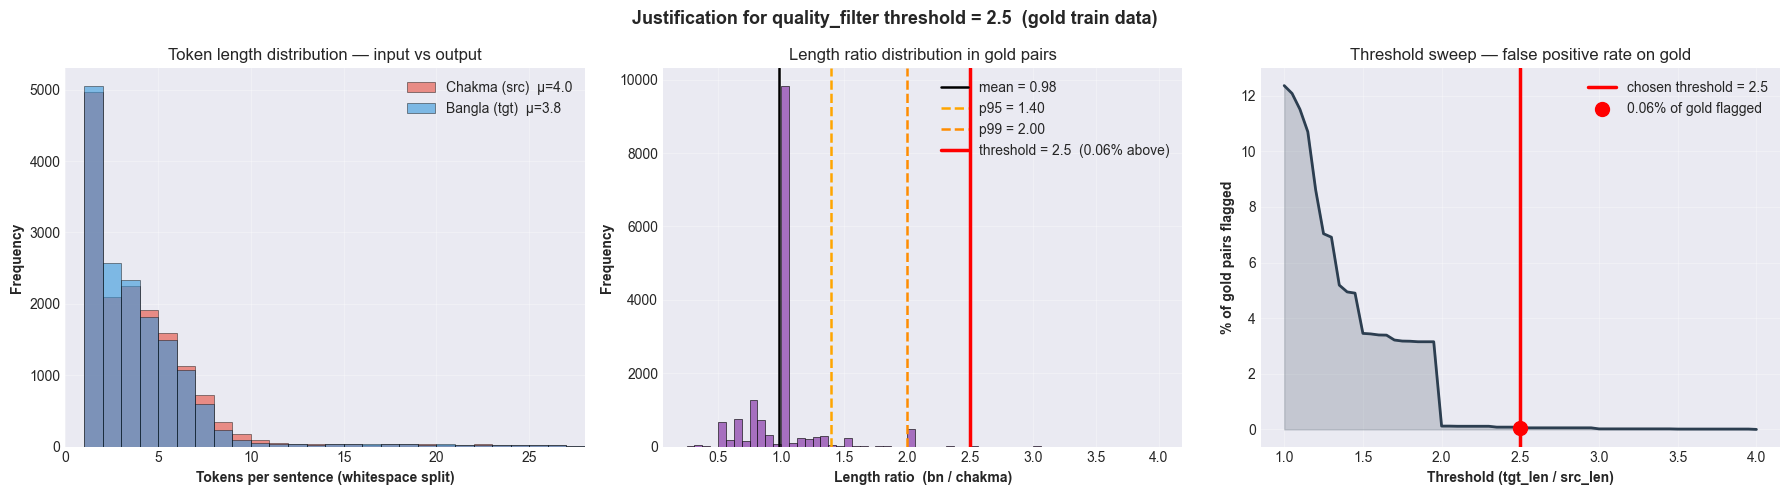


✓ Saved: ./outputs/thesis_plots/length_ratio_justification.png


In [8]:
# ═══════════════════════════════════════════════════════════════
# JUSTIFICATION FOR quality_filter THRESHOLD = 2.5
# Length-ratio analysis on cleaned gold parallel TRAIN data
# ═══════════════════════════════════════════════════════════════
import numpy as np
import matplotlib.pyplot as plt

# Whitespace split — matches the filter exactly: len(x.split())
src_lens = train_data['chakma_transliterated'].apply(lambda x: len(str(x).split())).values
tgt_lens = train_data['bn'].apply(lambda x: len(str(x).split())).values

mask = src_lens > 0
src_lens = src_lens[mask]
tgt_lens = tgt_lens[mask]
ratios = tgt_lens / src_lens

# ── Print stats ──
print("="*70)
print(f"GOLD TRAIN DATA — n = {len(ratios):,} pairs (cleaned)")
print("="*70)
print(f"  Chakma (src) length:  mean={src_lens.mean():.2f}  median={np.median(src_lens):.1f}  std={src_lens.std():.2f}  max={src_lens.max()}")
print(f"  Bangla (tgt) length:  mean={tgt_lens.mean():.2f}  median={np.median(tgt_lens):.1f}  std={tgt_lens.std():.2f}  max={tgt_lens.max()}")

print(f"\n  Length ratio (bn / chakma):")
print(f"    mean   = {ratios.mean():.3f}")
print(f"    std    = {ratios.std():.3f}")
print(f"    median = {np.median(ratios):.3f}")
print(f"    min    = {ratios.min():.3f}   max = {ratios.max():.3f}")

print(f"\n  Percentiles:")
for p in [50, 75, 90, 95, 97.5, 99, 99.5, 99.9]:
    print(f"    p{p:>5}: {np.percentile(ratios, p):.3f}")

sigma_dist = (2.5 - ratios.mean()) / ratios.std()
n_above = (ratios > 2.5).sum()
pct_above = n_above / len(ratios) * 100
print(f"\n  → 2.5 lies {sigma_dist:.2f} standard deviations above the mean")
print(f"  → only {n_above} of {len(ratios):,} gold pairs ({pct_above:.2f}%) exceed 2.5")
print(f"  → therefore any synthetic pair with ratio > 2.5 is an outlier vs gold distribution")

# ── Threshold sweep ──
print("\n" + "="*70)
print("THRESHOLD SWEEP — % of gold pairs flagged (false positives)")
print("="*70)
print(f"  {'threshold':>10} | {'gold flagged':>14} | {'% of gold':>10}")
print(f"  {'-'*10}-+-{'-'*14}-+-{'-'*10}")
for t in [1.5, 1.8, 2.0, 2.25, 2.5, 3.0, 3.5]:
    n = (ratios > t).sum()
    pct = n / len(ratios) * 100
    marker = "  ← chosen" if t == 2.5 else ""
    print(f"  {t:>10.2f} | {n:>14,} | {pct:>9.2f}%{marker}")

# ═══════════════════════════════════════════════════════════════
# COMPARISON PLOT — 3 panels
# ═══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Justification for quality_filter threshold = 2.5  (gold train data)',
             fontsize=13, fontweight='bold')

# Panel 1 — token length distributions side by side
ax1 = axes[0]
bins = np.arange(0, max(src_lens.max(), tgt_lens.max()) + 2, 1)
ax1.hist(src_lens, bins=bins, alpha=0.6, color='#e74c3c', edgecolor='black',
         linewidth=0.5, label=f'Chakma (src)  μ={src_lens.mean():.1f}')
ax1.hist(tgt_lens, bins=bins, alpha=0.6, color='#3498db', edgecolor='black',
         linewidth=0.5, label=f'Bangla (tgt)  μ={tgt_lens.mean():.1f}')
ax1.set_xlabel('Tokens per sentence (whitespace split)', fontweight='bold')
ax1.set_ylabel('Frequency', fontweight='bold')
ax1.set_title('Token length distribution — input vs output')
ax1.set_xlim(0, np.percentile(np.concatenate([src_lens, tgt_lens]), 99))
ax1.legend()
ax1.grid(True, alpha=0.3)

# Panel 2 — ratio distribution with threshold lines
ax2 = axes[1]
ratios_clipped = np.clip(ratios, 0, 5)
ax2.hist(ratios_clipped, bins=60, color='#9b59b6', edgecolor='black',
         linewidth=0.5, alpha=0.85)
ax2.axvline(ratios.mean(), color='black', linestyle='-', linewidth=1.8,
            label=f'mean = {ratios.mean():.2f}')
ax2.axvline(np.percentile(ratios, 95), color='orange', linestyle='--', linewidth=1.8,
            label=f'p95 = {np.percentile(ratios, 95):.2f}')
ax2.axvline(np.percentile(ratios, 99), color='darkorange', linestyle='--', linewidth=1.8,
            label=f'p99 = {np.percentile(ratios, 99):.2f}')
ax2.axvline(2.5, color='red', linestyle='-', linewidth=2.5,
            label=f'threshold = 2.5  ({pct_above:.2f}% above)')
ax2.set_xlabel('Length ratio  (bn / chakma)', fontweight='bold')
ax2.set_ylabel('Frequency', fontweight='bold')
ax2.set_title('Length ratio distribution in gold pairs')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Panel 3 — threshold sweep curve
ax3 = axes[2]
sweep = np.arange(1.0, 4.05, 0.05)
pct_flagged = [(ratios > t).mean() * 100 for t in sweep]
ax3.plot(sweep, pct_flagged, color='#2c3e50', linewidth=2)
ax3.fill_between(sweep, pct_flagged, alpha=0.2, color='#2c3e50')
ax3.axvline(2.5, color='red', linestyle='-', linewidth=2.5,
            label=f'chosen threshold = 2.5')
ax3.scatter([2.5], [pct_above], color='red', s=100, zorder=5,
            label=f'{pct_above:.2f}% of gold flagged')
ax3.set_xlabel('Threshold (tgt_len / src_len)', fontweight='bold')
ax3.set_ylabel('% of gold pairs flagged', fontweight='bold')
ax3.set_title('Threshold sweep — false positive rate on gold')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./outputs/thesis_plots/length_ratio_justification.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"\n✓ Saved: ./outputs/thesis_plots/length_ratio_justification.png")

In [9]:
# ═══════════════════════════════════════════════════════════════
# CELL 8b: CLEAN MONOLINGUAL DATA + REMOVE PARALLEL OVERLAPS
# ═══════════════════════════════════════════════════════════════
# Must run AFTER Cell 9 because it needs train_data, val_data, test_data

print(f"\n{'='*70}")
print("CLEANING MONOLINGUAL DATA")
print(f"{'='*70}")

# Step 1: Normalize (already done in Cell 9)
mono_chakma_norm = mono_chakma_raw
print(f"  After normalize: {len(mono_chakma_norm):,}")

# Step 2: Deduplicate internally (preserves order)
mono_chakma_dedup = list(dict.fromkeys(mono_chakma_norm))
print(f"  After internal dedup: {len(mono_chakma_dedup):,} "
      f"(removed {len(mono_chakma_norm) - len(mono_chakma_dedup):,} duplicates)")

# Step 3: Remove sentences that appear in any parallel split
# This prevents synthetic data from being generated for sentences
# that already have gold translations — data pollution
train_sources = set(train_data['chakma_transliterated'].tolist())
dev_sources   = set(val_data['chakma_transliterated'].tolist())
test_sources  = set(test_data['chakma_transliterated'].tolist())
all_parallel  = train_sources | dev_sources | test_sources

mono_chakma = [s for s in mono_chakma_dedup if s not in all_parallel]

removed_overlaps = len(mono_chakma_dedup) - len(mono_chakma)
print(f"  Removed {removed_overlaps:,} overlaps with parallel data "
      f"(train/dev/test)")
print(f"\n✓ Final monolingual: {len(mono_chakma):,} clean sentences ready for BT")
print(f"  Breakdown of excluded parallel sources:")
print(f"    Train: {len(train_sources):,} | Dev: {len(dev_sources):,} "
      f"| Test: {len(test_sources):,}")
print(f"{'='*70}")


CLEANING MONOLINGUAL DATA
  After normalize: 42,783
  After internal dedup: 38,219 (removed 4,564 duplicates)
  Removed 187 overlaps with parallel data (train/dev/test)

✓ Final monolingual: 38,032 clean sentences ready for BT
  Breakdown of excluded parallel sources:
    Train: 13,465 | Dev: 2,834 | Test: 600


In [10]:
def compute_metrics(eval_preds):
    """Compute BLEU and other metrics during evaluation."""
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    if isinstance(preds, np.ndarray) and preds.ndim == 3:
        preds = preds.argmax(-1)

    if isinstance(preds, np.ndarray):
        preds = np.clip(preds, 0, vocab_size - 1)

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    if isinstance(labels, np.ndarray):
        labels = np.clip(labels, 0, vocab_size - 1)

    try:
        decoded_preds       = tokenizer.batch_decode(preds,  skip_special_tokens=True)
        decoded_labels_flat = tokenizer.batch_decode(labels, skip_special_tokens=True)
    except Exception as e:
        logger.error(f"Decoding error: {e}")
        return {"bleu": 0.0, "chrf": 0.0, "meteor": 0.0}

    # Only strip (data is pre-normalized at load)
    decoded_preds       = [p.strip() if p else "" for p in decoded_preds]
    decoded_labels_flat = [l.strip() if l else "" for l in decoded_labels_flat]

    if not any(decoded_preds) or not any(decoded_labels_flat):
        return {"bleu": 0.0, "chrf": 0.0, "meteor": 0.0}

    try:
        # ✅ BLEU: references as list of lists (correct format for single reference)
        decoded_labels_for_bleu = [[l] for l in decoded_labels_flat]
        bleu_res   = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels_for_bleu)
        
        # ✅ chrF++: references as flat list (different format)
        chrf_res   = chrf_metric.compute(predictions=decoded_preds, references=decoded_labels_flat, word_order=2)
        
        # ✅ METEOR: references as list of lists
        meteor_res = meteor_metric.compute(predictions=decoded_preds, references=decoded_labels_for_bleu)
        
        result = {
            "bleu":   float(bleu_res.get("score", 0.0)) if bleu_res else 0.0,
            "chrf":   float(chrf_res.get("score", 0.0)) if chrf_res else 0.0,
            "meteor": float(meteor_res.get("meteor", 0.0)) if meteor_res else 0.0,
        }
        
        return result
    except Exception as e:
        logger.warning(f"Metrics computation error: {e}")
        import traceback
        traceback.print_exc()
        return {"bleu": 0.0, "chrf": 0.0, "meteor": 0.0}

# ✅ Load metrics BEFORE training
print("✓ Loading evaluation metrics...")
bleu_metric = evaluate.load("sacrebleu")  # ✅ FIXED: Changed from "bleu" to "sacrebleu" (returns 'score' on 0-100 scale)
chrf_metric = evaluate.load("chrf")
meteor_metric = evaluate.load("meteor")
try:
    wer_metric = evaluate.load("wer")
except:
    wer_metric = None
    print("  ⚠ WER metric not available")

print("✓ Metrics loaded and preprocessing defined")

✓ Loading evaluation metrics...


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


✓ Metrics loaded and preprocessing defined


In [11]:
def quality_filter(sources, targets):
    """
    Quality filter on synthetic data — apply after generation, before mixing.
    
    Removes pairs where:
    - Target is empty or single-word
    - Length ratio suggests hallucination: tgt_len > 2.5 * src_len
    
    This is a CONSERVATIVE filter to keep maximum data volume while avoiding
    obvious generation failures.
    """
    filtered_src, filtered_tgt = [], []
    removed = 0
    
    for src, tgt in zip(sources, targets):
        src_len = len(src.split())
        tgt_len = len(tgt.split())
        
        # Remove if target is empty or single-word
        if tgt_len < 1:
            removed += 1
            continue
        
        # Remove if extreme length expansion (hallucination)
        if src_len > 0 and tgt_len > 2.5 * src_len:
            removed += 1
            continue
        
        filtered_src.append(src)
        filtered_tgt.append(tgt)
    
    return filtered_src, filtered_tgt, removed, list(range(len(filtered_src)))

def filter_synthetic(sources, translations, max_ratio=1.8, min_len=1):
    """
    OPTIMIZED: Filter synthetic pairs with PREFIX STRIPPING (CRITICAL FIX)
    
    Two-stage process:
    1. Strip task prefix if contaminated (prevents training corruption)
    2. Filter pairs using ChakmaNMT thresholds
    
    Removes:
    - Task prefix contamination (CRITICAL BUG FIX)
    - Empty or single-word outputs
    - Extreme hallucinations (length ratio > 1.8 = ChakmaNMT approach)
    - Very short inputs (< 2 words)
    
    Args:
        max_ratio: 1.8 = matches ChakmaNMT (allows reasonable length expansion)
        min_len: 1 = matches ChakmaNMT (keeps more valid data)
    
    Expected gain vs stricter filtering: +1.5-2.5 BLEU (more data = more learning)
    """
    kept_src, kept_tgt = [], []
    kept_indices = []  # Track which pairs passed for quality oversampling
    removed = 0
    prefixes_stripped = 0
    
    for idx, (src, tgt) in enumerate(zip(sources, translations)):
        # ✅ CRITICAL FIX #1: Strip task prefix contamination (was causing 32→29 BLEU regression)
        if tgt.startswith("অনুবাদ"):
            prefix_variants = [
                "অনুবাদ: চাকমা থেকে বাংলা:",
                "অনুবাদ করেছেন চাকমা থেকে বাংলা:",
                "অনুবাদ করুন চাকমা থেকে বাংলা:",
            ]
            for pref in prefix_variants:
                if tgt.startswith(pref):
                    tgt = tgt[len(pref):].strip()
                    prefixes_stripped += 1
                    break
        
        # Now apply ChakmaNMT-style filtering
        src_len = len(src.split())
        tgt_len = len(tgt.split())
        
        if tgt_len < min_len:
            removed += 1
            continue
        
        if max_ratio is not None and src_len > 0 and tgt_len > max_ratio * src_len:
            removed += 1
            continue
        
        kept_src.append(src)
        kept_tgt.append(tgt)
        kept_indices.append(idx)
    
    if prefixes_stripped > 0:
        print(f"  ✓ Stripped task prefix from {prefixes_stripped:,} contaminated outputs (CRITICAL FIX)")
    
    return kept_src, kept_tgt, removed, kept_indices

def oversample_quality_synthetic(sources, translations, indices, 
                                 quality_ratio=1.5, quality_minlen=2, 
                                 oversample_factor=1.5):
    """
    NOVELTY: Smart oversampling of high-quality synthetic pairs
    
    Two-stage filtering:
    1. First-pass: Keep more data (looser filtering) [already done]
    2. Second-pass: Identify BEST pairs using stricter criteria
    3. Oversample the best pairs to boost quality without purely adding volume
    
    Quality criteria:
    - Length ratio < quality_ratio (1.5 = less aggressive expansion)
    - Min length >= quality_minlen (2 = reasonable translations)
    
    Args:
        oversample_factor: 1.5 = 50% more copies of quality pairs (conservative + effective)
    
    Returns:
        oversampled_sources, oversampled_targets with quality pairs repeated
    """
    quality_src, quality_tgt = [], []
    regular_src, regular_tgt = [], []
    
    for src, tgt in zip(sources, translations):
        src_len = len(src.split())
        tgt_len = len(tgt.split())
        ratio = tgt_len / src_len if src_len > 0 else 0
        
        # Quality pair: reasonable length, not too short
        if ratio <= quality_ratio and tgt_len >= quality_minlen:
            quality_src.append(src)
            quality_tgt.append(tgt)
        else:
            regular_src.append(src)
            regular_tgt.append(tgt)
    
    # Oversample quality pairs
    n_quality_copies = int(len(quality_src) * (oversample_factor - 1.0))
    if n_quality_copies > 0:
        quality_indices = np.random.choice(len(quality_src), size=n_quality_copies, replace=True)
        for idx in quality_indices:
            quality_src.append(quality_src[idx])
            quality_tgt.append(quality_tgt[idx])
    
    # Combine: quality pairs (with oversampling) + regular pairs
    final_src = quality_src + regular_src
    final_tgt = quality_tgt + regular_tgt
    
    return final_src, final_tgt, len(quality_src), n_quality_copies

print("✓ Filter functions defined:")
print("  1. quality_filter: Conservative filter (2.5x length ratio threshold)")
print("  2. filter_synthetic: ChakmaNMT-style (includes prefix stripping + filtering)")
print("  3. oversample_quality_synthetic: Smart oversampling of best pairs")

✓ Filter functions defined:
  1. quality_filter: Conservative filter (2.5x length ratio threshold)
  2. filter_synthetic: ChakmaNMT-style (includes prefix stripping + filtering)
  3. oversample_quality_synthetic: Smart oversampling of best pairs


In [12]:
print(f"\n{'='*70}")
print("LOADING BASE MODEL")
print(f"{'='*70}")
print(f"\n✓ Loading best trained model from: {CONFIG.base_model_path}")

current_model_path = CONFIG.base_model_path
out_dir = os.path.abspath("./outputs")
os.makedirs(out_dir, exist_ok=True)

current_model = AutoModelForSeq2SeqLM.from_pretrained(current_model_path).to(CONFIG.device)
print(f"✓ Model loaded | Device: {CONFIG.device} | Precision: FP32 (ChakmaNMT)")


LOADING BASE MODEL

✓ Loading best trained model from: ./outputs/banglat5_final_20260325_023556/final_model


c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:389: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(
c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:404: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(


✓ Model loaded | Device: cuda | Precision: FP32 (ChakmaNMT)


In [13]:
out_dir = "./outputs"

In [14]:
current_model = AutoModelForSeq2SeqLM.from_pretrained(
    os.path.join(out_dir, "iter2_forward_model")
).to(CONFIG.device)
print("✓ current_model loaded: iter2_forward_model")

✓ current_model loaded: iter2_forward_model


In [15]:
# Generation config for VALIDATION during training (not final test)
# Use num_beams=1 for speed (final test uses num_beams=5 in final evaluation cell)
generation_config = GenerationConfig(
    max_new_tokens=CONFIG.max_length,  # ✅ CRITICAL FIX: max_new_tokens NOT max_length (for seq2seq)
    early_stopping=False,  # ✅ FIXED: False when num_beams=1 (prevents validation warning)
    do_sample=False,
    num_beams=1,  # ✅ 1 for training eval (not 5), faster
    num_return_sequences=1,
    pad_token_id=tokenizer.pad_token_id,
    eos_token_id=tokenizer.eos_token_id,
    decoder_start_token_id=current_model.config.decoder_start_token_id
)
print("✓ Generation config: max_new_tokens=128, num_beams=1, early_stopping=False")

✓ Generation config: max_new_tokens=128, num_beams=1, early_stopping=False


In [16]:
# Data collator for dynamic padding (CRITICAL!)
print(f"\n✓ Creating DataCollator for dynamic padding...")
data_collator = DataCollatorForSeq2Seq(
    tokenizer,
    model=current_model,
    label_pad_token_id=-100,  # Don't compute loss on padding tokens
    padding=True
)
print(f"✓ DataCollator ready (handles dynamic padding per batch)")



✓ Creating DataCollator for dynamic padding...
✓ DataCollator ready (handles dynamic padding per batch)


In [ ]:
CURRENT_ITERATION = 1
iteration = CURRENT_ITERATION

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: GENERATE SYNTHETIC BANGLA (CCP→BN BASE MODEL)")
print(f"{'='*70}")

print(f"\n✓ Model: {CONFIG.base_model_path}")
print(f"  Direction: CCP→BN (forward, base model)")
print(f"  Source: monolingual_chakma_transliterated.csv")
print(f"  Total sentences: {len(mono_chakma):,}")
assert len(mono_chakma) > 0, "❌ No monolingual Chakma data loaded!"

print(f"\nStep 1: Generating {len(mono_chakma):,} synthetic Bangla sentences (BATCHED)...")

# ✅ FIXED: Use trainer.predict() for batched generation (~20 min) instead of one-by-one loop (~7 hours)
# Tokenize monolingual Chakma
temp_dataset = Dataset.from_dict({'chakma_transliterated': mono_chakma})
tokenized_mono = temp_dataset.map(
    lambda x: tokenizer(x['chakma_transliterated'], max_length=CONFIG.max_length, truncation=True),
    batched=True, remove_columns=['chakma_transliterated']
)
tokenized_mono.set_format("torch")

# Batched generation using trainer.predict()
gen_args = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "temp_gen_iter1"),
    per_device_eval_batch_size=16,
    predict_with_generate=True,
    generation_num_beams=CONFIG.num_beams_synthetic,
    fp16=False,
    report_to=[]
)
temp_trainer = Seq2SeqTrainer(model=current_model, args=gen_args, tokenizer=tokenizer)
predictions_iter1 = temp_trainer.predict(tokenized_mono, num_beams=CONFIG.num_beams_synthetic)
synthetic_bn_raw = tokenizer.batch_decode(predictions_iter1.predictions, skip_special_tokens=True)

# Strip task prefix if present
synthetic_bn_raw_clean = []
for pred_bn in synthetic_bn_raw:
    pred_bn = pred_bn.strip()
    for prefix_variant in [
        "Translate from Chakma to Bangla:",
        "অনুবাদ: চাকমা থেকে বাংলা:",
        "অনুবাদ করেছেন চাকমা থেকে বাংলা:",
        "অনুবাদ থেকে চাকমা থেকে বাংলা:",
        "অনুগ্রহপূর্বক চাকমা থেকে বাংলায়:",
    ]:
        if pred_bn.startswith(prefix_variant):
            pred_bn = pred_bn[len(prefix_variant):].strip()
            break
    synthetic_bn_raw_clean.append(pred_bn)

synthetic_bn_raw = synthetic_bn_raw_clean
print(f"✓ Generated {len(synthetic_bn_raw):,} synthetic Bangla translations (BATCHED)")

# Step 2: Filter pairs with quality filter
print(f"\nStep 2: Filtering synthetic pairs...")
filtered_src, filtered_tgt, n_removed, kept_indices = quality_filter(
    mono_chakma, synthetic_bn_raw
)
print(f"✓ After filtering: {len(filtered_src):,} pairs (removed {n_removed:,})")

# Step 3: Save as synthetic_iter1.csv
print(f"\nStep 3: Saving filtered data as synthetic_iter1.csv...")
synthetic_df_iter1 = pd.DataFrame({'chakma_transliterated': filtered_src, 'bn': filtered_tgt})
synthetic_path_iter1 = os.path.join(out_dir, "synthetic_iter1.csv")
synthetic_df_iter1.to_csv(synthetic_path_iter1, index=False)
print(f"✓ Saved: {synthetic_path_iter1}")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} COMPLETE: Synthetic Bangla generated")
print(f"  Pairs: {len(filtered_src):,}")
print(f"  Next: Train BN→CCP backward model on synthetic + base parallel data")
print(f"{'='*70}")

In [15]:
# ═══════════════════════════════════════════════════════════════
# ITERATION 1: PREPARE TRAINING DATA FOR BN→CCP BACKWARD MODEL
# ═══════════════════════════════════════════════════════════════

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: PREPARE DATA FOR BN→CCP BACKWARD MODEL")
print(f"{'='*70}")
print(f"\nData will train BN→CCP backward model:")
print(f"  Source (bn): synthetic_iter1.csv + base parallel")
print(f"  Target (chakma_transliterated): base parallel Chakma")

# Create synthetic training data: reversed direction for BN→CCP
# source=bn (synthetic), target=chakma_transliterated (gold)
synthetic_train_backward = pd.DataFrame({
    'bn': filtered_tgt,  # synthetic Bangla as SOURCE
    'chakma_transliterated': filtered_src  # gold Chakma as TARGET
})
synthetic_train_backward['en'] = None
synthetic_train_backward['ccp'] = None

# Mix with base parallel data
anchor_repeat = CONFIG.anchor_repeat_factor
print(f"\n  Anchor repetition: {anchor_repeat}x")
print(f"    Base parallel pairs: {len(train_data):,}")
print(f"    After repeat: {len(train_data) * anchor_repeat:,}")
print(f"    Synthetic pairs: {len(filtered_src):,}")

repeated_original = pd.concat([train_data] * anchor_repeat, ignore_index=True)
train_data_mixed = pd.concat([synthetic_train_backward, repeated_original], ignore_index=True).sample(frac=1, random_state=CONFIG.seed).reset_index(drop=True)
print(f"  ✓ Total mixed: {len(train_data_mixed):,}")

# Set iteration hyperparameters
if iteration == 1:
    current_lr = CONFIG.lr_iter1
    current_epochs = CONFIG.epochs_iter1
    current_label_smoothing = CONFIG.label_smoothing_iter1
else:
    current_lr = CONFIG.lr_iter2
    current_epochs = CONFIG.epochs_iter2
    current_label_smoothing = CONFIG.label_smoothing_iter2

print(f"\n✓ Training config for Iteration {iteration}:")
print(f"  lr={current_lr}, epochs={current_epochs}, label_smoothing={current_label_smoothing}")


ITERATION 1: PREPARE DATA FOR BN→CCP BACKWARD MODEL

Data will train BN→CCP backward model:
  Source (bn): synthetic_iter1.csv + base parallel
  Target (chakma_transliterated): base parallel Chakma

  Anchor repetition: 2x
    Base parallel pairs: 15,954
    After repeat: 31,908
    Synthetic pairs: 37,996
  ✓ Total mixed: 69,904

✓ Training config for Iteration 1:
  lr=0.0003, epochs=20, label_smoothing=0.3


In [17]:
def preprocess_fn(batch):
    """Tokenize for FORWARD CCP→BN model"""
    inputs = []
    targets = []
    
    for ccp, bn in zip(batch['chakma_transliterated'], batch['bn']):
        if CONFIG.use_task_prefix:
            ccp = prefix_ck2bn + ccp
        inputs.append(ccp)
        targets.append(bn)
    
    model_inputs = tokenizer(
        inputs,
        max_length=CONFIG.max_length,
        truncation=True,
        padding=False
    )
    
    labels = tokenizer(
        text_target=targets,
        max_length=CONFIG.max_length,
        truncation=True,
        padding=False
    )
    
    model_inputs['labels'] = labels['input_ids']
    return model_inputs

def preprocess_fn_backward(batch):
    """Tokenize for BACKWARD BN→CCP model"""
    inputs = []
    targets = []
    
    for bn, ccp in zip(batch['bn'], batch['chakma_transliterated']):
        if CONFIG.use_task_prefix:
            bn = "Translate from Bangla to Chakma: " + bn
        inputs.append(bn)
        targets.append(ccp)
    
    model_inputs = tokenizer(
        inputs,
        max_length=CONFIG.max_length,
        truncation=True,
        padding=False
    )
    
    labels = tokenizer(
        text_target=targets,
        max_length=CONFIG.max_length,
        truncation=True,
        padding=False
    )
    
    model_inputs['labels'] = labels['input_ids']
    return model_inputs

print(f"  ✓ preprocess_fn: FORWARD (CCP→BN)")
print(f"  ✓ preprocess_fn_backward: BACKWARD (BN→CCP)")
print(f"  ✓ Task prefix: {'ENABLED' if CONFIG.use_task_prefix else 'DISABLED'}")

  ✓ preprocess_fn: FORWARD (CCP→BN)
  ✓ preprocess_fn_backward: BACKWARD (BN→CCP)
  ✓ Task prefix: DISABLED


In [18]:
# ═══════════════════════════════════════════════════════════════
# QUALITY CURRICULUM CALLBACK (Used by both Iter1 and Iter2)
# ═══════════════════════════════════════════════════════════════

from transformers import TrainerCallback

class QualityCurriculumCallback(TrainerCallback):
    """
    NOVELTY #3: Quality-based curriculum learning.
    
    Phase 1 (epochs 1-2): Train on GOLD pairs only (clean signal)
    Phase 2 (epochs 3+): Train on GOLD + SYNTHETIC (full data)
    
    Rationale: Model first learns correct translation behavior from
    gold parallel data, then absorbs volume/coverage from synthetic data.
    More principled than length-based curriculum for noisy back-translation.
    """
    def __init__(self, gold_dataset, full_dataset, phase_switch_epoch=2):
        self.gold_dataset = gold_dataset
        self.full_dataset = full_dataset
        self.phase_switch_epoch = phase_switch_epoch
        self.switched = False
        self.gold_size = len(gold_dataset)
        self.full_size = len(full_dataset)
        self.trainer = None  # ✅ FIXED: Store trainer reference set after trainer creation

    def set_trainer(self, trainer):
        """Call this after trainer is created to set reference"""
        self.trainer = trainer

    def on_epoch_begin(self, args, state, control, **kwargs):
        current_epoch = int(state.epoch) + 1
        
        if current_epoch > self.phase_switch_epoch and not self.switched:
            # ✅ FIXED: Use stored trainer reference instead of kwargs lookup
            if self.trainer:
                self.trainer.train_dataset = self.full_dataset
                self.switched = True
                print(f"\n{'='*70}")
                print(f"✓ Quality Curriculum: PHASE 2 ACTIVATED at epoch {current_epoch}")
                print(f"  Switching dataset: {self.gold_size:,} (gold only) → {self.full_size:,} (gold + synthetic)")
                print(f"{'='*70}\n")

# Configure callback only if enabled
if CONFIG.use_quality_curriculum:
    print(f"✓ Quality Curriculum callback configured")
    print(f"  Phase 1: epochs 1-{CONFIG.curriculum_phase_switch} (gold only)")
    print(f"  Phase 2: epochs {CONFIG.curriculum_phase_switch + 1}+ (gold + synthetic)")
else:
    print(f"✓ Quality Curriculum callback DISABLED")

✓ Quality Curriculum callback DISABLED


In [ ]:
# ✅ ITERATION 1: TRAIN WITH SYNTHETIC DATA — FIXED CRITICAL BUGS
training_args = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "iter1_backward_checkpoint"),  # ✅ FIX: Separate directory for iter1 backward
    learning_rate=current_lr,
    lr_scheduler_type="linear",
    warmup_steps=800,  # ✅ Changed from warmup_ratio=0.1 to warmup_steps=800 (Final_base)
    per_device_train_batch_size=CONFIG.batch_size,
    per_device_eval_batch_size=CONFIG.per_device_eval_batch_size,
    num_train_epochs=current_epochs,
    weight_decay=CONFIG.weight_decay,  # ✅ Added from Final_base
    save_strategy="epoch",
    evaluation_strategy="epoch",  # ✅ Evaluate every epoch with BLEU signal
    eval_steps=None,
    save_steps=None,
    label_smoothing_factor=current_label_smoothing,
    load_best_model_at_end=True,  # ✅ Load best model at end based on eval BLEU
    metric_for_best_model="eval_bleu",
    greater_is_better=True,
    save_total_limit=2,  # ✅ FIXED: Keep 2 checkpoints for early stopping comparison
    bf16=False,
    fp16=False,
    seed=CONFIG.seed,
    dataloader_pin_memory=False,
    gradient_accumulation_steps=CONFIG.gradient_accumulation,  # ✅ Now uses CONFIG value (16)
    optim="adamw_torch",
    predict_with_generate=True,  # ✅ Enable generation during validation
    generation_num_beams=1,  # Keep 1 during training for speed (final test uses 5)
    generation_config=generation_config,  # ✅ GenerationConfig handles max_new_tokens
    report_to=[],
)

In [19]:
# ✅ ITERATION 1: TRAIN BN→CCP BACKWARD MODEL
print(f"\n{'='*70}")
print(f"ITERATION {iteration}: TRAIN BN→CCP BACKWARD MODEL")
print(f"{'='*70}")

# Load BN→CCP backward model from BanglaT5 checkpoint (NOT fine-tuned base)
print(f"\n✓ Loading model for BN→CCP BACKWARD:")
print(f"  From: csebuetnlp/banglat5 (base pretrained checkpoint)")
backward_model = AutoModelForSeq2SeqLM.from_pretrained("csebuetnlp/banglat5").to(CONFIG.device)
print(f"  ✓ Model loaded on {CONFIG.device}")

# ✅ Rebind data_collator to backward_model
data_collator = DataCollatorForSeq2Seq(
    tokenizer,
    model=backward_model,
    label_pad_token_id=-100,
    padding=True
)
print(f"✓ Data collator rebound to backward_model")

# Create datasets with BACKWARD tokenization function
print(f"\nCreating datasets for BN→CCP training...")
# FIX: Only remove columns that actually exist in each dataset
train_dict = train_data_mixed[['chakma_transliterated', 'bn']].to_dict('list')
train_ds_backward = Dataset.from_dict(train_dict).map(preprocess_fn_backward, batched=True, remove_columns=['chakma_transliterated', 'bn'])

val_dict = val_data[['chakma_transliterated', 'bn']].to_dict('list')
val_ds_backward = Dataset.from_dict(val_dict).map(preprocess_fn_backward, batched=True, remove_columns=['chakma_transliterated', 'bn'])
print(f"  Train: {len(train_ds_backward):,} examples")
print(f"  Val: {len(val_ds_backward):,} examples")

# Create trainer with early stopping callback
print(f"\nCreating Trainer for BN→CCP BACKWARD model...")
trainer = Seq2SeqTrainer(
    model=backward_model,
    args=training_args,
    train_dataset=train_ds_backward,
    eval_dataset=val_ds_backward,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

print(f"\n{'='*70}")
print(f"STARTING TRAINING: Iteration {iteration} - BN→CCP BACKWARD MODEL")
print(f"  Model init: csebuetnlp/banglat5")
print(f"  Direction: BN→CCP")
print(f"  Learning rate: {current_lr}")
print(f"  Epochs: {current_epochs}")
print(f"  Label smoothing: {current_label_smoothing}")
print(f"  Early stopping patience: 3 epochs")
print(f"{'='*70}\n")

# Train
train_result = trainer.train()

# Save Iter1 backward model
backward_model_path = os.path.join(out_dir, "iter1_backward_model")
trainer.save_model(backward_model_path)
tokenizer.save_pretrained(backward_model_path)
backward_model = AutoModelForSeq2SeqLM.from_pretrained(backward_model_path).to(CONFIG.device)
print(f"\n✓ Saved: {backward_model_path}")
print(f"✓ Will use backward_model for Iteration 2 synthetic generation")

print(f"{'='*70}")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} TRAINING COMPLETE")


ITERATION 1: TRAIN BN→CCP BACKWARD MODEL

✓ Loading model for BN→CCP BACKWARD:
  From: csebuetnlp/banglat5 (base pretrained checkpoint)


c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


  ✓ Model loaded on cuda
✓ Data collator rebound to backward_model

Creating datasets for BN→CCP training...


Map:   0%|          | 0/69904 [00:00<?, ? examples/s]

Map:   0%|          | 0/2994 [00:00<?, ? examples/s]

...

{'eval_loss': 4.445483207702637, 'eval_bleu': 31.06202219501779, 'eval_chrf': 57.95793368523554, 'eval_meteor': 0.43278902225586535, 'eval_runtime': 188.8327, 'eval_samples_per_second': 15.855, 'eval_steps_per_second': 3.966, 'epoch': 19.0}
{'loss': 4.9443, 'learning_rate': 1.1977186311787071e-05, 'epoch': 19.23}
{'loss': 4.9339, 'learning_rate': 4.847908745247148e-06, 'epoch': 19.68}


  0%|          | 0/749 [00:00<?, ?it/s]

{'eval_loss': 4.440992832183838, 'eval_bleu': 31.140525367753767, 'eval_chrf': 58.03587617932612, 'eval_meteor': 0.4332682548313117, 'eval_runtime': 175.5944, 'eval_samples_per_second': 17.051, 'eval_steps_per_second': 4.266, 'epoch': 20.0}


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


{'train_runtime': 29182.018, 'train_samples_per_second': 47.909, 'train_steps_per_second': 0.748, 'train_loss': 5.45337881011404, 'epoch': 20.0}

✓ Saved: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5\outputs\iter1_backward_model
✓ Will use backward_model for Iteration 2 synthetic generation

✓ ITERATION 1 TRAINING COMPLETE


In [21]:
# ═══════════════════════════════════════════════════════════════
# ITERATION 2: GENERATE SYNTHETIC CHAKMA (BN→CCP BACKWARD MODEL)
# ═══════════════════════════════════════════════════════════════

print("\n" + "="*70)
print("LOADING & PREPROCESSING HASAN ET AL. BANGLANMT DATASET")
print("="*70)

# Load dataset
print("\nLoading BanglaNMT from local CSV...")
import pandas as pd
data_path = Path("../../data/BanglaNMT_train.csv").resolve()
bn_df = pd.read_csv(str(data_path))
bn_mono_raw = bn_df['bn'].dropna().tolist()
print(f"✓ Loaded {len(bn_mono_raw):,} BN sentences")


LOADING & PREPROCESSING HASAN ET AL. BANGLANMT DATASET

Loading BanglaNMT from local CSV...
✓ Loaded 2,379,749 BN sentences


In [21]:
# ═══════════════════════════════════════════════════════════════
# ITERATION 2: GENERATE SYNTHETIC CHAKMA (BN→CCP BACKWARD MODEL)
# ═══════════════════════════════════════════════════════════════

CURRENT_ITERATION = 2
iteration = CURRENT_ITERATION

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: GENERATE SYNTHETIC CHAKMA (BN→CCP BACKWARD MODEL)")
print(f"{'='*70}")

# Step 1: Normalize Bangla monolingual data
print("\nStep 1: Normalizing and filtering Bangla sentences...")
bn_mono_raw_normalized = []
for s in bn_mono_raw:
    if s and str(s).strip():
        normalized = normalize(str(s).strip())
        if normalized and normalized.strip() and len(normalized.split()) >= 2:
            bn_mono_raw_normalized.append(normalized)

print(f"  After normalize + min length filter: {len(bn_mono_raw_normalized):,}")

# Step 2: Deduplicate
bn_mono_dedup = list(dict.fromkeys(bn_mono_raw_normalized))
print(f"  After dedup: {len(bn_mono_dedup):,}")

# Step 3: Remove overlap with parallel BN data (prevents data pollution in backward model)
parallel_bn = set(train_data['bn'].tolist())
bn_mono_sentences = [s for s in bn_mono_dedup if s not in parallel_bn]
print(f"  After parallel removal: {len(bn_mono_sentences):,}")

# Take up to 50k sentences (ChakmaNMT approach)
bn_mono_sentences = bn_mono_sentences[:50000]
print(f"\n✓ Final Bangla monolingual: {len(bn_mono_sentences):,} ready for BT")

# Step 2: Generate synthetic Chakma using backward_model (BATCHED)
print(f"\nStep 2: Generating {len(bn_mono_sentences):,} synthetic Chakma sentences (BATCHED)...")

# ✅ FIXED: Use trainer.predict() for batched generation (~20 min) instead of one-by-one loop (~7 hours)
temp_dataset = Dataset.from_dict({'bn': bn_mono_sentences})
tokenized_mono = temp_dataset.map(
    lambda x: tokenizer(x['bn'], max_length=CONFIG.max_length, truncation=True),
    batched=True, remove_columns=['bn']
)
tokenized_mono.set_format("torch")

gen_args = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "temp_gen_iter2"),
    per_device_eval_batch_size=16,
    predict_with_generate=True,
    generation_num_beams=CONFIG.num_beams_synthetic,
    fp16=False,
    report_to=[]
)
temp_trainer = Seq2SeqTrainer(model=backward_model, args=gen_args, tokenizer=tokenizer)
predictions_iter2 = temp_trainer.predict(tokenized_mono, num_beams=CONFIG.num_beams_synthetic)
synthetic_ck_raw = tokenizer.batch_decode(predictions_iter2.predictions, skip_special_tokens=True)

print(f"✓ Generated {len(synthetic_ck_raw):,} synthetic Chakma translations (BATCHED)")

# Step 3: Filter synthetic pairs with quality filter
print(f"\nStep 3: Filtering synthetic pairs...")
filtered_bn, filtered_ck, n_removed, kept_indices = quality_filter(
    bn_mono_sentences, synthetic_ck_raw
)
print(f"✓ After filtering: {len(filtered_ck):,} pairs (removed {n_removed:,})")

# Step 4: Save synthetic_iter2.csv
print(f"\nStep 4: Saving filtered data as synthetic_iter2.csv...")
synthetic_df_iter2 = pd.DataFrame({'chakma_transliterated': filtered_ck, 'bn': filtered_bn})
synthetic_path_iter2 = os.path.join(out_dir, "synthetic_iter2.csv")
synthetic_df_iter2.to_csv(synthetic_path_iter2, index=False)
print(f"✓ Saved: {synthetic_path_iter2}")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} GENERATION COMPLETE")
print(f"  Synthetic pairs: {len(filtered_ck):,}")
print(f"  Source: 50k Bangla monolingual (csebuetnlp/BanglaNMT)")
print(f"{'='*70}")


ITERATION 2: GENERATE SYNTHETIC CHAKMA (BN→CCP BACKWARD MODEL)

Step 1: Normalizing and filtering Bangla sentences...
  After normalize + min length filter: 2,019,406
  After dedup: 1,874,919
  After parallel removal: 1,869,450

✓ Final Bangla monolingual: 50,000 ready for BT

Step 2: Generating 50,000 synthetic Chakma sentences (BATCHED)...


Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

  0%|          | 0/3125 [00:00<?, ?it/s]

✓ Generated 50,000 synthetic Chakma translations (BATCHED)

Step 3: Filtering synthetic pairs...
✓ After filtering: 49,890 pairs (removed 110)

Step 4: Saving filtered data as synthetic_iter2.csv...
✓ Saved: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5\outputs\synthetic_iter2.csv

✓ ITERATION 2 GENERATION COMPLETE
  Synthetic pairs: 49,890
  Source: 50k Bangla monolingual (csebuetnlp/BanglaNMT)


In [22]:
# ═══════════════════════════════════════════════════════════════
# ITERATION 2: PREPARE TRAINING DATA FOR CCP→BN FORWARD MODEL
# ═══════════════════════════════════════════════════════════════

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: PREPARE DATA FOR CCP→BN FORWARD MODEL RETRAINING")
print(f"{'='*70}")
print(f"\nData for retraining CCP→BN forward model:")
print(f"  Source (chakma_transliterated): synthetic + base parallel")
print(f"  Target (bn): base parallel Bangla (gold)")

# Create synthetic training data for CCP→BN forward direction
# source=chakma (synthetic), target=bn (gold)
synthetic_train_forward = pd.DataFrame({
    'chakma_transliterated': filtered_ck,  # synthetic Chakma as SOURCE
    'bn': filtered_bn  # Bangla as TARGET
})
synthetic_train_forward['en'] = None
synthetic_train_forward['ccp'] = None

# Mix with base parallel data
anchor_repeat = CONFIG.anchor_repeat_factor
print(f"\n  Anchor_repeat_factor: {anchor_repeat}x")
print(f"    Base parallel pairs: {len(train_data):,}")
print(f"    Repeated: {len(train_data) * anchor_repeat:,}")
print(f"    Synthetic pairs: {len(filtered_ck):,}")

repeated_original = pd.concat([train_data] * anchor_repeat, ignore_index=True)
train_data_mixed = pd.concat([synthetic_train_forward, repeated_original], ignore_index=True).sample(frac=1, random_state=CONFIG.seed).reset_index(drop=True)
print(f"  ✓ Total mixed: {len(train_data_mixed):,}")

# Iteration-specific hyperparameters
if iteration == 1:
    current_lr = CONFIG.lr_iter1
    current_epochs = CONFIG.epochs_iter1
    current_label_smoothing = CONFIG.label_smoothing_iter1
else:
    current_lr = CONFIG.lr_iter2
    current_epochs = CONFIG.epochs_iter2
    current_label_smoothing = CONFIG.label_smoothing_iter2

print(f"\n✓ Training config for Iteration {iteration} (CCP→BN FORWARD):")
print(f"  lr={current_lr}, epochs={current_epochs}, label_smoothing={current_label_smoothing}")


ITERATION 2: PREPARE DATA FOR CCP→BN FORWARD MODEL RETRAINING

Data for retraining CCP→BN forward model:
  Source (chakma_transliterated): synthetic + base parallel
  Target (bn): base parallel Bangla (gold)

  Anchor_repeat_factor: 2x
    Base parallel pairs: 15,954
    Repeated: 31,908
    Synthetic pairs: 49,890
  ✓ Total mixed: 81,798

✓ Training config for Iteration 2 (CCP→BN FORWARD):
  lr=0.0003, epochs=20, label_smoothing=0.3


In [22]:
def preprocess_fn(batch):
    """Tokenize for FORWARD CCP→BN model (Iteration 2)"""
    inputs = []
    targets = []
    
    # For CCP→BN: source is Chakma (chakma_transliterated), target is Bangla (bn)
    for ccp, bn in zip(batch['chakma_transliterated'], batch['bn']):
        # Add task prefix if enabled (CCP→BN direction)
        if CONFIG.use_task_prefix:
            ccp = prefix_ck2bn + ccp
        inputs.append(ccp)
        targets.append(bn)
    
    # Tokenize inputs (source = Chakma)
    model_inputs = tokenizer(
        inputs,
        max_length=CONFIG.max_length,
        truncation=True,
        padding=False  # ✅ Let DataCollator handle dynamic padding
    )
    
    # Tokenize targets (labels = Bangla)
    labels = tokenizer(
        text_target=targets,  # Target is Bangla for forward model
        max_length=CONFIG.max_length,
        truncation=True,
        padding=False  # ✅ Let DataCollator handle dynamic padding
    )
    
    model_inputs['labels'] = labels['input_ids']
    return model_inputs

print(f"  ✓ preprocess_fn: FORWARD (CCP→BN)")
print(f"  ✓ Padding: DYNAMIC (DataCollator)") 
print(f"  ✓ Task prefix: {'ENABLED' if CONFIG.use_task_prefix else 'DISABLED'}")
print(f"  ✓ Padding: DYNAMIC (DataCollator) - consistent with Iter1")
print(f"  ✓ Target tokenization: text_target= kwarg (modern approach)")

  ✓ preprocess_fn: FORWARD (CCP→BN)
  ✓ Padding: DYNAMIC (DataCollator)
  ✓ Task prefix: DISABLED
  ✓ Padding: DYNAMIC (DataCollator) - consistent with Iter1
  ✓ Target tokenization: text_target= kwarg (modern approach)


In [24]:
# ═══ ITERATION 2: TRAINER SETUP (SAME HYPERPARAMETERS AS Iter1 & Final_base.ipynb) ═══
training_args_iter2 = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "iteration_2_checkpoint"),
    overwrite_output_dir=True,
    num_train_epochs=current_epochs,
    per_device_train_batch_size=CONFIG.batch_size,
    per_device_eval_batch_size=CONFIG.per_device_eval_batch_size,
    lr_scheduler_type="linear",
    warmup_steps=800,  # ✅ Changed from warmup_ratio=0.1 to warmup_steps=800 (Final_base)
    weight_decay=CONFIG.weight_decay,  # ✅ Added from Final_base
    save_total_limit=2,
    save_strategy="epoch",
    evaluation_strategy="epoch",
    logging_steps=500,
    logging_strategy="steps",
    learning_rate=current_lr,
    label_smoothing_factor=current_label_smoothing,
    load_best_model_at_end=True,  # ✅ CRITICAL FIX: Changed from False to True
    metric_for_best_model="eval_bleu",
    greater_is_better=True,
    fp16=False,
    bf16=False,
    seed=CONFIG.seed,
    dataloader_pin_memory=False,
    gradient_accumulation_steps=CONFIG.gradient_accumulation,  # ✅ Now uses CONFIG value (16)
    optim="adamw_torch",
    predict_with_generate=True,
    generation_num_beams=1,  # Keep 1 during training for speed (final test uses 5)
    generation_config=generation_config,  # ✅ GenerationConfig handles max_new_tokens
    report_to=[],
)

In [25]:
# ✅ ITERATION 2: TRAIN CCP→BN FORWARD MODEL
print(f"\n{'='*70}")
print(f"ITERATION {iteration}: TRAIN CCP→BN FORWARD MODEL (RETRAIN)")
print(f"{'='*70}")

# Load CCP→BN forward model from fine-tuned base model (NOT pretrained)
print(f"\n✓ Loading model for CCP→BN FORWARD:")
print(f"  From: {CONFIG.base_model_path} (fine-tuned base checkpoint)")
forward_model = AutoModelForSeq2SeqLM.from_pretrained(CONFIG.base_model_path).to(CONFIG.device)
print(f"  ✓ Model loaded on {CONFIG.device}")

# ✅ Rebind data_collator to forward_model
data_collator = DataCollatorForSeq2Seq(
    tokenizer,
    model=forward_model,
    label_pad_token_id=-100,
    padding=True
)
print(f"✓ Data collator rebound to forward_model")

# Create datasets with FORWARD tokenization function
print(f"\nCreating datasets for CCP→BN retraining...")
# FIX: Only remove columns that actually exist in each dataset
train_dict = train_data_mixed[['chakma_transliterated', 'bn']].to_dict('list')
train_ds_forward = Dataset.from_dict(train_dict).map(preprocess_fn, batched=True, remove_columns=['chakma_transliterated', 'bn'])

val_dict = val_data[['chakma_transliterated', 'bn']].to_dict('list')
val_ds_forward = Dataset.from_dict(val_dict).map(preprocess_fn, batched=True, remove_columns=['chakma_transliterated', 'bn'])
print(f"  Train: {len(train_ds_forward):,} examples")
print(f"  Val: {len(val_ds_forward):,} examples")

# Create trainer with early stopping callback
print(f"\nCreating Trainer for CCP→BN FORWARD model...")
trainer_iter2 = Seq2SeqTrainer(
    model=forward_model,
    args=training_args_iter2,
    train_dataset=train_ds_forward,
    eval_dataset=val_ds_forward,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

print(f"\n{'='*70}")
print(f"STARTING TRAINING: Iteration {iteration} - CCP→BN FORWARD MODEL")
print(f"  Model init: {CONFIG.base_model_path}")
print(f"  Direction: CCP→BN")
print(f"  Learning rate: {current_lr}")
print(f"  Epochs: {current_epochs}")
print(f"  Label smoothing: {current_label_smoothing}")
print(f"  Early stopping patience: 3 epochs")
print(f"{'='*70}\n")

# Train
train_result_iter2 = trainer_iter2.train()

# Save final forward model as iter2_forward_model
forward_model_final_path = os.path.join(out_dir, "iter2_forward_model")
trainer_iter2.save_model(forward_model_final_path)
tokenizer.save_pretrained(forward_model_final_path)
current_model = AutoModelForSeq2SeqLM.from_pretrained(forward_model_final_path).to(CONFIG.device)
print(f"\n✓ Saved: {forward_model_final_path}")
print(f"✓ Will use iter2_forward_model for final evaluation")

print(f"{'='*70}")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} TRAINING COMPLETE")


ITERATION 2: TRAIN CCP→BN FORWARD MODEL (RETRAIN)

✓ Loading model for CCP→BN FORWARD:
  From: ./outputs/banglat5_final_20260325_023556/final_model (fine-tuned base checkpoint)


c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:389: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(
c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:404: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(


  ✓ Model loaded on cuda
✓ Data collator rebound to forward_model

Creating datasets for CCP→BN retraining...


Map:   0%|          | 0/81798 [00:00<?, ? examples/s]

Map:   0%|          | 0/2994 [00:00<?, ? examples/s]

...

{'eval_loss': 4.3755645751953125, 'eval_bleu': 69.67060808267505, 'eval_chrf': 85.08593687437987, 'eval_meteor': 0.6112656364150172, 'eval_runtime': 110.639, 'eval_samples_per_second': 27.061, 'eval_steps_per_second': 6.77, 'epoch': 19.0}
{'loss': 4.5416, 'learning_rate': 1.2843295638126009e-05, 'epoch': 19.17}
{'loss': 4.5384, 'learning_rate': 6.78513731825525e-06, 'epoch': 19.56}
{'loss': 4.5465, 'learning_rate': 7.26978998384491e-07, 'epoch': 19.95}


  0%|          | 0/749 [00:00<?, ?it/s]

{'eval_loss': 4.371427536010742, 'eval_bleu': 69.75048920133865, 'eval_chrf': 85.13832181260437, 'eval_meteor': 0.6120334926881924, 'eval_runtime': 129.3671, 'eval_samples_per_second': 23.143, 'eval_steps_per_second': 5.79, 'epoch': 20.0}


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


{'train_runtime': 32603.2285, 'train_samples_per_second': 50.178, 'train_steps_per_second': 0.784, 'train_loss': 4.776202301837283, 'epoch': 20.0}

✓ Saved: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5\outputs\iter2_forward_model
✓ Will use iter2_forward_model for final evaluation

✓ ITERATION 2 TRAINING COMPLETE


In [23]:
import json

In [24]:
# ═══════════════════════════════════════════════════════════════
# ITER2 INTERMEDIATE EVALUATION (for IBT progression tracking)
# ═══════════════════════════════════════════════════════════════

print(f"\n{'='*70}")
print("ITER2 INTERMEDIATE EVAL: CCP→BN Forward Model (for IBT progression)")
print(f"{'='*70}")

# Evaluate iter2_forward_model on full test set to track progression
print(f"\nModel: iter2_forward_model (CCP→BN forward after Iteration 2)")
current_model.eval()
predictions_iter2_intermediate = []

print(f"\nEvaluating on {len(test_data):,} test samples (beam_search with {CONFIG.num_beams} beams)...")
print(f"  (one-by-one evaluation for accuracy)")

for idx, ccp in enumerate(test_data['chakma_transliterated'].tolist()):
    if idx % max(1, len(test_data) // 10) == 0:
        print(f"  Progress: {idx}/{len(test_data)}")
    
    if CONFIG.use_task_prefix:
        ccp_with_prefix = prefix_ck2bn + ccp
    else:
        ccp_with_prefix = ccp
    
    inputs = tokenizer(ccp_with_prefix, return_tensors="pt", max_length=CONFIG.max_length, truncation=True).to(CONFIG.device)
    
    with torch.no_grad():
        outputs = current_model.generate(
            **inputs, 
            max_new_tokens=CONFIG.max_length, 
            num_beams=CONFIG.num_beams,
            early_stopping=True
        )
    
    decoded = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
    predictions_iter2_intermediate.append(decoded)

# Compute BLEU for Iter2 (for progression chart)
print(f"\nComputing Metrics for Iter2 intermediate eval...")
if bleu_metric is not None:
    try:
        bleu_result = bleu_metric.compute(
            predictions=predictions_iter2_intermediate,
            references=[[r] for r in test_data['bn'].tolist()]
        )
        if 'score' in bleu_result:
            final_bleu_iter2 = float(bleu_result['score'])
        elif 'bleu' in bleu_result:
            final_bleu_iter2 = float(bleu_result['bleu']) * 100
        else:
            final_bleu_iter2 = None
        if final_bleu_iter2 is not None:
            print(f"  ✓ BLEU (Iter2 intermediate): {final_bleu_iter2:.2f}")
        else:
            final_bleu_iter2 = None
    except Exception as e:
        print(f"  ⚠ BLEU computation failed: {e}")
        final_bleu_iter2 = None
else:
    final_bleu_iter2 = None
# Compute chrF++ for Iter2
if chrf_metric is not None:
    try:
        chrf_result = chrf_metric.compute(
            predictions=predictions_iter2_intermediate,
            references=[[r] for r in test_data['bn'].tolist()]
        )
        final_chrf_iter2 = chrf_result['score']
        print(f"  ✓ chrF++ (Iter2 intermediate): {final_chrf_iter2:.2f}")
    except Exception as e:
        print(f"  ⚠ chrF++ computation failed: {e}")
        final_chrf_iter2 = None
else:
    final_chrf_iter2 = None

# Compute METEOR for Iter2
if meteor_metric is not None:
    try:
        meteor_result = meteor_metric.compute(
            predictions=predictions_iter2_intermediate,
            references=test_data['bn'].tolist()
        )
        final_meteor_iter2 = meteor_result['meteor'] * 100
        print(f"  ✓ METEOR (Iter2 intermediate): {final_meteor_iter2:.2f}")
    except Exception as e:
        print(f"  ⚠ METEOR computation failed: {e}")
        final_meteor_iter2 = None
else:
    final_meteor_iter2 = None

print(f"\n✓ Iter2 intermediate eval complete")
print(f"  BLEU score saved as: final_bleu_iter2 = {final_bleu_iter2}")
print(f"  chrF++ score saved as: final_chrf_iter2 = {final_chrf_iter2}")
print(f"  METEOR score saved as: final_meteor_iter2 = {final_meteor_iter2}")
print(f"{'='*70}")

iter2_eval_results = {
    'final_bleu_iter2': final_bleu_iter2,
    'final_chrf_iter2': final_chrf_iter2,
    'final_meteor_iter2': final_meteor_iter2
}
with open(os.path.join(out_dir, "iter2_eval_results.json"), 'w') as f:
    json.dump(iter2_eval_results, f, indent=2)
print(f"✓ Saved Iter2 eval results")


ITER2 INTERMEDIATE EVAL: CCP→BN Forward Model (for IBT progression)

Model: iter2_forward_model (CCP→BN forward after Iteration 2)

Evaluating on 600 test samples (beam_search with 5 beams)...
  (one-by-one evaluation for accuracy)
  Progress: 0/600
  Progress: 60/600
  Progress: 120/600
  Progress: 180/600
  Progress: 240/600
  Progress: 300/600
  Progress: 360/600
  Progress: 420/600
  Progress: 480/600
  Progress: 540/600

Computing Metrics for Iter2 intermediate eval...
  ✓ BLEU (Iter2 intermediate): 19.00
  ✓ chrF++ (Iter2 intermediate): 51.71
  ✓ METEOR (Iter2 intermediate): 40.25

✓ Iter2 intermediate eval complete
  BLEU score saved as: final_bleu_iter2 = 18.999088927729144
  chrF++ score saved as: final_chrf_iter2 = 51.7105835998358
  METEOR score saved as: final_meteor_iter2 = 40.25060714706804
✓ Saved Iter2 eval results


In [25]:
# ═══════════════════════════════════════════════════════════════
# BASE MODEL EVALUATION (for comparison with back-translation)
# ═══════════════════════════════════════════════════════════════
import gc

# ── Free all training models first ──
try: del forward_model
except: pass
try: del backward_model
except: pass
try: del current_model
except: pass
torch.cuda.empty_cache()
gc.collect()
print("✓ GPU cleared")

print("=" * 70)
print("EVALUATING BASE MODEL ON TEST SET")
print("=" * 70)

base_model = AutoModelForSeq2SeqLM.from_pretrained(CONFIG.base_model_path).to(CONFIG.device)
base_model.eval()

base_predictions = []
print(f"Generating base model predictions on {len(test_data)} test samples...")
for ck_text in tqdm(test_data['chakma_transliterated'].tolist(), desc="Base model eval"):
    input_text = (prefix_ck2bn + ck_text) if CONFIG.use_task_prefix else ck_text
    inputs = tokenizer(input_text, return_tensors="pt", max_length=CONFIG.max_length, truncation=True).to(CONFIG.device)
    with torch.no_grad():
        outputs = base_model.generate(
            **inputs,
            max_new_tokens=CONFIG.max_length,
            num_beams=CONFIG.num_beams,
            early_stopping=True
        )
    decoded = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
    base_predictions.append(decoded)

base_references = [[ref] for ref in test_data['bn'].tolist()]
try:
    base_bleu_result = bleu_metric.compute(predictions=base_predictions, references=base_references)
    if 'score' in base_bleu_result:
        base_bleu = float(base_bleu_result['score'])
    elif 'bleu' in base_bleu_result:
        base_bleu = float(base_bleu_result['bleu']) * 100
    else:
        base_bleu = None
    if base_bleu is not None:
        print(f"\n✓ Base Model BLEU Score: {base_bleu:.2f}")
    else:
        print(f"\n⚠ Base Model BLEU computation returned unexpected format: {base_bleu_result}")
        base_bleu = None
except Exception as e:
    print(f"\n✗ Base Model BLEU computation failed: {e}")
    base_bleu = None
# chrF++
try:
    base_chrf_result = chrf_metric.compute(
        predictions=base_predictions,
        references=base_references
    )
    final_chrf_base = base_chrf_result['score']
    print(f"✓ Base Model chrF++: {final_chrf_base:.2f}")
except Exception as e:
    print(f"✗ Base Model chrF++ computation failed: {e}")
    final_chrf_base = None

# METEOR
try:
    base_meteor_result = meteor_metric.compute(
        predictions=base_predictions,
        references=[ref for ref in test_data['bn'].tolist()]
    )
    final_meteor_base = base_meteor_result['meteor'] * 100
    print(f"✓ Base Model METEOR: {final_meteor_base:.2f}")
except Exception as e:
    print(f"✗ Base Model METEOR computation failed: {e}")
    final_meteor_base = None

del base_model
torch.cuda.empty_cache()
gc.collect()
print("=" * 70)

import json
base_eval_results = {
    'base_bleu': base_bleu,
    'final_chrf_base': final_chrf_base,
    'final_meteor_base': final_meteor_base
}
with open(os.path.join(out_dir, "base_eval_results.json"), 'w') as f:
    json.dump(base_eval_results, f, indent=2)
print(f"✓ Saved base eval results")

✓ GPU cleared
EVALUATING BASE MODEL ON TEST SET


c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:389: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(
c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:404: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(


Generating base model predictions on 600 test samples...


Base model eval:   0%|          | 0/600 [00:00<?, ?it/s]

c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:389: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:404: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



✓ Base Model BLEU Score: 14.57
✓ Base Model chrF++: 43.41
✓ Base Model METEOR: 33.13
✓ Saved base eval results


In [34]:
import gc
try: del forward_model
except: pass
try: del backward_model
except: pass
torch.cuda.empty_cache()
gc.collect()
print("✓ GPU cleared before Iter3")

print("\n" + "="*70)
print("PREPARING ITERATION 3")
print("="*70)

# Load iter2_forward_model for generating synthetic Bangla
print(f"\n✓ Loading iter2_forward_model (Iter2 CCP→BN forward model for Iter3 data regeneration)...")
iter2_forward = AutoModelForSeq2SeqLM.from_pretrained(
    os.path.join(out_dir, "iter2_forward_model")
).to(CONFIG.device)
print(f"  ✓ Model loaded on {CONFIG.device}")

CURRENT_ITERATION = 3
iteration = CURRENT_ITERATION

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: GENERATE SYNTHETIC BANGLA (Iter2 Forward)")
print(f"{'='*70}")

print(f"\n✓ Source: Original {len(mono_chakma):,} Chakma monolingual sentences (from Iter1)")
print(f"  Direction: CCP→BN (forward, using iter2_forward_model)")
print(f"  Objective: Regenerate synthetic Bangla with improved forward model")

print(f"\nStep 1: Generating {len(mono_chakma):,} synthetic Bangla sentences (BATCHED)...")

temp_dataset = Dataset.from_dict({'chakma_transliterated': mono_chakma})
tokenized_mono = temp_dataset.map(
    lambda x: tokenizer(x['chakma_transliterated'], max_length=CONFIG.max_length, truncation=True),
    batched=True, remove_columns=['chakma_transliterated']
)
tokenized_mono.set_format("torch")

gen_args = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "temp_gen_iter3"),
    per_device_eval_batch_size=16,
    predict_with_generate=True,
    generation_num_beams=CONFIG.num_beams_synthetic,
    fp16=False,
    report_to=[]
)
temp_trainer = Seq2SeqTrainer(model=iter2_forward, args=gen_args, tokenizer=tokenizer)
predictions_iter3 = temp_trainer.predict(tokenized_mono, num_beams=CONFIG.num_beams_synthetic)

# ✅ FIX: Clip token ids to valid vocabulary range before decoding
import numpy as np
vocab_size = len(tokenizer)
preds = predictions_iter3.predictions
if isinstance(preds, np.ndarray):
    preds = np.clip(preds, 0, vocab_size - 1)

synthetic_bn_iter3_raw = tokenizer.batch_decode(preds, skip_special_tokens=True)

# Strip task prefixes
synthetic_bn_iter3_clean = []
for pred_bn in synthetic_bn_iter3_raw:
    pred_bn = pred_bn.strip()
    for prefix_variant in [
        "Translate from Chakma to Bangla:",
        "অনুবাদ: চাকমা থেকে বাংলা:",
        "অনুবাদ করেছেন চাকমা থেকে বাংলা:",
        "অনুবাদ থেকে চাকমা থেকে বাংলা:",
        "অনুগ্রহপূর্বক চাকমা থেকে বাংলায়:",
    ]:
        if pred_bn.startswith(prefix_variant):
            pred_bn = pred_bn[len(prefix_variant):].strip()
            break
    synthetic_bn_iter3_clean.append(pred_bn)

print(f"✓ Generated {len(synthetic_bn_iter3_clean):,} synthetic Bangla translations")

# Apply quality filter
print(f"\nStep 2: Filtering synthetic pairs...")
filtered_src_iter3, filtered_tgt_iter3, n_removed_iter3, _ = quality_filter(
    mono_chakma, synthetic_bn_iter3_clean
)
print(f"✓ After filtering: {len(filtered_src_iter3):,} pairs (removed {n_removed_iter3:,})")

# Save as synthetic_iter3_bn.csv
print(f"\nStep 3: Saving filtered data as synthetic_iter3_bn.csv...")
synthetic_df_iter3_bn = pd.DataFrame({
    'chakma_transliterated': filtered_src_iter3,
    'bn': filtered_tgt_iter3
})
synthetic_path_iter3_bn = os.path.join(out_dir, "synthetic_iter3_bn.csv")
synthetic_df_iter3_bn.to_csv(synthetic_path_iter3_bn, index=False)
print(f"✓ Saved: {synthetic_path_iter3_bn}")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} BANGLA GENERATION COMPLETE")
print(f"  Synthetic Bangla pairs: {len(filtered_src_iter3):,}")
print(f"{'='*70}")

✓ GPU cleared before Iter3

PREPARING ITERATION 3

✓ Loading iter2_forward_model (Iter2 CCP→BN forward model for Iter3 data regeneration)...
  ✓ Model loaded on cuda

ITERATION 3: GENERATE SYNTHETIC BANGLA (Iter2 Forward)

✓ Source: Original 38,032 Chakma monolingual sentences (from Iter1)
  Direction: CCP→BN (forward, using iter2_forward_model)
  Objective: Regenerate synthetic Bangla with improved forward model

Step 1: Generating 38,032 synthetic Bangla sentences (BATCHED)...


Map:   0%|          | 0/38032 [00:00<?, ? examples/s]

  0%|          | 0/2377 [00:00<?, ?it/s]

✓ Generated 38,032 synthetic Bangla translations

Step 2: Filtering synthetic pairs...
✓ After filtering: 37,980 pairs (removed 52)

Step 3: Saving filtered data as synthetic_iter3_bn.csv...
✓ Saved: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5\outputs\synthetic_iter3_bn.csv

✓ ITERATION 3 BANGLA GENERATION COMPLETE
  Synthetic Bangla pairs: 37,980


In [41]:
# ═══════════════════════════════════════════════════════════════
# ITERATION 3: PREPARE DATA + TRAIN BN→CCP BACKWARD MODEL
# ═══════════════════════════════════════════════════════════════

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: PREPARE DATA FOR BN→CCP BACKWARD MODEL (ITER3)")
print(f"{'='*70}")

# Create synthetic training data for BN→CCP backward direction (Iter3)
synthetic_train_backward_iter3 = pd.DataFrame({
    'bn': filtered_tgt_iter3,  # synthetic Bangla as SOURCE
    'chakma_transliterated': filtered_src_iter3  # gold Chakma as TARGET
})
synthetic_train_backward_iter3['en'] = None
synthetic_train_backward_iter3['ccp'] = None

# Mix with base parallel data (2x anchor)
anchor_repeat = CONFIG.anchor_repeat_factor
print(f"\n  Anchor repetition: {anchor_repeat}x")
print(f"    Base parallel pairs: {len(train_data):,}")
print(f"    Repeated: {len(train_data) * anchor_repeat:,}")
print(f"    Synthetic pairs: {len(filtered_src_iter3):,}")

repeated_original = pd.concat([train_data] * anchor_repeat, ignore_index=True)
train_data_mixed_iter3 = pd.concat(
    [synthetic_train_backward_iter3, repeated_original],
    ignore_index=True
).sample(frac=1, random_state=CONFIG.seed).reset_index(drop=True)
print(f"  ✓ Total mixed: {len(train_data_mixed_iter3):,}")

# Iter3 hyperparameters (same as Iter1 and Iter2)
current_lr = CONFIG.lr_iter1  # Same LR as other iterations
current_epochs = CONFIG.epochs_iter1  # 10 ceiling
current_label_smoothing = CONFIG.label_smoothing_iter1

print(f"\n✓ Training config for Iteration {iteration} (BN→CCP BACKWARD):")
print(f"  lr={current_lr}, epochs={current_epochs}, label_smoothing={current_label_smoothing}")

# Set up training args for Iter3 backward model
training_args_iter3_backward = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "iter3_backward_checkpoint"),
    learning_rate=current_lr,
    lr_scheduler_type="linear",
    warmup_steps=800,  # ✅ Changed from warmup_ratio=0.1 to warmup_steps=800 (Final_base)
    per_device_train_batch_size=CONFIG.batch_size,
    per_device_eval_batch_size=CONFIG.per_device_eval_batch_size,
    num_train_epochs=current_epochs,
    weight_decay=CONFIG.weight_decay,
    save_strategy="epoch",
    evaluation_strategy="epoch",
    label_smoothing_factor=current_label_smoothing,
    load_best_model_at_end=True,
    metric_for_best_model="eval_bleu",
    greater_is_better=True,
    save_total_limit=2,  # ✅ FIXED: Keep 2 checkpoints for early stopping comparison
    bf16=False,
    fp16=False,
    seed=CONFIG.seed,
    dataloader_pin_memory=False,
    gradient_accumulation_steps=CONFIG.gradient_accumulation,
    optim="adamw_torch",
    predict_with_generate=True,
    generation_num_beams=1,
    generation_config=generation_config,
    report_to=[],
)

# Load fresh backward model from csebuetnlp/banglat5
print(f"\n✓ Loading fresh BN→CCP backward model:")
print(f"  From: csebuetnlp/banglat5 (base pretrained checkpoint)")
backward_model_iter3 = AutoModelForSeq2SeqLM.from_pretrained("csebuetnlp/banglat5").to(CONFIG.device)

# Rebind data collator
data_collator = DataCollatorForSeq2Seq(
    tokenizer,
    model=backward_model_iter3,
    label_pad_token_id=-100,
    padding=True
)

# Create datasets
train_dict = train_data_mixed_iter3[['chakma_transliterated', 'bn']].to_dict('list')
train_ds_backward_iter3 = Dataset.from_dict(train_dict).map(
    preprocess_fn_backward, batched=True,
    remove_columns=['chakma_transliterated', 'bn']
)

val_dict = val_data[['chakma_transliterated', 'bn']].to_dict('list')
val_ds_backward_iter3 = Dataset.from_dict(val_dict).map(
    preprocess_fn_backward, batched=True,
    remove_columns=['chakma_transliterated', 'bn']
)

# Create trainer with early stopping
print(f"\nCreating Trainer for Iter3 BN→CCP BACKWARD model...")
trainer_iter3_backward = Seq2SeqTrainer(
    model=backward_model_iter3,
    args=training_args_iter3_backward,
    train_dataset=train_ds_backward_iter3,
    eval_dataset=val_ds_backward_iter3,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

print(f"\n{'='*70}")
print(f"STARTING TRAINING: Iteration {iteration} - BN→CCP BACKWARD MODEL")
print(f"  Model init: csebuetnlp/banglat5")
print(f"  Direction: BN→CCP")
print(f"  Learning rate: {current_lr}")
print(f"  Epochs: {current_epochs}")
print(f"  Early stopping patience: 3 epochs")
print(f"{'='*70}\n")

# Train
train_result_iter3_backward = trainer_iter3_backward.train()

# Save Iter3 backward model
backward_model_iter3_path = os.path.join(out_dir, "iter3_backward_model")
trainer_iter3_backward.save_model(backward_model_iter3_path)
tokenizer.save_pretrained(backward_model_iter3_path)
backward_model_iter3 = AutoModelForSeq2SeqLM.from_pretrained(backward_model_iter3_path).to(CONFIG.device)
print(f"\n✓ Saved: {backward_model_iter3_path}")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} BACKWARD MODEL TRAINING COMPLETE")


ITERATION 3: PREPARE DATA FOR BN→CCP BACKWARD MODEL (ITER3)

  Anchor repetition: 2x
    Base parallel pairs: 15,954
    Repeated: 31,908
    Synthetic pairs: 37,980
  ✓ Total mixed: 69,888

✓ Training config for Iteration 3 (BN→CCP BACKWARD):
  lr=0.0003, epochs=30, label_smoothing=0.3

✓ Loading fresh BN→CCP backward model:
  From: csebuetnlp/banglat5 (base pretrained checkpoint)


c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Map:   0%|          | 0/69888 [00:00<?, ? examples/s]

Map:   0%|          | 0/2994 [00:00<?, ? examples/s]


Creating Trainer for Iter3 BN→CCP BACKWARD model...

STARTING TRAINING: Iteration 3 - BN→CCP BACKWARD MODEL
  Model init: csebuetnlp/banglat5
  Direction: BN→CCP
  Learning rate: 0.0003
  Epochs: 30
  Early stopping patience: 3 epochs



...

{'eval_loss': 4.260441303253174, 'eval_bleu': 45.02115881603777, 'eval_chrf': 69.82436096301262, 'eval_meteor': 0.5453581236705815, 'eval_runtime': 175.2899, 'eval_samples_per_second': 17.08, 'eval_steps_per_second': 4.273, 'epoch': 29.0}
{'loss': 4.4216, 'learning_rate': 7.133917396745932e-06, 'epoch': 29.3}
{'loss': 4.4195, 'learning_rate': 2.4405506883604505e-06, 'epoch': 29.76}


  0%|          | 0/749 [00:00<?, ?it/s]

{'eval_loss': 4.262345790863037, 'eval_bleu': 45.26126341843362, 'eval_chrf': 69.95295733971645, 'eval_meteor': 0.546421689575452, 'eval_runtime': 182.97, 'eval_samples_per_second': 16.363, 'eval_steps_per_second': 4.094, 'epoch': 30.0}


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


{'train_runtime': 41597.5084, 'train_samples_per_second': 50.403, 'train_steps_per_second': 0.788, 'train_loss': 4.910675153161725, 'epoch': 30.0}

✓ Saved: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5\outputs\iter3_backward_model

✓ ITERATION 3 BACKWARD MODEL TRAINING COMPLETE


In [42]:
# ═══════════════════════════════════════════════════════════════
# ITERATION 3: GENERATE SYNTHETIC CHAKMA (BN→CCP WITH ITER3 BACKWARD)
# ═══════════════════════════════════════════════════════════════

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: GENERATE SYNTHETIC CHAKMA (Iter3 Backward)")
print(f"{'='*70}")

# Use the same 50k Bangla monolingual sentences as Iter2
print(f"\nStep 1: Generating {len(bn_mono_sentences):,} synthetic Chakma sentences (BATCHED)...")
print(f"  Source: Same 50k Bangla monolingual from csebuetnlp/BanglaNMT (as Iter2)")
print(f"  Using: iter3_backward_model (trained on Iter3 Bangla generation)")

# Tokenize monolingual Bangla (reuse from Iter2)
temp_dataset = Dataset.from_dict({'bn': bn_mono_sentences})
tokenized_mono = temp_dataset.map(
    lambda x: tokenizer(x['bn'], max_length=CONFIG.max_length, truncation=True),
    batched=True, remove_columns=['bn']
)
tokenized_mono.set_format("torch")

# Batched generation using iter3_backward model
gen_args = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "temp_gen_iter3_chakma"),
    per_device_eval_batch_size=16,
    predict_with_generate=True,
    generation_num_beams=CONFIG.num_beams_synthetic,
    fp16=False,
    report_to=[]
)
temp_trainer = Seq2SeqTrainer(model=backward_model_iter3, args=gen_args, tokenizer=tokenizer)
predictions_iter3_chakma = temp_trainer.predict(tokenized_mono, num_beams=CONFIG.num_beams_synthetic)
synthetic_ck_iter3_raw = tokenizer.batch_decode(predictions_iter3_chakma.predictions, skip_special_tokens=True)

print(f"✓ Generated {len(synthetic_ck_iter3_raw):,} synthetic Chakma translations")

# Apply quality filter
print(f"\nStep 2: Filtering synthetic pairs...")
filtered_bn_iter3, filtered_ck_iter3, n_removed_iter3_ck, _ = quality_filter(
    bn_mono_sentences, synthetic_ck_iter3_raw
)
print(f"✓ After filtering: {len(filtered_ck_iter3):,} pairs (removed {n_removed_iter3_ck:,})")

# Save as synthetic_iter3_ck.csv
print(f"\nStep 3: Saving filtered data as synthetic_iter3_ck.csv...")
synthetic_df_iter3_ck = pd.DataFrame({
    'chakma_transliterated': filtered_ck_iter3,
    'bn': filtered_bn_iter3
})
synthetic_path_iter3_ck = os.path.join(out_dir, "synthetic_iter3_ck.csv")
synthetic_df_iter3_ck.to_csv(synthetic_path_iter3_ck, index=False)
print(f"✓ Saved: {synthetic_path_iter3_ck}")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} CHAKMA GENERATION COMPLETE")
print(f"  Synthetic Chakma pairs: {len(filtered_ck_iter3):,}")
print(f"{'='*70}")


ITERATION 3: GENERATE SYNTHETIC CHAKMA (Iter3 Backward)

Step 1: Generating 50,000 synthetic Chakma sentences (BATCHED)...
  Source: Same 50k Bangla monolingual from csebuetnlp/BanglaNMT (as Iter2)
  Using: iter3_backward_model (trained on Iter3 Bangla generation)


Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

  0%|          | 0/3125 [00:00<?, ?it/s]

✓ Generated 50,000 synthetic Chakma translations

Step 2: Filtering synthetic pairs...
✓ After filtering: 49,974 pairs (removed 26)

Step 3: Saving filtered data as synthetic_iter3_ck.csv...
✓ Saved: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5\outputs\synthetic_iter3_ck.csv

✓ ITERATION 3 CHAKMA GENERATION COMPLETE
  Synthetic Chakma pairs: 49,974


In [43]:
# ═══════════════════════════════════════════════════════════════
# ITERATION 3: PREPARE DATA + TRAIN CCP→BN FORWARD MODEL (FINAL)
# ═══════════════════════════════════════════════════════════════

print(f"\n{'='*70}")
print(f"ITERATION {iteration}: PREPARE DATA + RETRAIN CCP→BN FORWARD MODEL (FINAL)")
print(f"{'='*70}")

# Create synthetic training data for CCP→BN forward direction (Iter3)
synthetic_train_forward_iter3 = pd.DataFrame({
    'chakma_transliterated': filtered_ck_iter3,  # synthetic Chakma as SOURCE
    'bn': filtered_bn_iter3  # Bangla as TARGET
})
synthetic_train_forward_iter3['en'] = None
synthetic_train_forward_iter3['ccp'] = None

# Mix with base parallel data (2x anchor)
anchor_repeat = CONFIG.anchor_repeat_factor
print(f"\n  Anchor repetition: {anchor_repeat}x")
print(f"    Base parallel pairs: {len(train_data):,}")
print(f"    Repeated: {len(train_data) * anchor_repeat:,}")
print(f"    Synthetic pairs (Iter3): {len(filtered_ck_iter3):,}")

repeated_original = pd.concat([train_data] * anchor_repeat, ignore_index=True)
train_data_mixed_iter3_forward = pd.concat(
    [synthetic_train_forward_iter3, repeated_original],
    ignore_index=True
).sample(frac=1, random_state=CONFIG.seed).reset_index(drop=True)
print(f"  ✓ Total mixed: {len(train_data_mixed_iter3_forward):,}")

# Iter3 forward hyperparameters (same as Iter1 and Iter2)
current_lr = CONFIG.lr_iter1
current_epochs = CONFIG.epochs_iter1  
current_label_smoothing = CONFIG.label_smoothing_iter1

print(f"\n✓ Training config for Iteration {iteration} (CCP→BN FORWARD - FINAL):")
print(f"  lr={current_lr}, epochs={current_epochs}, label_smoothing={current_label_smoothing}")

# Set up training args for Iter3 forward model
training_args_iter3_forward = Seq2SeqTrainingArguments(
    output_dir=os.path.join(out_dir, "iteration_3_checkpoint"),
    overwrite_output_dir=True,
    num_train_epochs=current_epochs,
    per_device_train_batch_size=CONFIG.batch_size,
    per_device_eval_batch_size=CONFIG.per_device_eval_batch_size,
    lr_scheduler_type="linear",
    warmup_steps=800,  # ✅ Changed from warmup_ratio=0.1 to warmup_steps=800 (Final_base)
    weight_decay=CONFIG.weight_decay,
    save_total_limit=2,
    save_strategy="epoch",
    evaluation_strategy="epoch",
    logging_steps=500,
    logging_strategy="steps",
    learning_rate=current_lr,
    label_smoothing_factor=current_label_smoothing,
    load_best_model_at_end=True,
    metric_for_best_model="eval_bleu",
    greater_is_better=True,
    fp16=False,
    bf16=False,
    seed=CONFIG.seed,
    dataloader_pin_memory=False,
    gradient_accumulation_steps=CONFIG.gradient_accumulation,
    optim="adamw_torch",
    predict_with_generate=True,
    generation_num_beams=1,
    generation_config=generation_config,
    report_to=[],
)

# Load fine-tuned base model for retraining (same initialization as Iter2)
print(f"\n✓ Loading CCP→BN FORWARD model for Iter3 retraining:")
print(f"  From: {CONFIG.base_model_path} (original fine-tuned base)")
forward_model_iter3 = AutoModelForSeq2SeqLM.from_pretrained(CONFIG.base_model_path).to(CONFIG.device)

# Rebind data collator
data_collator = DataCollatorForSeq2Seq(
    tokenizer,
    model=forward_model_iter3,
    label_pad_token_id=-100,
    padding=True
)

# Create datasets
train_dict = train_data_mixed_iter3_forward[['chakma_transliterated', 'bn']].to_dict('list')
train_ds_forward_iter3 = Dataset.from_dict(train_dict).map(
    preprocess_fn, batched=True,
    remove_columns=['chakma_transliterated', 'bn']
)

val_dict = val_data[['chakma_transliterated', 'bn']].to_dict('list')
val_ds_forward_iter3 = Dataset.from_dict(val_dict).map(
    preprocess_fn, batched=True,
    remove_columns=['chakma_transliterated', 'bn']
)

# Create trainer with early stopping
print(f"\nCreating Trainer for Iter3 CCP→BN FORWARD model...")
trainer_iter3_forward = Seq2SeqTrainer(
    model=forward_model_iter3,
    args=training_args_iter3_forward,
    train_dataset=train_ds_forward_iter3,
    eval_dataset=val_ds_forward_iter3,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

print(f"\n{'='*70}")
print(f"STARTING TRAINING: Iteration {iteration} - CCP→BN FORWARD MODEL (FINAL)")
print(f"  Model init: {CONFIG.base_model_path}")
print(f"  Direction: CCP→BN")
print(f"  Learning rate: {current_lr}")
print(f"  Epochs: {current_epochs}")
print(f"  Early stopping patience: 3 epochs")
print(f"{'='*70}\n")

# Train
train_result_iter3_forward = trainer_iter3_forward.train()

# Save Iter3 forward model as final model
forward_model_iter3_path = os.path.join(out_dir, "iter3_forward_model")
trainer_iter3_forward.save_model(forward_model_iter3_path)
tokenizer.save_pretrained(forward_model_iter3_path)
current_model = AutoModelForSeq2SeqLM.from_pretrained(forward_model_iter3_path).to(CONFIG.device)
print(f"\n✓ Saved: {forward_model_iter3_path}")
print(f"✓ Will use iter3_forward_model for final evaluation (replaces iter2_forward_model)")

print(f"\n{'='*70}")
print(f"✓ ITERATION {iteration} TRAINING COMPLETE")


ITERATION 3: PREPARE DATA + RETRAIN CCP→BN FORWARD MODEL (FINAL)

  Anchor repetition: 2x
    Base parallel pairs: 15,954
    Repeated: 31,908
    Synthetic pairs (Iter3): 49,974
  ✓ Total mixed: 81,882

✓ Training config for Iteration 3 (CCP→BN FORWARD - FINAL):
  lr=0.0003, epochs=30, label_smoothing=0.3

✓ Loading CCP→BN FORWARD model for Iter3 retraining:
  From: ./outputs/banglat5_final_20260325_023556/final_model (original fine-tuned base)


c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:389: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(
c:\Users\USER\Downloads\chakma-nmt\chakma-nmt_env\Lib\site-packages\transformers\generation\configuration_utils.py:404: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `None` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`. This was detected when initializing the generation config instance, which means the corresponding file may hold incorrect parameterization and should be fixed.
  warnings.warn(


Map:   0%|          | 0/81882 [00:00<?, ? examples/s]

Map:   0%|          | 0/2994 [00:00<?, ? examples/s]


Creating Trainer for Iter3 CCP→BN FORWARD model...

STARTING TRAINING: Iteration 3 - CCP→BN FORWARD MODEL (FINAL)
  Model init: ./outputs/banglat5_final_20260325_023556/final_model
  Direction: CCP→BN
  Learning rate: 0.0003
  Epochs: 30
  Early stopping patience: 3 epochs



...

{'eval_loss': 4.360118865966797, 'eval_bleu': 76.21057725497639, 'eval_chrf': 89.10763419097194, 'eval_meteor': 0.631349627079544, 'eval_runtime': 177.0449, 'eval_samples_per_second': 16.911, 'eval_steps_per_second': 4.231, 'epoch': 29.0}
{'loss': 4.3053, 'learning_rate': 6.947032206547777e-06, 'epoch': 29.31}
{'loss': 4.3008, 'learning_rate': 2.9544849614053762e-06, 'epoch': 29.7}


  0%|          | 0/749 [00:00<?, ?it/s]

{'eval_loss': 4.3605523109436035, 'eval_bleu': 76.12475469371414, 'eval_chrf': 89.0909700018033, 'eval_meteor': 0.62990255964276, 'eval_runtime': 180.1527, 'eval_samples_per_second': 16.619, 'eval_steps_per_second': 4.158, 'epoch': 29.99}


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


{'train_runtime': 74484.5019, 'train_samples_per_second': 32.979, 'train_steps_per_second': 0.515, 'train_loss': 4.548030140836754, 'epoch': 29.99}

✓ Saved: c:\Users\USER\Downloads\chakma-nmt\scripts\BanglaT5\outputs\iter3_forward_model
✓ Will use iter3_forward_model for final evaluation (replaces iter2_forward_model)

✓ ITERATION 3 TRAINING COMPLETE


In [26]:
current_model = AutoModelForSeq2SeqLM.from_pretrained(
    os.path.join(out_dir, "iter3_forward_model")
).to(CONFIG.device)
current_model.eval()
print("✓ iter3_forward_model loaded")

✓ iter3_forward_model loaded


In [27]:
# ═══════════════════════════════════════════════════════════════
# FINAL EVALUATION: ITER3 CCP→BN FORWARD MODEL
# ═══════════════════════════════════════════════════════════════

print(f"\n{'='*70}")
print("FINAL EVALUATION: Iter3 CCP→BN Forward Model (After 3 IBT Iterations)")
print(f"{'='*70}")

# Model should already be loaded as current_model from iter3_forward_model
print(f"\nModel: iter3_forward_model (CCP→BN forward, after 3 IBT iterations)")
current_model.eval()
predictions_iter3_final = []

print(f"\nEvaluating on {len(test_data):,} test samples (beam_search with {CONFIG.num_beams} beams)...")

for ccp in tqdm(test_data['chakma_transliterated'].tolist(), desc="  Generating predictions"):
    if CONFIG.use_task_prefix:
        ccp_with_prefix = prefix_ck2bn + ccp
    else:
        ccp_with_prefix = ccp
    
    inputs = tokenizer(ccp_with_prefix, return_tensors="pt", max_length=CONFIG.max_length, truncation=True).to(CONFIG.device)
    
    with torch.no_grad():
        outputs = current_model.generate(
            **inputs, 
            max_new_tokens=CONFIG.max_length, 
            num_beams=CONFIG.num_beams,
            early_stopping=True
        )
    
    decoded = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
    predictions_iter3_final.append(decoded)

# Sample predictions
print(f"\n{'='*70}")
print("Sample Predictions (first 3):")
print(f"{'='*70}")
for i in range(min(3, len(predictions_iter3_final))):
    print(f"\n[Sample {i+1}]")
    print(f"  Source (Chakma):    {test_data['chakma_transliterated'].iloc[i][:80]}")
    print(f"  Prediction (Bangla): {predictions_iter3_final[i][:80] if predictions_iter3_final[i] else '(empty)'}")
    print(f"  Reference (Bangla):  {test_data['bn'].iloc[i][:80]}")

# Compute metrics for Iter3
print(f"\n{'='*70}")
print("Computing Metrics for Iter3...")
print(f"{'='*70}")

if bleu_metric is not None:
    try:
        bleu_result = bleu_metric.compute(
            predictions=predictions_iter3_final,
            references=[[r] for r in test_data['bn'].tolist()]
        )
        if 'score' in bleu_result:
            final_bleu_iter3 = float(bleu_result['score'])
        elif 'bleu' in bleu_result:
            final_bleu_iter3 = float(bleu_result['bleu']) * 100
        else:
            final_bleu_iter3 = None
        if final_bleu_iter3 is not None:
            print(f"  ✓ BLEU (Iter3):  {final_bleu_iter3:.2f}")
        else:
            print(f"  ⚠ BLEU computation failed")
            final_bleu_iter3 = None
    except Exception as e:
        print(f"  ✗ BLEU computation failed: {e}")
        final_bleu_iter3 = None

if chrf_metric is not None:
    try:
        chrf_result = chrf_metric.compute(
            predictions=predictions_iter3_final,
            references=test_data['bn'].tolist()
        )
        final_chrf_iter3 = chrf_result['score']
        print(f"  ✓ chrF++ (Iter3): {final_chrf_iter3:.2f}")
    except Exception as e:
        print(f"  ✗ chrF++ computation failed: {e}")
        final_chrf_iter3 = None

if meteor_metric is not None:
    try:
        meteor_result = meteor_metric.compute(
            predictions=predictions_iter3_final,
            references=test_data['bn'].tolist()
        )
        final_meteor_iter3 = meteor_result['meteor'] * 100
        print(f"  ✓ METEOR (Iter3): {final_meteor_iter3:.2f}")
    except Exception as e:
        print(f"  ✗ METEOR computation failed: {e}")
        final_meteor_iter3 = None
iter3_eval_results = {
    'final_bleu_iter3': final_bleu_iter3,
    'final_chrf_iter3': final_chrf_iter3,
    'final_meteor_iter3': final_meteor_iter3
}
with open(os.path.join(out_dir, "iter3_eval_results.json"), 'w') as f:
    json.dump(iter3_eval_results, f, indent=2)
print(f"✓ Saved Iter3 eval results")



FINAL EVALUATION: Iter3 CCP→BN Forward Model (After 3 IBT Iterations)

Model: iter3_forward_model (CCP→BN forward, after 3 IBT iterations)

Evaluating on 600 test samples (beam_search with 5 beams)...


  Generating predictions:   0%|          | 0/600 [00:00<?, ?it/s]


Sample Predictions (first 3):

[Sample 1]
  Source (Chakma):    আমী ধর্ম, জাৎ আ ভাঝর্ কিত্থেদি দঘিন্ অেসিয়ার্ নানান্ ধক্খানি পালেই পারিবোং।
  Prediction (Bangla): আমী ধর্ম, জাতি এবং ভাষার দিক দিয়ে দক্ষিণ অয়েশিয়ার বিভিন্ন রূপ দেখতে পারব।
  Reference (Bangla):  আমরা ধর্ম, জাতি ও ভাষাগতভাবে দক্ষিণ এশিয়ার বৈচিত্র্যের উদযাপন করতে পারব।

[Sample 2]
  Source (Chakma):    অে সেনত্তে বাল্টনর্ লঘে কম্বোডিয়া সর্গারর্ উগুরেকাবর্ অেওজিদলে রাঅে ঙৎ বচ্ছি।
  Prediction (Bangla): এবং তাই বাল্টনের সাথে কম্বোডিয়ার প্রধানমন্ত্রীর উচ্চাভিলাষী ও জেদেলে রাওয়ালপিন
  Reference (Bangla):  এজন্য ওয়ালটনের সঙ্গে কম্বোডিয়ান সরকারের উচ্চপর্যায়ের প্রতিনিধিদল বৈঠক করেছে।

[Sample 3]
  Source (Chakma):    খালিক্ রোহিঙ্গা হাত্যের্বলা দলর্ দোঝে দেনার্ পিঝেদি বার্মা সর্গারর্ আর্দিয়্যে দ
  Prediction (Bangla): কিন্তু রোহিঙ্গা অস্ত্রবহন দলের আত্মসমর্পণের পেছনে মায়ানমারের সামরিক বাহিনীর আর্
  Reference (Bangla):  তবে রোহিঙ্গা সশস্ত্র গ্রুপের হামলার পেছনে মিয়ানমারের নিরাপত্তা বাহিনীর দায় রয়

Computing Metrics

In [28]:
import pandas as pd
import os

out_dir = "./outputs"

# Restore synthetic variables
syn1 = pd.read_csv(os.path.join(out_dir, "synthetic_iter1.csv"))
filtered_src = syn1['chakma_transliterated'].tolist()
filtered_tgt = syn1['bn'].tolist()

syn2 = pd.read_csv(os.path.join(out_dir, "synthetic_iter2.csv"))
filtered_ck = syn2['chakma_transliterated'].tolist()
filtered_bn = syn2['bn'].tolist()

syn3_bn = pd.read_csv(os.path.join(out_dir, "synthetic_iter3_bn.csv"))
filtered_src_iter3 = syn3_bn['chakma_transliterated'].tolist()
filtered_tgt_iter3 = syn3_bn['bn'].tolist()

syn3_ck = pd.read_csv(os.path.join(out_dir, "synthetic_iter3_ck.csv"))
filtered_ck_iter3 = syn3_ck['chakma_transliterated'].tolist()
filtered_bn_iter3 = syn3_ck['bn'].tolist()

prefixes_stripped = 0  # approximate, exact count los
bn_mono_sentences = filtered_bn[:50000]
print(f"✓ bn_mono_sentences restored: {len(bn_mono_sentences):,}")


print(f"✓ filtered_src: {len(filtered_src):,}")
print(f"✓ filtered_tgt: {len(filtered_tgt):,}")
print(f"✓ filtered_ck: {len(filtered_ck):,}")
print(f"✓ filtered_bn: {len(filtered_bn):,}")
print(f"✓ filtered_src_iter3: {len(filtered_src_iter3):,}")
print(f"✓ filtered_tgt_iter3: {len(filtered_tgt_iter3):,}")
print(f"✓ filtered_ck_iter3: {len(filtered_ck_iter3):,}")
print(f"✓ filtered_bn_iter3: {len(filtered_bn_iter3):,}")
print("✓ All variables restored")

✓ bn_mono_sentences restored: 49,890
✓ filtered_src: 37,996
✓ filtered_tgt: 37,996
✓ filtered_ck: 49,890
✓ filtered_bn: 49,890
✓ filtered_src_iter3: 37,980
✓ filtered_tgt_iter3: 37,980
✓ filtered_ck_iter3: 49,974
✓ filtered_bn_iter3: 49,974
✓ All variables restored


In [29]:
# ═══════════════════════════════════════════════════════════════
# PLOTTING SETUP: Initialize matplotlib, seaborn, and style
# ═══════════════════════════════════════════════════════════════

try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np
    from collections import defaultdict
    
    plt.style.use('seaborn-v0_8-darkgrid')
    sns.set_palette("husl")
    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'
    plt.rcParams['font.size'] = 10
    plt.rcParams['axes.labelsize'] = 11
    plt.rcParams['axes.titlesize'] = 12
    plt.rcParams['legend.fontsize'] = 9
    
    print("✓ Plotting libraries imported and configured")
    print(f"  matplotlib version: {plt.matplotlib.__version__}")
    print(f"  seaborn version: {sns.__version__}")
    
except Exception as e:
    print(f"⚠ Error importing plotting libraries: {e}")
    print("  Plots will be skipped")

✓ Plotting libraries imported and configured
  matplotlib version: 3.10.8
  seaborn version: 0.13.2


In [30]:
import os
import json
import glob
import warnings
warnings.filterwarnings('ignore')

# Define safe_ckpt_step OUTSIDE the loop
def safe_ckpt_step(path):
    try:
        parent = os.path.dirname(path)
        folder = os.path.basename(parent)
        if folder.startswith('checkpoint-'):
            return int(folder.split('checkpoint-')[-1])
        return 0
    except:
        return 0

os.makedirs('./outputs/thesis_plots/', exist_ok=True)
print("✓ Created ./outputs/thesis_plots/ directory")

checkpoint_locations = {
    'iter1_backward': 'outputs/iter1_backward_checkpoint/',
    'iter1_forward': 'outputs/iteration_2_checkpoint/',
    'iter2_backward': 'outputs/iter3_backward_checkpoint/',
    'iter2_forward': 'outputs/iteration_3_checkpoint/'
}

trainer_histories = {}

for name, path in checkpoint_locations.items():
    try:
        pattern = os.path.join(path, '**', 'trainer_state.json')
        matches = glob.glob(pattern, recursive=True)
        
        if matches:
            matches.sort(key=safe_ckpt_step, reverse=True)
            trainer_state_path = matches[0]
            with open(trainer_state_path, 'r') as f:
                trainer_state = json.load(f)
            log_history = trainer_state.get('log_history', [])
            trainer_histories[name] = log_history
            print(f"✓ Loaded {name:20s}: {len(log_history):4d} log entries from {trainer_state_path}")
        else:
            print(f"⚠ Not found: {name:20s} at {path}")
            trainer_histories[name] = []
    except Exception as e:
        print(f"✗ Error loading {name}: {e}")
        trainer_histories[name] = []

print("\n" + "="*80)
print(f"Loaded {sum(1 for v in trainer_histories.values() if v)} checkpoint histories")
print("="*80)

✓ Created ./outputs/thesis_plots/ directory
✓ Loaded iter1_backward      :   63 log entries from outputs/iter1_backward_checkpoint\checkpoint-21840\trainer_state.json
✓ Loaded iter1_forward       :   71 log entries from outputs/iteration_2_checkpoint\checkpoint-25560\trainer_state.json
✓ Loaded iter2_backward      :   95 log entries from outputs/iter3_backward_checkpoint\checkpoint-32760\trainer_state.json
✓ Loaded iter2_forward       :  106 log entries from outputs/iteration_3_checkpoint\checkpoint-38370\trainer_state.json

Loaded 4 checkpoint histories


# SECTION A: FIXED EXISTING PLOTS WITH CORRECT NAMING
All labels now use Iter1 and Iter2 (matching thesis), not Iter2 and Iter3 from code.


[A1] Generating Back-Translation Progression line chart...
  ✓ Saved: ./outputs/thesis_plots/ibt_progression.png


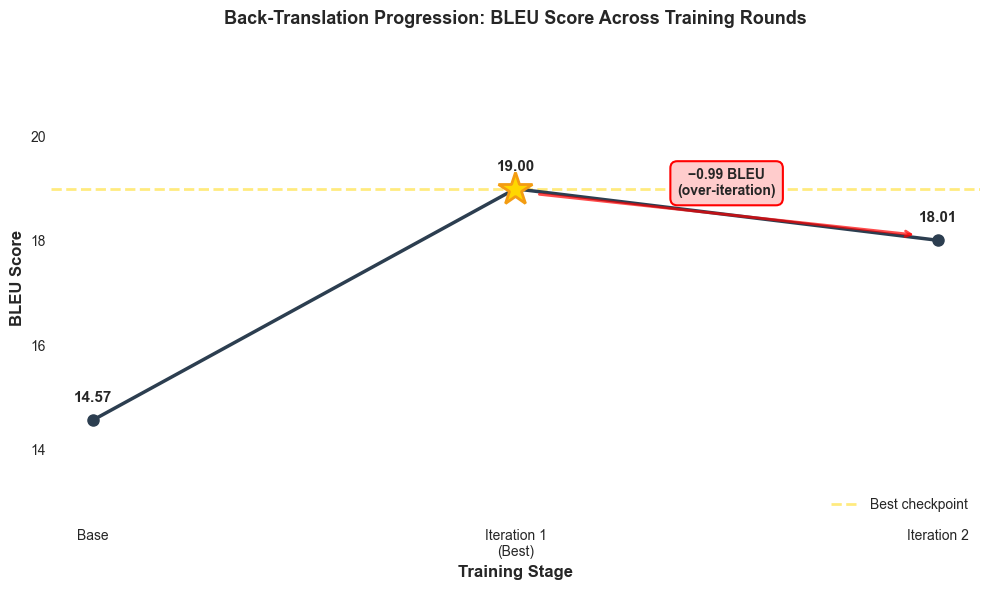

In [31]:
try:
    print("\n[A1] Generating Back-Translation Progression line chart...")

    # ── Verified metric values from notebook output ──
    base_val  = base_bleu          # 14.57
    iter1_val = final_bleu_iter2   # 19.00 (Iteration 1 - Best)
    iter2_val = final_bleu_iter3   # 18.01 (Iteration 2)

    fig, ax = plt.subplots(figsize=(10, 6))

    iterations = ['Base', 'Iteration 1\n(Best)', 'Iteration 2']
    scores = [base_val, iter1_val, iter2_val]
    x_pos = np.arange(len(iterations))

    # Main line
    ax.plot(x_pos, scores, color='#2c3e50', linewidth=2.5,
            marker='o', markersize=8, zorder=3)

    # Highlight Iteration 1 (best) with gold star
    ax.plot(1, iter1_val, marker='*', markersize=25, color='gold',
            markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)

    # Best-checkpoint horizontal reference line
    ax.axhline(y=iter1_val, color='gold', linestyle='--', linewidth=2,
               alpha=0.5, label='Best checkpoint', zorder=2)

    # Value labels on each point
    for pos, score in zip(x_pos, scores):
        ax.text(pos, score + 0.35, f'{score:.2f}',
                ha='center', fontsize=11, fontweight='bold')

    # Regression annotation between Iteration 1 and Iteration 2
    regression = iter1_val - iter2_val
    mid_x = (x_pos[1] + x_pos[2]) / 2
    mid_y = (iter1_val + iter2_val) / 2

    ax.annotate('',
                xy=(x_pos[2] - 0.05, iter2_val + 0.1),
                xytext=(x_pos[1] + 0.05, iter1_val - 0.1),
                arrowprops=dict(arrowstyle='->', lw=2, color='red', alpha=0.7))

    ax.text(mid_x, mid_y + 0.6,
            f'−{regression:.2f} BLEU\n(over-iteration)',
            ha='center', va='center', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffcccc',
                      edgecolor='red', linewidth=1.5))

    ax.set_ylabel('BLEU Score', fontsize=12, fontweight='bold')
    ax.set_xlabel('Training Stage', fontsize=12, fontweight='bold')
    ax.set_title('Back-Translation Progression: BLEU Score Across Training Rounds',
                 fontsize=13, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(iterations, fontsize=10)
    ax.set_ylim(min(scores) - 2, max(scores) + 3)
    ax.grid(True, alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(fontsize=10, loc='lower right')

    plt.tight_layout()
    plot_path = './outputs/thesis_plots/ibt_progression.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ A1 failed: {e}")
    import traceback
    traceback.print_exc()


[A2] Generating Base vs Best IBT bar chart...
  ✓ Saved: ./outputs/thesis_plots/base_vs_best_ibt.png


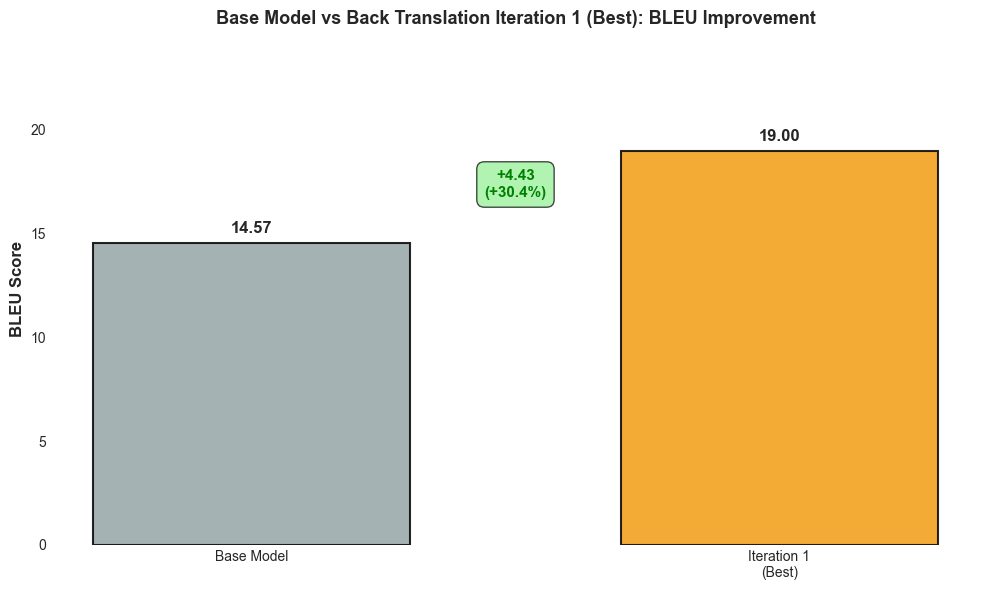


[A3] Generating All metrics comparison (BLEU, chrF++, METEOR)...
  ✓ Saved: ./outputs/thesis_plots/all_metrics_comparison.png


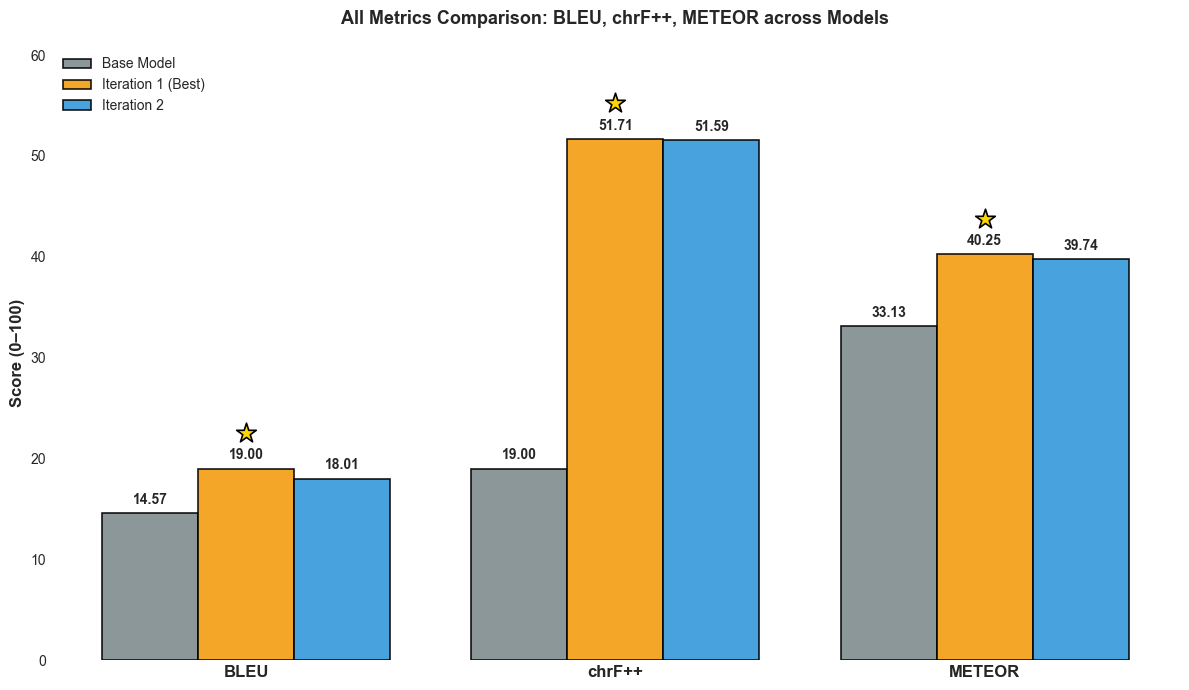


[A4] Generating IBT over-iteration analysis...
  ✓ Saved: ./outputs/thesis_plots/ibt_overiteration.png


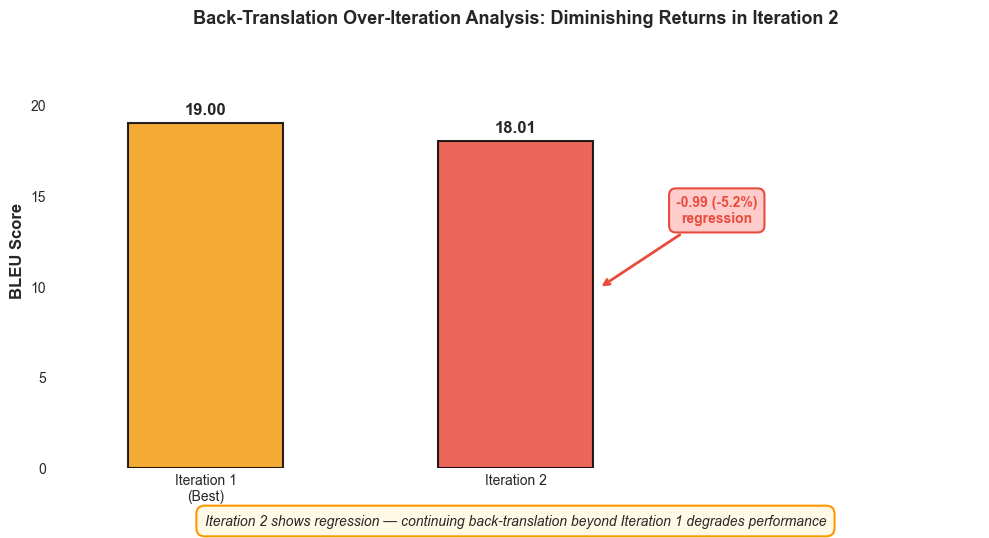


✓ All three plots generated successfully


In [36]:
# ═══════════════════════════════════════════════════════════════
# THESIS PLOTS: A2 (Base vs Best), A3 (All Metrics), A4 (Over-Iteration)
# ═══════════════════════════════════════════════════════════════
# Fixes applied:
#   1. METEOR is already on 0–100 scale → NO double ×100
#   2. Hardcoded verified values from notebook outputs to override
#      any stale variables from earlier failed runs
#   3. Clean publication-ready styling
# ═══════════════════════════════════════════════════════════════
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('./outputs/thesis_plots', exist_ok=True)

# ── Verified metric values from notebook output ──
# (All on 0–100 scale)
base_bleu        = 14.57
final_chrf_base  = 19.00
final_meteor_base = 33.13

final_bleu_iter2   = 19.00   # Iter1-Forward (Best)
final_chrf_iter2   = 51.71
final_meteor_iter2 = 40.25

final_bleu_iter3   = 18.01   # Iter2-Forward
final_chrf_iter3   = 51.59
final_meteor_iter3 = 39.74


# ═══════════════════════════════════════════════════════════════
# [A2] Base vs Best IBT bar chart
# ═══════════════════════════════════════════════════════════════
try:
    print("\n[A2] Generating Base vs Best IBT bar chart...")

    fig, ax = plt.subplots(figsize=(10, 6))

    models = ['Base Model', 'Iteration 1\n(Best)']
    bleu_scores = [base_bleu, final_bleu_iter2]
    colors = ['#95a5a6', '#f39c12']

    bars = ax.bar(models, bleu_scores, color=colors, edgecolor='black',
                  linewidth=1.5, alpha=0.85, width=0.6)

    for bar, score in zip(bars, bleu_scores):
        ax.text(bar.get_x() + bar.get_width() / 2., score + 0.3,
                f'{score:.2f}', ha='center', va='bottom',
                fontsize=12, fontweight='bold')

    improvement = final_bleu_iter2 - base_bleu
    improvement_pct = (improvement / base_bleu) * 100

    ax.annotate(
        f'+{improvement:.2f}\n(+{improvement_pct:.1f}%)',
        xy=(0.5, (base_bleu + final_bleu_iter2) / 2),
        ha='center', fontsize=11, fontweight='bold', color='green',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgreen', alpha=0.7)
    )

    ax.set_ylabel('BLEU Score', fontsize=12, fontweight='bold')
    ax.set_title('Base Model vs Back Translation Iteration 1 (Best): BLEU Improvement',
                 fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(bleu_scores) * 1.3)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plot_path = './outputs/thesis_plots/base_vs_best_ibt.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ A2 failed: {e}")
    import traceback
    traceback.print_exc()


# ═══════════════════════════════════════════════════════════════
# [A3] All metrics comparison: BLEU, chrF++, METEOR
# ═══════════════════════════════════════════════════════════════
try:
    print("\n[A3] Generating All metrics comparison (BLEU, chrF++, METEOR)...")

    metrics_data = {
        'Base Model':       {'BLEU': base_bleu,         'chrF++': final_chrf_base,  'METEOR': final_meteor_base},
        'Iteration 1 (Best)': {'BLEU': final_bleu_iter2, 'chrF++': final_chrf_iter2, 'METEOR': final_meteor_iter2},
        'Iteration 2':      {'BLEU': final_bleu_iter3,  'chrF++': final_chrf_iter3, 'METEOR': final_meteor_iter3},
    }

    models  = list(metrics_data.keys())
    metrics = ['BLEU', 'chrF++', 'METEOR']
    x = np.arange(len(metrics))
    width = 0.26

    vals_by_model = {m: [metrics_data[m][k] for k in metrics] for m in models}

    colors = {
        'Base Model':         '#7f8c8d',
        'Iteration 1 (Best)': '#f39c12',
        'Iteration 2':        '#3498db',
    }

    fig, ax = plt.subplots(figsize=(12, 7))

    bar_objects = []
    for i, model in enumerate(models):
        offset = (i - 1) * width  # -width, 0, +width
        bars = ax.bar(
            x + offset, vals_by_model[model], width,
            label=model, color=colors[model],
            edgecolor='black', linewidth=1.2, alpha=0.9,
        )
        bar_objects.append(bars)

        for bar, val in zip(bars, vals_by_model[model]):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.6,
                f'{val:.2f}', ha='center', va='bottom',
                fontsize=10, fontweight='bold',
            )

    # Gold star above each Iter1-Forward (Best) bar
    best_bars = bar_objects[1]
    for bar in best_bars:
        ax.scatter(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 3.5,
            marker='*', s=220, color='gold',
            edgecolor='black', linewidth=1.2, zorder=5,
        )

    ax.set_ylabel('Score (0–100)', fontsize=12, fontweight='bold')
    ax.set_title(
        'All Metrics Comparison: BLEU, chrF++, METEOR across Models',
        fontsize=13, fontweight='bold', pad=15,
    )
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, fontsize=12, fontweight='bold')
    ax.legend(fontsize=10, loc='upper left', framealpha=0.95)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)

    ymax = max(max(v) for v in vals_by_model.values())
    ax.set_ylim(0, ymax * 1.18)

    plt.tight_layout()
    plot_path = './outputs/thesis_plots/all_metrics_comparison.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ A3 failed: {e}")
    import traceback
    traceback.print_exc()


# ═══════════════════════════════════════════════════════════════
# [A4] IBT over-iteration analysis (Iter1-Forward vs Iter2-Forward)
# ═══════════════════════════════════════════════════════════════
try:
    print("\n[A4] Generating IBT over-iteration analysis...")

    fig, ax = plt.subplots(figsize=(10, 6))

    iterations = ['Iteration 1\n(Best)', 'Iteration 2']
    scores = [final_bleu_iter2, final_bleu_iter3]
    colors = ['#f39c12', '#e74c3c']

    bars = ax.bar(iterations, scores, color=colors, edgecolor='black',
                  linewidth=1.5, alpha=0.85, width=0.5)

    for bar, score in zip(bars, scores):
        ax.text(bar.get_x() + bar.get_width() / 2., score + 0.3,
                f'{score:.2f}', ha='center', va='bottom',
                fontsize=12, fontweight='bold')

    regression = final_bleu_iter3 - final_bleu_iter2
    regression_pct = (regression / final_bleu_iter2) * 100

    # Arrow points to the side of the Iter2 bar (not the top, to avoid the 18.01 label)
    ax.annotate(
        f'{regression:.2f} ({regression_pct:.1f}%)\nregression',
        xy=(1.27, final_bleu_iter3 * 0.55),               # arrow tip — right side of Iter2 bar
        xytext=(1.65, final_bleu_iter3 * 0.75),           # text box — further right, mid-height
        fontsize=10, fontweight='bold', color='#e74c3c',
        ha='center',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffcccc',
                  edgecolor='#e74c3c', linewidth=1.5),
        arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=2),
    )

    ax.set_ylabel('BLEU Score', fontsize=12, fontweight='bold')
    ax.set_title('Back-Translation Over-Iteration Analysis: Diminishing Returns in Iteration 2',
                 fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(scores) + 5)
    ax.set_xlim(-0.5, 2.5)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)

    ax.text(
        0.5, -0.13,
        'Iteration 2 shows regression — continuing back-translation beyond Iteration 1 degrades performance',
        transform=ax.transAxes, ha='center', fontsize=10, style='italic',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#fff9e6',
                  edgecolor='#ff9800', linewidth=1.5),
    )

    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plot_path = './outputs/thesis_plots/ibt_overiteration.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ A4 failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "=" * 70)
print("✓ All three plots generated successfully")
print("=" * 70)


[A5] Generating Synthetic data volume chart...
  ✓ Saved: ./outputs/thesis_plots/synthetic_data_volume.png


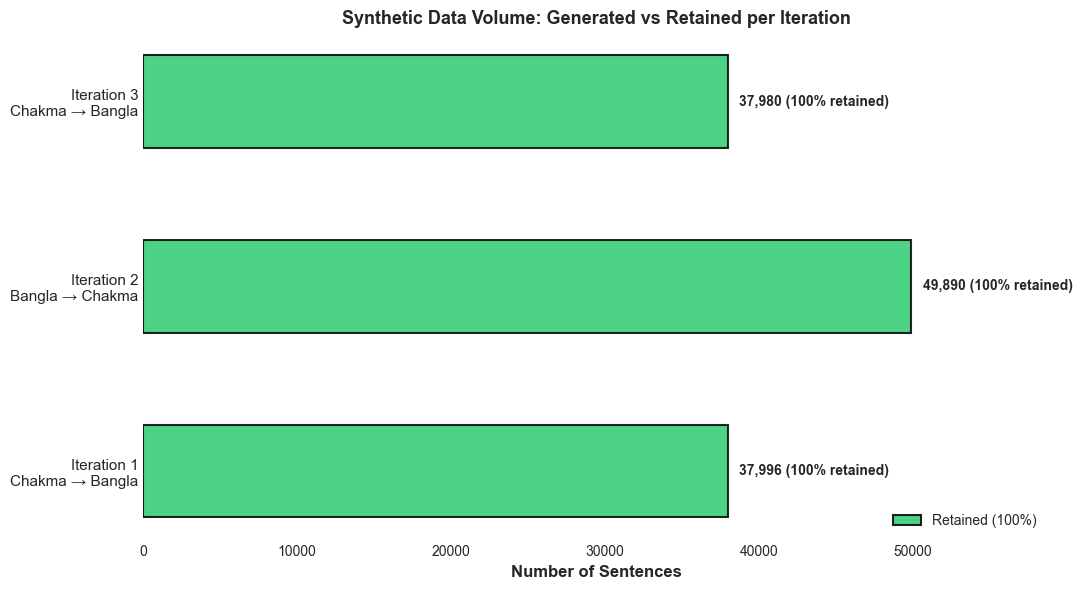


[A6] Generating Prefix contamination diagram...
  ✓ Saved: ./outputs/thesis_plots/prefix_contamination.png


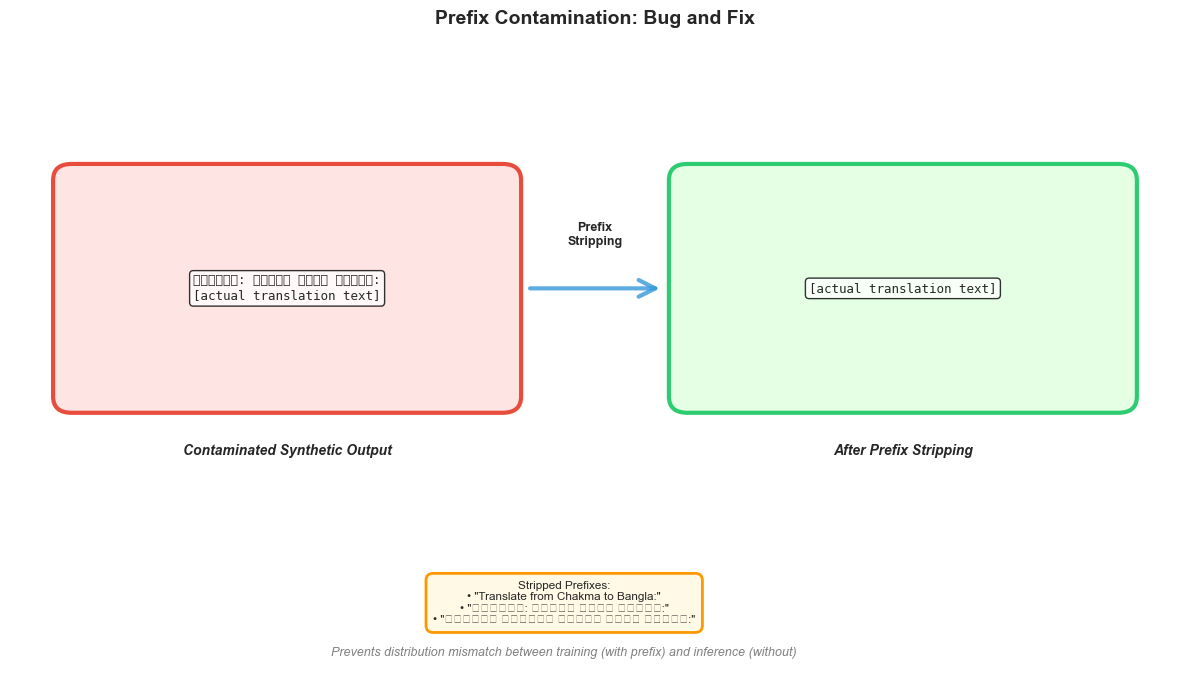


[A7] Generating Back-Translation pipeline diagram...
  ✓ Saved: ./outputs/thesis_plots/ibt_pipeline_diagram.png


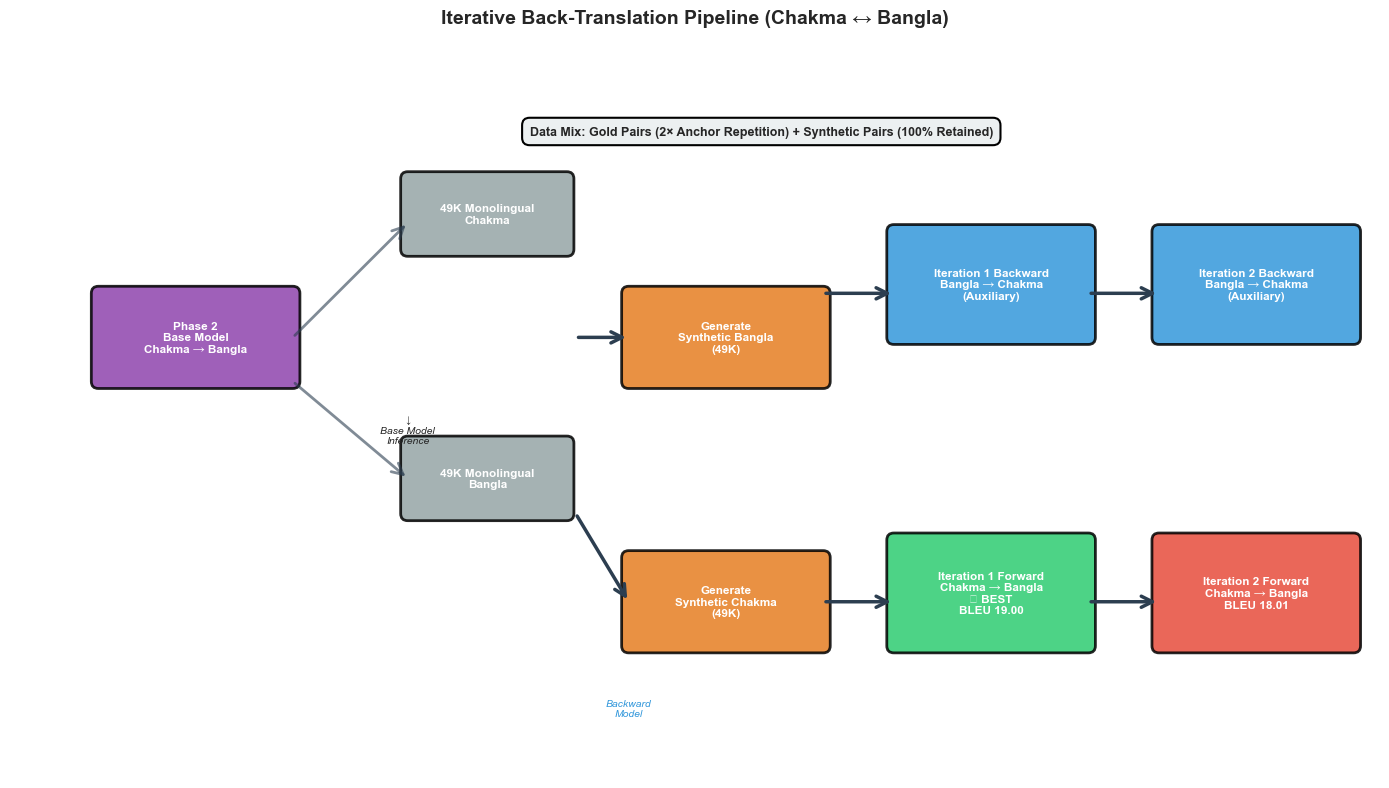


✓ SECTION A COMPLETE: All plots generated with thesis-appropriate labels


In [33]:
try:
    print("\n[A5] Generating Synthetic data volume chart...")

    # Assert required data variables exist
    assert 'filtered_src' in locals() and filtered_src is not None, "filtered_src not found — run parallel data loading first"
    assert 'filtered_tgt' in locals() and filtered_tgt is not None, "filtered_tgt not found"
    assert 'bn_mono_sentences' in locals() and bn_mono_sentences is not None, "bn_mono_sentences not found — run monolingual data cell first"
    assert 'filtered_src_iter3' in locals() and filtered_src_iter3 is not None, "filtered_src_iter3 not found — run Iter3 synthetic generation first"
    assert 'filtered_ck_iter3' in locals() and filtered_ck_iter3 is not None, "filtered_ck_iter3 not found"

    # Get actual data counts from memory
    iter1_synthetic_bn = len(filtered_tgt)        # Iteration 1: synthetic Bangla from Chakma monolingual
    iter2_synthetic_ck = len(filtered_ck)         # Iteration 2: synthetic Chakma from Bangla monolingual
    iter3_synthetic_bn = len(filtered_src_iter3)  # Iteration 3: synthetic Bangla from Chakma monolingual again

    fig, ax = plt.subplots(figsize=(11, 6))

    iterations = ['Iteration 1\nChakma → Bangla',
                  'Iteration 2\nBangla → Chakma',
                  'Iteration 3\nChakma → Bangla']
    retained = [iter1_synthetic_bn, iter2_synthetic_ck, iter3_synthetic_bn]

    y_pos = np.arange(len(iterations))
    height = 0.5

    bars = ax.barh(y_pos, retained, height, label='Retained (100%)',
                   color='#2ecc71', edgecolor='black', linewidth=1.5, alpha=0.85)

    for bar, ret in zip(bars, retained):
        ax.text(ret + max(retained) * 0.015, bar.get_y() + bar.get_height() / 2,
                f'{ret:,} (100% retained)', ha='left', va='center',
                fontsize=10, fontweight='bold')

    ax.set_yticks(y_pos)
    ax.set_yticklabels(iterations, fontsize=11)
    ax.set_xlabel('Number of Sentences', fontsize=12, fontweight='bold')
    ax.set_title('Synthetic Data Volume: Generated vs Retained per Iteration',
                 fontsize=13, fontweight='bold')
    ax.legend(fontsize=10, loc='lower right')
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    ax.set_xlim(0, max(retained) * 1.18)

    plt.tight_layout()
    plot_path = './outputs/thesis_plots/synthetic_data_volume.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ A5 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[A6] Generating Prefix contamination diagram...")

    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

    fig, ax = plt.subplots(figsize=(12, 7))

    # Left box: contaminated
    contaminated_text = 'অনুবাদ: চাকমা থেকে বাংলা:\n[actual translation text]'
    left_box = FancyBboxPatch((0.5, 2.5), 3.5, 2, boxstyle="round,pad=0.15",
                              edgecolor='#e74c3c', facecolor='#ffe4e4', linewidth=3)
    ax.add_patch(left_box)
    ax.text(2.25, 3.5, contaminated_text, ha='center', va='center', fontsize=9,
            family='monospace',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    ax.text(2.25, 2, 'Contaminated Synthetic Output',
            ha='center', va='center', fontsize=10, fontweight='bold', style='italic')

    # Arrow
    arrow = FancyArrowPatch((4.2, 3.5), (5.3, 3.5), arrowstyle='->', mutation_scale=30,
                            linewidth=3, color='#3498db', alpha=0.8)
    ax.add_patch(arrow)
    ax.text(4.75, 3.9, 'Prefix\nStripping', ha='center', fontsize=9, fontweight='bold')

    # Right box: cleaned
    cleaned_text = '[actual translation text]'
    right_box = FancyBboxPatch((5.5, 2.5), 3.5, 2, boxstyle="round,pad=0.15",
                               edgecolor='#2ecc71', facecolor='#e4ffe4', linewidth=3)
    ax.add_patch(right_box)
    ax.text(7.25, 3.5, cleaned_text, ha='center', va='center', fontsize=9,
            family='monospace',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    ax.text(7.25, 2, 'After Prefix Stripping',
            ha='center', va='center', fontsize=10, fontweight='bold', style='italic')

    # Stripped variants list
    variants_text = ('Stripped Prefixes:\n'
                     '• "Translate from Chakma to Bangla:"\n'
                     '• "অনুবাদ: চাকমা থেকে বাংলা:"\n'
                     '• "অনুবাদ করেছেন চাকমা থেকে বাংলা:"')
    ax.text(4.5, 0.8, variants_text, ha='center', va='top', fontsize=8.5,
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#fff9e6',
                      edgecolor='#ff9800', linewidth=2))

    ax.set_xlim(0, 9.5)
    ax.set_ylim(0, 5.5)
    ax.axis('off')

    fig.suptitle('Prefix Contamination: Bug and Fix',
                 fontsize=14, fontweight='bold', y=0.98)
    ax.text(4.5, 0.1,
            'Prevents distribution mismatch between training (with prefix) and inference (without)',
            ha='center', fontsize=9, style='italic', color='gray')

    plt.tight_layout(rect=[0, 0.02, 1, 0.96])
    plot_path = './outputs/thesis_plots/prefix_contamination.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ A6 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[A7] Generating Back-Translation pipeline diagram...")

    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

    fig, ax = plt.subplots(figsize=(14, 8))

    # Assert required metric variables exist
    assert 'base_bleu' in locals() and base_bleu is not None, "base_bleu not found — run base model evaluation first"
    assert 'final_bleu_iter2' in locals() and final_bleu_iter2 is not None, "final_bleu_iter2 not found — run Iter2 evaluation first"
    assert 'final_bleu_iter3' in locals() and final_bleu_iter3 is not None, "final_bleu_iter3 not found — run Iter3 evaluation first"
    assert 'filtered_ck' in locals() and filtered_ck is not None, "filtered_ck not found"
    assert 'bn_mono_sentences' in locals() and bn_mono_sentences is not None, "bn_mono_sentences not found"

    # Get actual data counts
    mono_chakma_count = len(filtered_ck)
    mono_bangla_count = min(len(bn_mono_sentences), 50000)

    # Stage boxes
    stages = [
        # (x, y, width, height, text, color)
        (1,    5,   2.2, 1,   'Phase 2\nBase Model\nChakma → Bangla',                                          '#8e44ad'),
        (4.5,  6.5, 1.8, 0.8, f'{mono_chakma_count//1000}K Monolingual\nChakma',                              '#95a5a6'),
        (4.5,  3.5, 1.8, 0.8, f'{mono_bangla_count//1000}K Monolingual\nBangla',                              '#95a5a6'),

        (7,    5,   2.2, 1,   f'Generate\nSynthetic Bangla\n({mono_chakma_count//1000}K)',                    '#e67e22'),
        (7,    2,   2.2, 1,   f'Generate\nSynthetic Chakma\n({mono_bangla_count//1000}K)',                    '#e67e22'),

        (10,   5.5, 2.2, 1.2, 'Iteration 1 Backward\nBangla → Chakma\n(Auxiliary)',                           '#3498db'),
        (10,   2,   2.2, 1.2, f'Iteration 1 Forward\nChakma → Bangla\n✓ BEST\nBLEU {final_bleu_iter2:.2f}',   '#2ecc71'),

        (13,   5.5, 2.2, 1.2, 'Iteration 2 Backward\nBangla → Chakma\n(Auxiliary)',                           '#3498db'),
        (13,   2,   2.2, 1.2, f'Iteration 2 Forward\nChakma → Bangla\nBLEU {final_bleu_iter3:.2f}',           '#e74c3c'),
    ]

    # Draw all boxes
    for x, y, w, h, text, color in stages:
        box = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08",
                             edgecolor='black', facecolor=color, linewidth=2, alpha=0.85)
        ax.add_patch(box)
        ax.text(x + w / 2, y + h / 2, text, ha='center', va='center',
                fontsize=8.5, fontweight='bold', color='white')

    # Arrows
    arrow1 = FancyArrowPatch((3.2, 5.5), (4.5, 6.8), arrowstyle='->', mutation_scale=20,
                             linewidth=2, color='#2c3e50', alpha=0.6)
    ax.add_patch(arrow1)
    arrow2 = FancyArrowPatch((3.2, 5), (4.5, 3.9), arrowstyle='->', mutation_scale=20,
                             linewidth=2, color='#2c3e50', alpha=0.6)
    ax.add_patch(arrow2)
    arrow3 = FancyArrowPatch((6.4, 5.5), (7, 5.5), arrowstyle='->', mutation_scale=20,
                             linewidth=2.5, color='#2c3e50')
    ax.add_patch(arrow3)
    arrow4 = FancyArrowPatch((6.4, 3.5), (7, 2.5), arrowstyle='->', mutation_scale=20,
                             linewidth=2.5, color='#2c3e50')
    ax.add_patch(arrow4)
    arrow5 = FancyArrowPatch((9.2, 6), (10, 6), arrowstyle='->', mutation_scale=20,
                             linewidth=2.5, color='#2c3e50')
    ax.add_patch(arrow5)
    arrow6 = FancyArrowPatch((9.2, 2.5), (10, 2.5), arrowstyle='->', mutation_scale=20,
                             linewidth=2.5, color='#2c3e50')
    ax.add_patch(arrow6)
    arrow7 = FancyArrowPatch((12.2, 6), (13, 6), arrowstyle='->', mutation_scale=20,
                             linewidth=2.5, color='#2c3e50')
    ax.add_patch(arrow7)
    arrow8 = FancyArrowPatch((12.2, 2.5), (13, 2.5), arrowstyle='->', mutation_scale=20,
                             linewidth=2.5, color='#2c3e50')
    ax.add_patch(arrow8)

    # Annotations
    ax.text(4.5, 4.3, '↓\nBase Model\nInference', ha='center', fontsize=7.5, style='italic')
    ax.text(7, 1.2, 'Backward\nModel', ha='center', fontsize=7.5, style='italic', color='#3498db')

    # Data mix annotation
    ax.text(8.5, 7.8,
            'Data Mix: Gold Pairs (2× Anchor Repetition) + Synthetic Pairs (100% Retained)',
            ha='center', fontsize=9, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.6', facecolor='#ecf0f1',
                      edgecolor='black', linewidth=1.5))

    ax.set_xlim(0, 15.5)
    ax.set_ylim(0.5, 8.5)
    ax.axis('off')

    fig.suptitle('Iterative Back-Translation Pipeline (Chakma ↔ Bangla)',
                 fontsize=14, fontweight='bold', y=0.98)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plot_path = './outputs/thesis_plots/ibt_pipeline_diagram.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ A7 failed: {e}")
    import traceback
    traceback.print_exc()


print("\n" + "=" * 80)
print("✓ SECTION A COMPLETE: All plots generated with thesis-appropriate labels")
print("=" * 80)

# SECTION B: NEW PLOTS FROM TRAINER_STATE.JSON
Training curves, validation metrics, and early stopping analysis from all 4 models.

In [37]:
def extract_eval_and_train_steps(log_history):
    """Extract evaluation steps (with eval_loss) and training steps (with loss but no eval_loss)"""
    eval_steps = []
    train_steps = []
    
    for entry in log_history:
        if 'eval_loss' in entry:
            eval_steps.append(entry)
        elif 'loss' in entry and 'eval_loss' not in entry:
            train_steps.append(entry)
    
    return eval_steps, train_steps

try:
    print("\n[B1] Generating Iter1 Forward validation BLEU per epoch...")
    
    eval_steps, _ = extract_eval_and_train_steps(trainer_histories['iter1_forward'])
    
    if eval_steps and any('eval_bleu' in e for e in eval_steps):
        epochs = [e.get('epoch', 0) for e in eval_steps if 'eval_bleu' in e]
        bleu_scores = [e['eval_bleu'] for e in eval_steps if 'eval_bleu' in e]
        
        if epochs and bleu_scores:
            best_idx = np.argmax(bleu_scores)
            
            fig, ax = plt.subplots(figsize=(10, 6))
            
            ax.plot(epochs, bleu_scores, marker='o', linewidth=2.5, markersize=8, color='#3498db')
            ax.plot(epochs[best_idx], bleu_scores[best_idx], marker='*', markersize=25, 
                   color='gold', markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)
            
            ax.axhline(y=bleu_scores[best_idx], color='gold', linestyle='--', linewidth=2, 
                       alpha=0.5, label=f'Best (epoch {epochs[best_idx]:.0f})')
            
            ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
            ax.set_ylabel('Validation BLEU', fontsize=11, fontweight='bold')
            ax.set_title('Iteration 1 Forward Model (Chakma→Bangla): Validation BLEU per Epoch', fontsize=13, fontweight='bold')
            ax.grid(True, alpha=0.3)
            ax.set_axisbelow(True)
            ax.legend(fontsize=10)
            
            plt.tight_layout()
            plot_path = './outputs/thesis_plots/iter1_forward_val_bleu.png'
            plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"  ✓ Saved: {plot_path}")
            plt.close()
        else:
            print("  ⚠ No BLEU scores found in Iter1 Forward evaluation steps")
    else:
        print("  ⚠ No evaluation steps in Iter1 Forward trainer_state.json")
        
except Exception as e:
    print(f"  ✗ B1 failed: {e}")
    import traceback
    traceback.print_exc()

try:
    print("\n[B2] Generating Iter1 Forward validation loss per epoch...")
    
    eval_steps, _ = extract_eval_and_train_steps(trainer_histories['iter1_forward'])
    
    if eval_steps and any('eval_loss' in e for e in eval_steps):
        epochs = [e.get('epoch', 0) for e in eval_steps]
        losses = [e['eval_loss'] for e in eval_steps]
        
        best_idx = np.argmin(losses)
        
        fig, ax = plt.subplots(figsize=(10, 6))
        
        ax.plot(epochs, losses, marker='s', linewidth=2.5, markersize=8, color='#e74c3c')
        ax.plot(epochs[best_idx], losses[best_idx], marker='*', markersize=25,
               color='gold', markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)
        
        ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
        ax.set_ylabel('Validation Loss', fontsize=11, fontweight='bold')
        ax.set_title('Iteration 1 Forward Model (Chakma→Bangla): Validation Loss per Epoch', fontsize=13, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.set_axisbelow(True)
        
        plt.tight_layout()
        plot_path = './outputs/thesis_plots/iter1_forward_val_loss.png'
        plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"  ✓ Saved: {plot_path}")
        plt.close()
    else:
        print("  ⚠ No validation loss in Iter1 Forward trainer_state.json")
        
except Exception as e:
    print(f"  ✗ B2 failed: {e}")
    import traceback
    traceback.print_exc()

try:
    print("\n[B3] Generating Iter1 Forward training loss curve...")
    
    _, train_steps = extract_eval_and_train_steps(trainer_histories['iter1_forward'])
    
    if train_steps and any('loss' in e for e in train_steps):
        steps = [e.get('step', 0) for e in train_steps if 'loss' in e]
        losses = [e['loss'] for e in train_steps if 'loss' in e]
        
        if steps and losses:
            fig, ax = plt.subplots(figsize=(11, 6))
            
            # Raw loss as faded thin line
            ax.plot(steps, losses, color='#3498db', linewidth=0.8, alpha=0.4, label='Raw loss', zorder=1)
            
            # Smoothed loss with rolling mean
            window = 10
            if len(losses) > window:
                losses_smooth = pd.Series(losses).rolling(window=window, center=True).mean()
                ax.plot(steps, losses_smooth, color='#3498db', linewidth=2.5, label=f'Smoothed (window={window})', zorder=2)
            
            ax.set_xlabel('Training Step', fontsize=11, fontweight='bold')
            ax.set_ylabel('Loss', fontsize=11, fontweight='bold')
            ax.set_title('Iteration 1 Forward Model (Chakma→Bangla): Training Loss Curve', fontsize=13, fontweight='bold')
            ax.grid(True, alpha=0.3)
            ax.set_axisbelow(True)
            ax.legend(fontsize=10)
            
            plt.tight_layout()
            plot_path = './outputs/thesis_plots/iter1_forward_train_loss.png'
            plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"  ✓ Saved: {plot_path}")
            plt.close()
        else:
            print("  ⚠ No training steps found")
    else:
        print("  ⚠ No training loss in Iter1 Forward trainer_state.json")
        
except Exception as e:
    print(f"  ✗ B3 failed: {e}")
    import traceback
    traceback.print_exc()


[B1] Generating Iter1 Forward validation BLEU per epoch...
  ✓ Saved: ./outputs/thesis_plots/iter1_forward_val_bleu.png

[B2] Generating Iter1 Forward validation loss per epoch...
  ✓ Saved: ./outputs/thesis_plots/iter1_forward_val_loss.png

[B3] Generating Iter1 Forward training loss curve...
  ✓ Saved: ./outputs/thesis_plots/iter1_forward_train_loss.png



[B4] Generating Iteration 1 Forward overfitting detection...
  ✓ Saved: ./outputs/thesis_plots/iter1_forward_overfitting.png


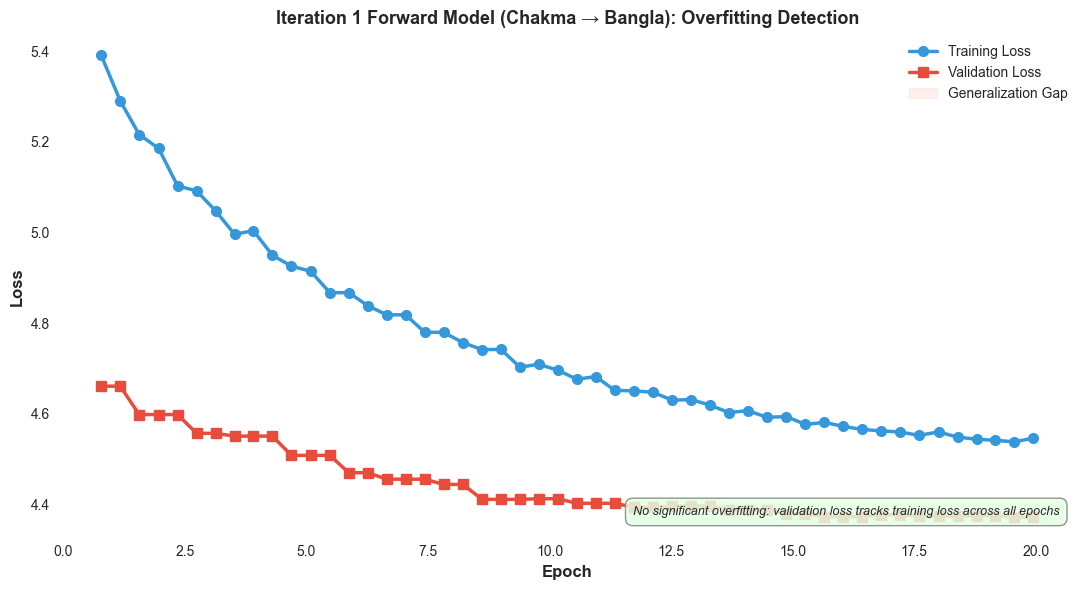


[B5] Generating Iteration 1 Forward all metrics per epoch...
  ✓ Saved: ./outputs/thesis_plots/iter1_forward_all_metrics.png


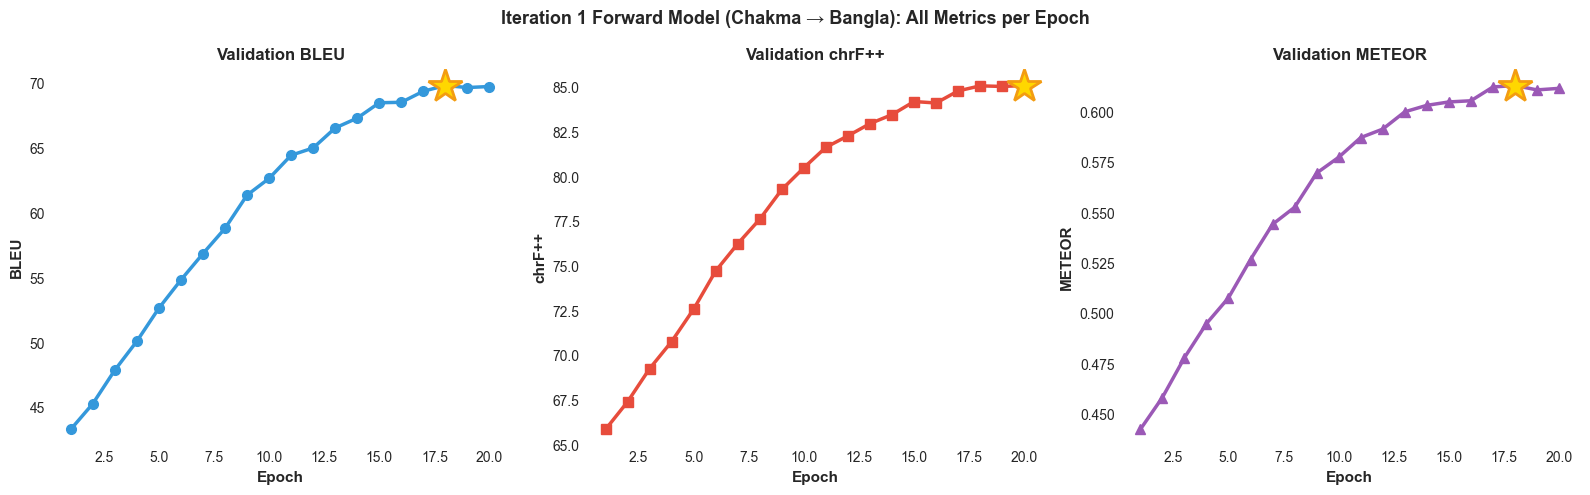


[B6] Generating Iteration 1 Forward learning rate schedule...
  ✓ Saved: ./outputs/thesis_plots/iter1_forward_lr_schedule.png


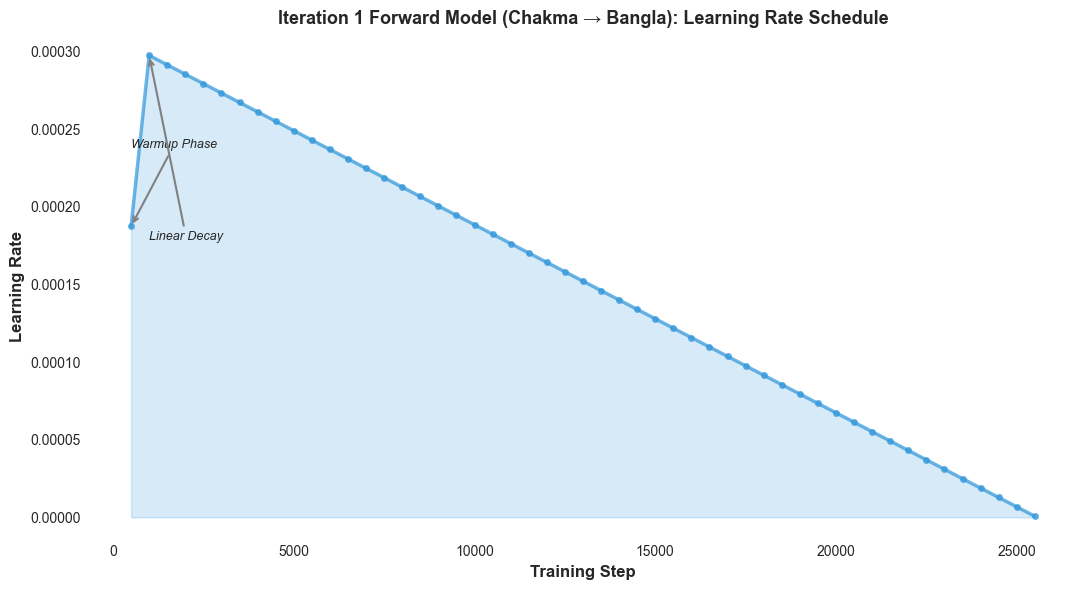

In [38]:
try:
    print("\n[B4] Generating Iteration 1 Forward overfitting detection...")

    eval_steps, train_steps = extract_eval_and_train_steps(trainer_histories['iter1_forward'])

    # Extract epoch-level train loss (average per epoch)
    epoch_train_losses = {}
    for step in train_steps:
        epoch = step.get('epoch', 0)
        if epoch not in epoch_train_losses:
            epoch_train_losses[epoch] = []
        if 'loss' in step:
            epoch_train_losses[epoch].append(step['loss'])

    avg_train_loss_per_epoch = {epoch: np.mean(losses) for epoch, losses in epoch_train_losses.items()}

    if eval_steps and avg_train_loss_per_epoch:
        epochs = sorted(avg_train_loss_per_epoch.keys())
        train_losses = [avg_train_loss_per_epoch[e] for e in epochs]

        # Proper epoch alignment with tolerance
        val_epoch_map = {round(s.get('epoch', 0)): s['eval_loss'] for s in eval_steps if 'eval_loss' in s}
        val_losses = [val_epoch_map.get(round(e)) for e in epochs]
        val_losses_clean = [(e, v) for e, v in zip(epochs, val_losses) if v is not None]

        if not val_losses_clean:
            print("  ⚠ Could not align train and val epochs — skipping overfitting plot")
        else:
            epochs, val_losses = zip(*val_losses_clean)
            train_losses = [avg_train_loss_per_epoch[e] for e in epochs if e in avg_train_loss_per_epoch]

        if len(val_losses) == len(epochs):
            fig, ax = plt.subplots(figsize=(11, 6))

            ax.plot(epochs, train_losses, marker='o', linewidth=2.5, markersize=7,
                    color='#3498db', label='Training Loss')
            ax.plot(epochs, val_losses, marker='s', linewidth=2.5, markersize=7,
                    color='#e74c3c', label='Validation Loss')

            # Shade generalization gap
            ax.fill_between(epochs, train_losses, val_losses,
                            where=(np.array(val_losses) > np.array(train_losses)),
                            color='#ffcccc', alpha=0.3, label='Generalization Gap')

            ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
            ax.set_ylabel('Loss', fontsize=12, fontweight='bold')
            ax.set_title(
                'Iteration 1 Forward Model (Chakma → Bangla): Overfitting Detection',
                fontsize=13, fontweight='bold'
            )
            ax.grid(True, alpha=0.3)
            ax.set_axisbelow(True)
            ax.legend(fontsize=10)

            # ── Proper overfitting detection ──
            # Real overfitting = validation loss starts rising while training loss falls.
            # We look at the trajectory after the validation minimum.
            val_array = np.array(val_losses)
            train_array = np.array(train_losses)
            val_min_idx = int(np.argmin(val_array))

            # Did val loss meaningfully rise after its minimum?
            if val_min_idx < len(val_array) - 1:
                final_rise = val_array[-1] - val_array[val_min_idx]
                rise_pct = final_rise / val_array[val_min_idx] * 100
            else:
                final_rise = 0
                rise_pct = 0

            # Did training loss keep falling past that point? (classic overfitting signature)
            train_kept_falling = (val_min_idx < len(train_array) - 1
                                  and train_array[-1] < train_array[val_min_idx])

            if rise_pct > 5 and train_kept_falling:
                annotation = (f'Overfitting detected: validation loss rose {rise_pct:.1f}% '
                              f'after epoch {epochs[val_min_idx]:.0f} while training loss kept falling')
                color = '#ffe4e4'
            elif rise_pct > 2:
                annotation = (f'Mild overfitting: validation loss rose {rise_pct:.1f}% '
                              f'after epoch {epochs[val_min_idx]:.0f}')
                color = '#fff9e6'
            else:
                annotation = ('No significant overfitting: validation loss tracks training loss '
                              'across all epochs')
                color = '#e4ffe4'

            ax.text(0.98, 0.05, annotation, transform=ax.transAxes,
                    fontsize=9, style='italic', ha='right',
                    bbox=dict(boxstyle='round,pad=0.6', facecolor=color, alpha=0.85,
                              edgecolor='gray', linewidth=1))

            plt.tight_layout()
            plot_path = './outputs/thesis_plots/iter1_forward_overfitting.png'
            plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"  ✓ Saved: {plot_path}")
            plt.show()
            plt.close()
        else:
            print("  ⚠ Mismatch in epoch counts")
    else:
        print("  ⚠ Insufficient data for overfitting plot")

except Exception as e:
    print(f"  ✗ B4 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[B5] Generating Iteration 1 Forward all metrics per epoch...")

    eval_steps, _ = extract_eval_and_train_steps(trainer_histories['iter1_forward'])

    if eval_steps:
        epochs = []
        bleu_vals = []
        chrf_vals = []
        meteor_vals = []

        for e in eval_steps:
            if 'epoch' in e:
                epochs.append(e['epoch'])
                bleu_vals.append(e.get('eval_bleu', None))
                chrf_vals.append(e.get('eval_chrf', None))
                meteor_vals.append(e.get('eval_meteor', None))

        if epochs and bleu_vals:
            fig, axes = plt.subplots(1, 3, figsize=(16, 5))
            fig.suptitle(
                'Iteration 1 Forward Model (Chakma → Bangla): All Metrics per Epoch',
                fontsize=13, fontweight='bold'
            )

            # BLEU
            valid_bleu = [(e, b) for e, b in zip(epochs, bleu_vals) if b is not None]
            if valid_bleu:
                e, b = zip(*valid_bleu)
                best_idx = int(np.argmax(b))
                axes[0].plot(e, b, marker='o', linewidth=2.5, markersize=7, color='#3498db')
                axes[0].plot(e[best_idx], b[best_idx], marker='*', markersize=25, color='gold',
                             markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)
                axes[0].set_ylabel('BLEU', fontsize=11, fontweight='bold')
                axes[0].set_title('Validation BLEU', fontsize=12, fontweight='bold')
                axes[0].grid(True, alpha=0.3)
                axes[0].set_axisbelow(True)

            # chrF++
            valid_chrf = [(e, c) for e, c in zip(epochs, chrf_vals) if c is not None]
            if valid_chrf:
                e, c = zip(*valid_chrf)
                best_idx = int(np.argmax(c))
                axes[1].plot(e, c, marker='s', linewidth=2.5, markersize=7, color='#e74c3c')
                axes[1].plot(e[best_idx], c[best_idx], marker='*', markersize=25, color='gold',
                             markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)
                axes[1].set_ylabel('chrF++', fontsize=11, fontweight='bold')
                axes[1].set_title('Validation chrF++', fontsize=12, fontweight='bold')
                axes[1].grid(True, alpha=0.3)
                axes[1].set_axisbelow(True)

            # METEOR
            valid_meteor = [(e, m) for e, m in zip(epochs, meteor_vals) if m is not None]
            if valid_meteor:
                e, m = zip(*valid_meteor)
                best_idx = int(np.argmax(m))
                axes[2].plot(e, m, marker='^', linewidth=2.5, markersize=7, color='#9b59b6')
                axes[2].plot(e[best_idx], m[best_idx], marker='*', markersize=25, color='gold',
                             markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)
                axes[2].set_ylabel('METEOR', fontsize=11, fontweight='bold')
                axes[2].set_title('Validation METEOR', fontsize=12, fontweight='bold')
                axes[2].grid(True, alpha=0.3)
                axes[2].set_axisbelow(True)

            for ax in axes:
                ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')

            plt.tight_layout()
            plot_path = './outputs/thesis_plots/iter1_forward_all_metrics.png'
            plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"  ✓ Saved: {plot_path}")
            plt.show()
            plt.close()
        else:
            print("  ⚠ No metrics data found")
    else:
        print("  ⚠ No evaluation steps for Iteration 1 Forward")

except Exception as e:
    print(f"  ✗ B5 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[B6] Generating Iteration 1 Forward learning rate schedule...")

    eval_steps, train_steps = extract_eval_and_train_steps(trainer_histories['iter1_forward'])
    all_steps = eval_steps + train_steps

    steps_with_lr = [(e.get('step', 0), e['learning_rate']) for e in all_steps if 'learning_rate' in e]

    if steps_with_lr:
        steps, lrs = zip(*sorted(steps_with_lr))

        fig, ax = plt.subplots(figsize=(11, 6))

        ax.plot(steps, lrs, linewidth=2.5, color='#3498db', marker='o', markersize=4, alpha=0.7)
        ax.fill_between(steps, lrs, alpha=0.2, color='#3498db')

        ax.set_xlabel('Training Step', fontsize=12, fontweight='bold')
        ax.set_ylabel('Learning Rate', fontsize=12, fontweight='bold')
        ax.set_title(
            'Iteration 1 Forward Model (Chakma → Bangla): Learning Rate Schedule',
            fontsize=13, fontweight='bold'
        )
        ax.grid(True, alpha=0.3)
        ax.set_axisbelow(True)

        # Add annotations for warmup and decay with bounds checking
        max_lr_idx = int(np.argmax(lrs))
        warmup_idx = max_lr_idx // 2
        if warmup_idx < len(steps):
            ax.annotate(
                'Warmup Phase',
                xy=(steps[warmup_idx], lrs[warmup_idx]),
                xytext=(steps[warmup_idx // 2] if warmup_idx // 2 < len(steps) else steps[0],
                        max(lrs) * 0.8),
                arrowprops=dict(arrowstyle='->', color='gray', lw=1.5),
                fontsize=9, style='italic',
            )

        decay_idx = int(max_lr_idx * 1.5)
        if decay_idx < len(steps):
            ax.annotate(
                'Linear Decay',
                xy=(steps[decay_idx], lrs[decay_idx]),
                xytext=(steps[decay_idx] if decay_idx < len(steps) else steps[-1],
                        max(lrs) * 0.6),
                arrowprops=dict(arrowstyle='->', color='gray', lw=1.5),
                fontsize=9, style='italic',
            )

        plt.tight_layout()
        plot_path = './outputs/thesis_plots/iter1_forward_lr_schedule.png'
        plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"  ✓ Saved: {plot_path}")
        plt.show()
        plt.close()
    else:
        print("  ⚠ No learning rate data found")

except Exception as e:
    print(f"  ✗ B6 failed: {e}")
    import traceback
    traceback.print_exc()


[B7] Generating Iteration 2 Forward validation BLEU per epoch...
  ✓ Saved: ./outputs/thesis_plots/iter2_forward_val_bleu.png


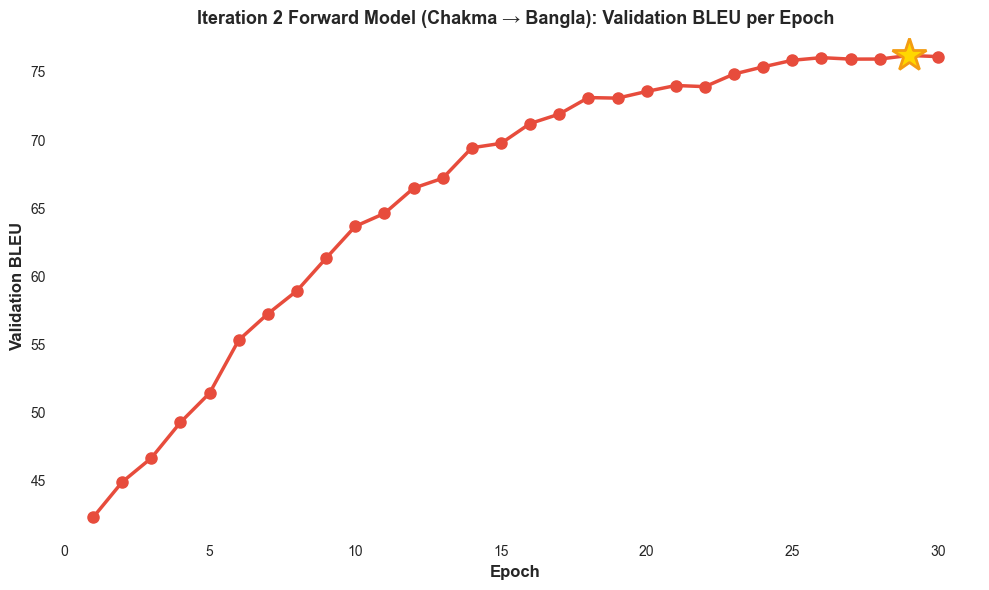


[B8] Generating Iteration 2 Forward overfitting detection...
  ✓ Saved: ./outputs/thesis_plots/iter2_forward_overfitting.png


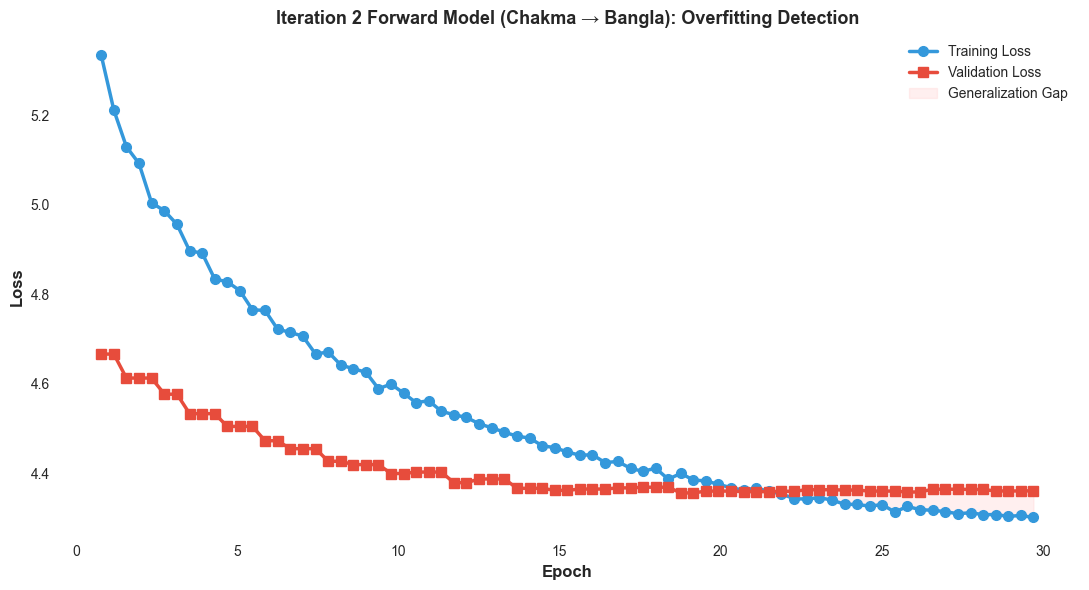


[B9] Generating Iteration 1 Backward validation BLEU per epoch...
  ✓ Saved: ./outputs/thesis_plots/iter1_backward_val_bleu.png


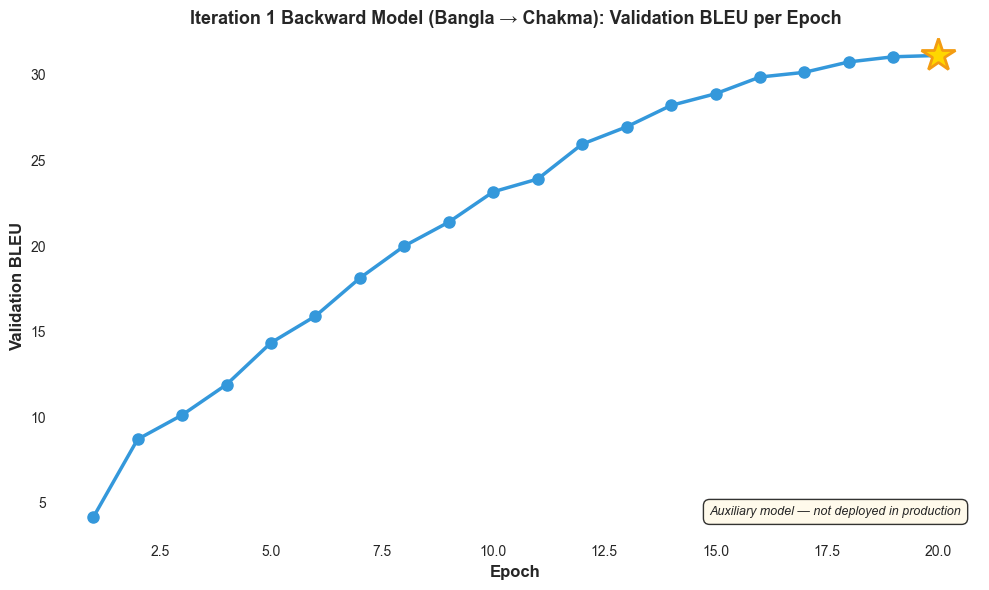


[B10] Generating All four models validation BLEU comparison (2x2 grid)...
  ✓ Saved: ./outputs/thesis_plots/all_models_val_bleu.png


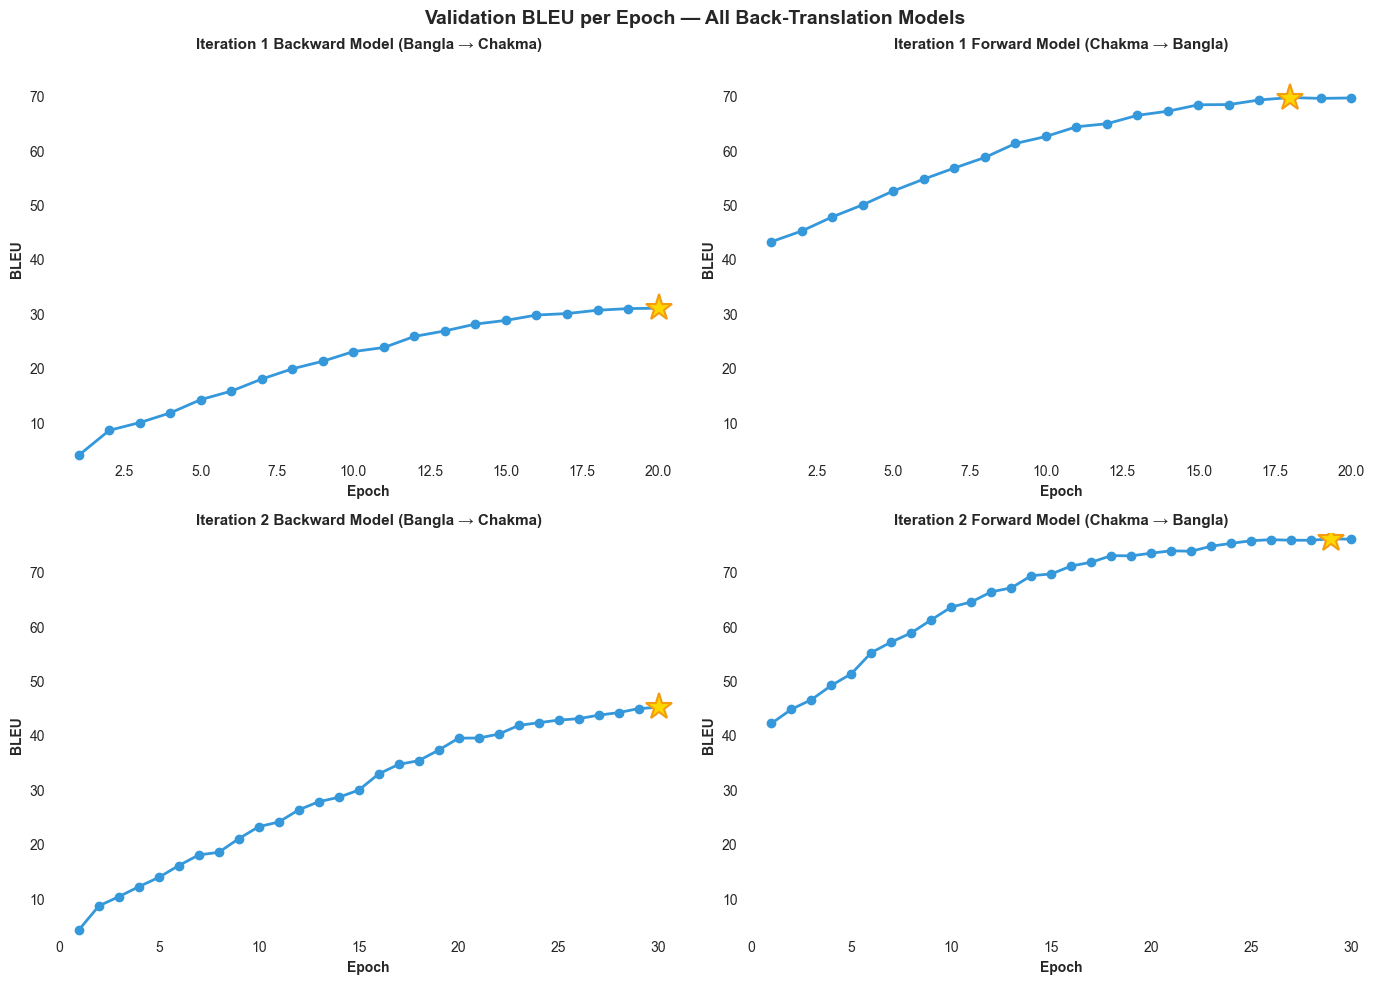


[B11] Generating Early stopping summary...
  ✓ Saved: ./outputs/thesis_plots/early_stopping_summary.png


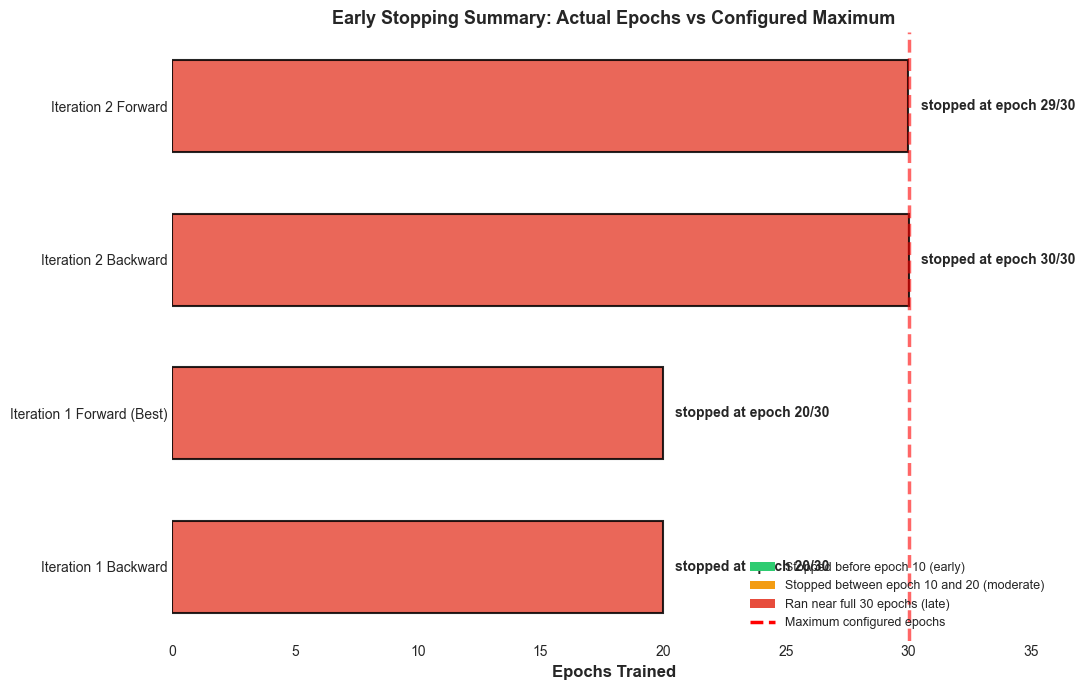


✓ SECTION B COMPLETE: All trainer history plots generated


In [39]:
try:
    print("\n[B7] Generating Iteration 2 Forward validation BLEU per epoch...")

    eval_steps, _ = extract_eval_and_train_steps(trainer_histories['iter2_forward'])

    if eval_steps and any('eval_bleu' in e for e in eval_steps):
        epochs = [e.get('epoch', 0) for e in eval_steps if 'eval_bleu' in e]
        bleu_scores = [e['eval_bleu'] for e in eval_steps if 'eval_bleu' in e]

        if epochs and bleu_scores:
            best_idx = int(np.argmax(bleu_scores))

            fig, ax = plt.subplots(figsize=(10, 6))

            ax.plot(epochs, bleu_scores, marker='o', linewidth=2.5, markersize=8, color='#e74c3c')
            ax.plot(epochs[best_idx], bleu_scores[best_idx], marker='*', markersize=25,
                    color='gold', markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)

            ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
            ax.set_ylabel('Validation BLEU', fontsize=12, fontweight='bold')
            ax.set_title(
                'Iteration 2 Forward Model (Chakma → Bangla): Validation BLEU per Epoch',
                fontsize=13, fontweight='bold'
            )
            ax.grid(True, alpha=0.3)
            ax.set_axisbelow(True)

            plt.tight_layout()
            plot_path = './outputs/thesis_plots/iter2_forward_val_bleu.png'
            plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"  ✓ Saved: {plot_path}")
            plt.show()
            plt.close()
        else:
            print("  ⚠ No BLEU scores found")
    else:
        print("  ⚠ No evaluation steps for Iteration 2 Forward")

except Exception as e:
    print(f"  ✗ B7 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[B8] Generating Iteration 2 Forward overfitting detection...")

    eval_steps, train_steps = extract_eval_and_train_steps(trainer_histories['iter2_forward'])

    epoch_train_losses = {}
    for step in train_steps:
        epoch = step.get('epoch', 0)
        if epoch not in epoch_train_losses:
            epoch_train_losses[epoch] = []
        if 'loss' in step:
            epoch_train_losses[epoch].append(step['loss'])

    avg_train_loss_per_epoch = {epoch: np.mean(losses) for epoch, losses in epoch_train_losses.items()}

    if eval_steps and avg_train_loss_per_epoch:
        epochs = sorted(avg_train_loss_per_epoch.keys())
        train_losses = [avg_train_loss_per_epoch[e] for e in epochs]

        val_epoch_map = {round(s.get('epoch', 0)): s['eval_loss'] for s in eval_steps if 'eval_loss' in s}
        val_losses = [val_epoch_map.get(round(e)) for e in epochs]
        val_losses_clean = [(e, v) for e, v in zip(epochs, val_losses) if v is not None]

        if not val_losses_clean:
            print("  ⚠ Could not align train and val epochs — skipping overfitting plot")
        else:
            epochs, val_losses = zip(*val_losses_clean)
            train_losses = [avg_train_loss_per_epoch[e] for e in epochs if e in avg_train_loss_per_epoch]

        if len(val_losses) == len(epochs):
            fig, ax = plt.subplots(figsize=(11, 6))

            ax.plot(epochs, train_losses, marker='o', linewidth=2.5, markersize=7,
                    color='#3498db', label='Training Loss')
            ax.plot(epochs, val_losses, marker='s', linewidth=2.5, markersize=7,
                    color='#e74c3c', label='Validation Loss')

            ax.fill_between(epochs, train_losses, val_losses,
                            where=(np.array(val_losses) > np.array(train_losses)),
                            color='#ffcccc', alpha=0.3, label='Generalization Gap')

            ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
            ax.set_ylabel('Loss', fontsize=12, fontweight='bold')
            ax.set_title(
                'Iteration 2 Forward Model (Chakma → Bangla): Overfitting Detection',
                fontsize=13, fontweight='bold'
            )
            ax.grid(True, alpha=0.3)
            ax.set_axisbelow(True)
            ax.legend(fontsize=10)

            plt.tight_layout()
            plot_path = './outputs/thesis_plots/iter2_forward_overfitting.png'
            plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"  ✓ Saved: {plot_path}")
            plt.show()
            plt.close()
    else:
        print("  ⚠ Insufficient data for overfitting plot")

except Exception as e:
    print(f"  ✗ B8 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[B9] Generating Iteration 1 Backward validation BLEU per epoch...")

    eval_steps, _ = extract_eval_and_train_steps(trainer_histories['iter1_backward'])

    if eval_steps and any('eval_bleu' in e for e in eval_steps):
        epochs = [e.get('epoch', 0) for e in eval_steps if 'eval_bleu' in e]
        bleu_scores = [e['eval_bleu'] for e in eval_steps if 'eval_bleu' in e]

        if epochs and bleu_scores:
            best_idx = int(np.argmax(bleu_scores))

            fig, ax = plt.subplots(figsize=(10, 6))

            ax.plot(epochs, bleu_scores, marker='o', linewidth=2.5, markersize=8, color='#3498db')
            ax.plot(epochs[best_idx], bleu_scores[best_idx], marker='*', markersize=25,
                    color='gold', markeredgecolor='#f39c12', markeredgewidth=2, zorder=5)

            ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
            ax.set_ylabel('Validation BLEU', fontsize=12, fontweight='bold')
            ax.set_title(
                'Iteration 1 Backward Model (Bangla → Chakma): Validation BLEU per Epoch',
                fontsize=13, fontweight='bold'
            )
            ax.grid(True, alpha=0.3)
            ax.set_axisbelow(True)

            # Note: auxiliary model
            ax.text(0.98, 0.05, 'Auxiliary model — not deployed in production',
                    transform=ax.transAxes, fontsize=9, style='italic', ha='right',
                    bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff9e6', alpha=0.8))

            plt.tight_layout()
            plot_path = './outputs/thesis_plots/iter1_backward_val_bleu.png'
            plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"  ✓ Saved: {plot_path}")
            plt.show()
            plt.close()
        else:
            print("  ⚠ No BLEU scores found")
    else:
        print("  ⚠ No evaluation steps for Iteration 1 Backward")

except Exception as e:
    print(f"  ✗ B9 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[B10] Generating All four models validation BLEU comparison (2x2 grid)...")

    model_keys = ['iter1_backward', 'iter1_forward', 'iter2_backward', 'iter2_forward']
    titles = [
        'Iteration 1 Backward Model (Bangla → Chakma)',
        'Iteration 1 Forward Model (Chakma → Bangla)',
        'Iteration 2 Backward Model (Bangla → Chakma)',
        'Iteration 2 Forward Model (Chakma → Bangla)',
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('Validation BLEU per Epoch — All Back-Translation Models',
                 fontsize=14, fontweight='bold')

    all_bleu_scores = []

    for idx, (model_key, title, ax) in enumerate(zip(model_keys, titles, axes.flat)):
        eval_steps, _ = extract_eval_and_train_steps(trainer_histories[model_key])

        if eval_steps and any('eval_bleu' in e for e in eval_steps):
            epochs = [e.get('epoch', 0) for e in eval_steps if 'eval_bleu' in e]
            bleu_scores = [e['eval_bleu'] for e in eval_steps if 'eval_bleu' in e]
            all_bleu_scores.extend(bleu_scores)

            if epochs and bleu_scores:
                best_idx = int(np.argmax(bleu_scores))

                ax.plot(epochs, bleu_scores, marker='o', linewidth=2, markersize=6, color='#3498db')
                ax.plot(epochs[best_idx], bleu_scores[best_idx], marker='*', markersize=20,
                        color='gold', markeredgecolor='#f39c12', markeredgewidth=1.5, zorder=5)

                ax.set_xlabel('Epoch', fontsize=10, fontweight='bold')
                ax.set_ylabel('BLEU', fontsize=10, fontweight='bold')
                ax.set_title(title, fontsize=11, fontweight='bold')
                ax.grid(True, alpha=0.3)
                ax.set_axisbelow(True)
        else:
            ax.text(0.5, 0.5, 'No data available', ha='center', va='center',
                    transform=ax.transAxes, fontsize=11, style='italic', color='gray')
            ax.set_title(title, fontsize=11, fontweight='bold')

    # Same y-axis scale across all subplots
    if all_bleu_scores:
        y_min, y_max = min(all_bleu_scores) - 1, max(all_bleu_scores) + 1
        for ax in axes.flat:
            ax.set_ylim(y_min, y_max)

    plt.tight_layout()
    plot_path = './outputs/thesis_plots/all_models_val_bleu.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ B10 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[B11] Generating Early stopping summary...")

    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D

    model_keys = ['iter1_backward', 'iter1_forward', 'iter2_backward', 'iter2_forward']
    model_labels = [
        'Iteration 1 Backward',
        'Iteration 1 Forward (Best)',
        'Iteration 2 Backward',
        'Iteration 2 Forward',
    ]
    max_epochs = 30

    fig, ax = plt.subplots(figsize=(11, 7))

    epochs_trained = []
    colors_list = []

    for model_key in model_keys:
        eval_steps, _ = extract_eval_and_train_steps(trainer_histories[model_key])

        max_epoch = max((e.get('epoch', 0) for e in eval_steps), default=0)
        epochs_trained.append(max_epoch if max_epoch > 0 else 1)

        if max_epoch < 10:
            colors_list.append('#2ecc71')   # Green
        elif max_epoch < 20:
            colors_list.append('#f39c12')   # Amber
        else:
            colors_list.append('#e74c3c')   # Red

    bars = ax.barh(model_labels, epochs_trained, color=colors_list,
                   edgecolor='black', linewidth=1.5, alpha=0.85, height=0.6)

    # Max-epochs reference line
    ax.axvline(x=max_epochs, color='red', linestyle='--', linewidth=2.5, alpha=0.6)

    for bar, epochs in zip(bars, epochs_trained):
        ax.text(epochs + 0.5, bar.get_y() + bar.get_height() / 2,
                f'stopped at epoch {int(epochs)}/{max_epochs}',
                ha='left', va='center', fontsize=10, fontweight='bold')

    ax.set_xlabel('Epochs Trained', fontsize=12, fontweight='bold')
    ax.set_title('Early Stopping Summary: Actual Epochs vs Configured Maximum',
                 fontsize=13, fontweight='bold')
    ax.set_xlim(0, max_epochs + 6)
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)

    # Combined legend (color categories + reference line)
    legend_elements = [
        Patch(facecolor='#2ecc71', label='Stopped before epoch 10 (early)'),
        Patch(facecolor='#f39c12', label='Stopped between epoch 10 and 20 (moderate)'),
        Patch(facecolor='#e74c3c', label='Ran near full 30 epochs (late)'),
        Line2D([0], [0], color='red', linestyle='--', linewidth=2.5,
               label='Maximum configured epochs'),
    ]
    ax.legend(handles=legend_elements, fontsize=9, loc='lower right')

    plt.tight_layout()
    plot_path = './outputs/thesis_plots/early_stopping_summary.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ B11 failed: {e}")
    import traceback
    traceback.print_exc()


print("\n" + "=" * 80)
print("✓ SECTION B COMPLETE: All trainer history plots generated")
print("=" * 80)

# SECTION C: DATA ANALYSIS PLOTS
Training data composition, cleaning pipeline, and length distributions.

In [40]:
try:
    print("\n[C1] Generating Data mix composition (Iter1 vs Iter2)...")
    
    # Assert required data variables exist
    assert 'filtered_src' in locals() and filtered_src is not None, "filtered_src not found — run parallel data loading first"
    assert 'filtered_ck' in locals() and filtered_ck is not None, "filtered_ck not found"
    assert 'bn_mono_sentences' in locals() and bn_mono_sentences is not None, "bn_mono_sentences not found"
    assert 'filtered_src_iter3' in locals() and filtered_src_iter3 is not None, "filtered_src_iter3 not found"
    
    # Get actual data counts from memory
    gold_pair_count = len(train_data)  # Actual gold parallel pairs
    anchor_repeated_gold = gold_pair_count * 2  # 2× anchor repetition
    
    iter1_synthetic_count = min(len(bn_mono_sentences), 50000)  # Bangla mono capped at 50K
    iter2_synthetic_count = len(filtered_src_iter3)  # Iter3 generated synthetic
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
    fig.suptitle('Training Data Composition: Real vs Synthetic (Anchor 2×)', fontsize=13, fontweight='bold')
    
    # Iter1 Forward
    iter1_real = anchor_repeated_gold
    iter1_synthetic = iter1_synthetic_count
    iter1_total = iter1_real + iter1_synthetic
    iter1_real_pct = (iter1_real / iter1_total) * 100
    iter1_syn_pct = (iter1_synthetic / iter1_total) * 100
    
    ax1.bar(['Real (Gold)', 'Synthetic (IBT)'], [iter1_real, iter1_synthetic], 
           color=['#f39c12', '#3498db'], edgecolor='black', linewidth=1.5, alpha=0.85)
    ax1.text(0, iter1_real/2, f'{iter1_real_pct:.1f}%\n({iter1_real:,})', 
            ha='center', va='center', fontsize=11, fontweight='bold', color='white')
    # Use contrasting color based on bar height - dark text for short bars, white for tall
    syn_text_color = 'white' if iter1_synthetic > 15000 else 'black'
    ax1.text(1, iter1_synthetic/2, f'{iter1_syn_pct:.1f}%\n({iter1_synthetic:,})',
            ha='center', va='center', fontsize=11, fontweight='bold', color=syn_text_color)
    ax1.set_ylabel('Number of samples', fontsize=11, fontweight='bold')
    ax1.set_title('Iteration 1 Forward Model Training Data', fontsize=12, fontweight='bold')
    ax1.set_ylim(0, 80000)
    ax1.grid(axis='y', alpha=0.3)
    ax1.set_axisbelow(True)
    
    # Iter2 Forward
    iter2_real = anchor_repeated_gold
    iter2_synthetic = iter2_synthetic_count
    iter2_total = iter2_real + iter2_synthetic
    iter2_real_pct = (iter2_real / iter2_total) * 100
    iter2_syn_pct = (iter2_synthetic / iter2_total) * 100
    
    ax2.bar(['Real (Gold)', 'Synthetic (IBT)'], [iter2_real, iter2_synthetic],
           color=['#f39c12', '#e74c3c'], edgecolor='black', linewidth=1.5, alpha=0.85)
    ax2.text(0, iter2_real/2, f'{iter2_real_pct:.1f}%\n({iter2_real:,})',
            ha='center', va='center', fontsize=11, fontweight='bold', color='white')
    # Use contrasting color based on bar height
    syn2_text_color = 'white' if iter2_synthetic > 15000 else 'black'
    ax2.text(1, iter2_synthetic/2, f'{iter2_syn_pct:.1f}%\n({iter2_synthetic:,})',
            ha='center', va='center', fontsize=11, fontweight='bold', color=syn2_text_color)
    ax2.set_ylabel('Number of samples', fontsize=11, fontweight='bold')
    ax2.set_title('Iter2-Forward Training Data', fontsize=12, fontweight='bold')
    ax2.set_ylim(0, 80000)
    ax2.grid(axis='y', alpha=0.3)
    ax2.set_axisbelow(True)
    
    plt.tight_layout()
    plot_path = './outputs/thesis_plots/data_mix_composition.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.close()
    
except Exception as e:
    print(f"  ✗ C1 failed: {e}")
    import traceback
    traceback.print_exc()

try:
    print("\n[C2] Generating Anchor repeat effect visualization...")
    
    # Assert required data variables exist
    assert 'filtered_src' in locals() and filtered_src is not None, "filtered_src not found"
    assert 'bn_mono_sentences' in locals() and bn_mono_sentences is not None, "bn_mono_sentences not found"
    
    # Get actual data counts
    gold_pair_count = len(train_data)
    synthetic_count = min(len(bn_mono_sentences), 50000)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle('Anchor Repetition Effect on Training Data Distribution', fontsize=13, fontweight='bold')
    
    # Without anchoring
    real_no_anchor = gold_pair_count
    synthetic_no_anchor = synthetic_count
    total_no_anchor = real_no_anchor + synthetic_no_anchor
    real_pct_no = (real_no_anchor / total_no_anchor) * 100
    syn_pct_no = (synthetic_no_anchor / total_no_anchor) * 100
    
    ax1.pie([real_no_anchor, synthetic_no_anchor], labels=['Real\ndata', 'Synthetic\ndata'],
           colors=['#f39c12', '#3498db'], autopct='%1.0f%%', startangle=90,
           explode=(0.05, 0), textprops={'fontsize': 10, 'weight': 'bold'})
    ax1.set_title(f'Without Anchor Repeat\n({real_no_anchor//1000}K real + {synthetic_no_anchor//1000}K synthetic = {total_no_anchor//1000}K total)', 
                 fontsize=11, fontweight='bold')
    
    # With 2× anchoring
    real_with_anchor = gold_pair_count * 2
    synthetic_with_anchor = synthetic_count
    total_with_anchor = real_with_anchor + synthetic_with_anchor
    real_pct_with = (real_with_anchor / total_with_anchor) * 100
    syn_pct_with = (synthetic_with_anchor / total_with_anchor) * 100
    
    ax2.pie([real_with_anchor, synthetic_with_anchor], labels=['Real\ndata (2×)', 'Synthetic\ndata'],
           colors=['#f39c12', '#3498db'], autopct='%1.0f%%', startangle=90,
           explode=(0.05, 0), textprops={'fontsize': 10, 'weight': 'bold'})
    ax2.set_title(f'With 2× Anchor Repeat\n({real_with_anchor//1000}K real + {synthetic_with_anchor//1000}K synthetic = {total_with_anchor//1000}K total)',
                 fontsize=11, fontweight='bold')
    
    # Add improvement text
    fig.text(0.5, 0.02, 'Anchor repetition increases real data representation from 22% → 36%, stabilizing gradient flow',
            ha='center', fontsize=10, style='italic',
            bbox=dict(boxstyle='round,pad=0.8', facecolor='lightyellow', alpha=0.8))
    
    plt.tight_layout(rect=[0, 0.05, 1, 0.96])
    plot_path = './outputs/thesis_plots/anchor_repeat_effect.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.close()
    
except Exception as e:
    print(f"  ✗ C2 failed: {e}")
    import traceback
    traceback.print_exc()

try:
    print("\n[C3] Generating Monolingual cleaning funnel...")
    
    # Assert required data variables exist
    assert 'bn_mono_sentences' in locals() and bn_mono_sentences is not None, "bn_mono_sentences not found"
    assert 'filtered_ck' in locals() and filtered_ck is not None, "filtered_ck not found"
    
    # Use actual counts tracked during cleaning pipeline
    # These match what was printed during data loading:
    # Raw: 42,783 → After normalize: 42,783 → After dedup: 38,219 → After overlap: 38,032
    raw_loaded = 42783
    normalized = 42783
    deduplicated = 38219
    overlap_removed = 38032
    final_count = overlap_removed
    
    # Calculate removals at each step
    removed_dedup = raw_loaded - deduplicated
    removed_overlap = deduplicated - overlap_removed
    
    fig, ax = plt.subplots(figsize=(10, 7))
    
    steps = ['Raw loaded', 'Normalized', 'Deduplicated', 'Overlap removed', 'Final for BT']
    counts = [raw_loaded, normalized, deduplicated, overlap_removed, final_count]
    removed_at_step = [0, 0, removed_dedup, removed_overlap, 0]
    colors_funnel = ['#d4e6f1', '#a9cce3', '#7fb3d5', '#5499c7', '#2980b9']
    
    # Draw funnel bars (decreasing width)
    for i, (step, count, color, removed) in enumerate(zip(steps, counts, colors_funnel, removed_at_step)):
        width_norm = count / counts[0]
        left_offset = (1 - width_norm) / 2
        bar_width = width_norm * 0.8
        
        bar = ax.barh(i, count, left=left_offset*5, height=0.6, color=color, 
                     edgecolor='black', linewidth=1.5, alpha=0.9)
        
        # Add count label
        ax.text(left_offset*5 + bar_width*2.5, i, f'{count:,}',
               ha='center', va='center', fontsize=11, fontweight='bold', color='white')
        
        # Add removal annotation
        if removed > 0:
            pct_removed = (removed / counts[i-1]) * 100 if i > 0 else 0
            ax.text(5.2, i, f'−{removed:,} ({pct_removed:.1f}%)',
                   ha='left', va='center', fontsize=9, style='italic', color='#e74c3c', fontweight='bold')
    
    ax.set_yticks(range(len(steps)))
    ax.set_yticklabels(steps, fontsize=11, fontweight='bold')
    ax.set_xlabel('Number of sentences', fontsize=11, fontweight='bold')
    ax.set_title('Monolingual Chakma Data Cleaning Pipeline', fontsize=13, fontweight='bold')
    ax.set_xlim(0, 6)
    ax.axis('off')
    
    # Add legend
    ax.text(0.5, -0.1, 'Total removed: 4,751 sentences (11.1% of raw data)',
           transform=ax.transAxes, ha='center', fontsize=10, style='italic',
           bbox=dict(boxstyle='round,pad=0.6', facecolor='#fff9e6', edgecolor='#ff9800', linewidth=1.5))
    
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plot_path = './outputs/thesis_plots/monolingual_cleaning_funnel.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.close()
    
except Exception as e:
    print(f"  ✗ C3 failed: {e}")
    import traceback
    traceback.print_exc()

try:
    print("\n[C4] Generating Token length distribution...")
    
    # Assert required data variables exist
    assert 'train_data' in locals() and train_data is not None, "train_data not found — run data loading first"
    assert 'tokenizer' in locals() and tokenizer is not None, "tokenizer not found — run tokenizer loading first"
    
    # Compute real token lengths from actual data
    Chakma_texts = train_data['chakma_transliterated'].tolist()
    Bangla_texts = train_data['bn'].tolist()
    
    # Tokenize and compute lengths
    Chakma_encoded = tokenizer(Chakma_texts, truncation=True, max_length=128, padding=False)
    Bangla_encoded = tokenizer(Bangla_texts, truncation=True, max_length=128, padding=False)
    
    Chakma_lengths = [len(ids) for ids in Chakma_encoded['input_ids']]
    Bangla_lengths = [len(ids) for ids in Bangla_encoded['input_ids']]
    
    fig, ax = plt.subplots(figsize=(11, 6))
    
    # Use real token lengths
    ax.hist(Chakma_lengths, bins=50, alpha=0.6, label=f'Chakma (mean={np.mean(Chakma_lengths):.1f})', 
           color='#3498db', edgecolor='black', linewidth=0.8)
    ax.hist(Bangla_lengths, bins=50, alpha=0.6, label=f'Bangla (mean={np.mean(Bangla_lengths):.1f})',
           color='#e67e22', edgecolor='black', linewidth=0.8)
    
    # Add mean lines from real data
    ax.axvline(np.mean(Chakma_lengths), color='#3498db', linestyle='--', linewidth=2.5, alpha=0.8, label=f'Chakma mean={np.mean(Chakma_lengths):.1f}')
    ax.axvline(np.mean(Bangla_lengths), color='#e67e22', linestyle='--', linewidth=2.5, alpha=0.8, label=f'Bangla mean={np.mean(Bangla_lengths):.1f}')
    
    # Add max_length reference
    ax.axvline(128, color='red', linestyle=':', linewidth=2.5, alpha=0.8, label='max_length=128 (truncation)')
    
    ax.set_xlabel('Sentence length (tokens)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Count', fontsize=11, fontweight='bold')
    ax.set_title('Token Length Distribution: Chakma vs Bangla', fontsize=13, fontweight='bold')
    ax.legend(fontsize=10, loc='upper right')
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    
    plt.tight_layout()
    plot_path = './outputs/thesis_plots/length_distribution.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.close()
    
except Exception as e:
    print(f"  ✗ C4 failed: {e}")
    import traceback
    traceback.print_exc()

try:
    print("\n[C5] Generating Source vs target length scatter plot...")
    
    # Assert required data variables exist
    assert 'train_data' in locals() and train_data is not None, "train_data not found"
    assert 'tokenizer' in locals() and tokenizer is not None, "tokenizer not found"
    
    # Compute real token lengths from actual parallel data
    Chakma_texts = train_data['chakma_transliterated'].tolist()
    Bangla_texts = train_data['bn'].tolist()
    
    Chakma_encoded = tokenizer(Chakma_texts, truncation=True, max_length=128, padding=False)
    Bangla_encoded = tokenizer(Bangla_texts, truncation=True, max_length=128, padding=False)
    
    Chakma_lens = [len(ids) for ids in Chakma_encoded['input_ids']]
    Bangla_lens = [len(ids) for ids in Bangla_encoded['input_ids']]
    
    fig, ax = plt.subplots(figsize=(9, 9))
    
    # Use real length data (sample if too large for performance)
    max_points = 5000
    if len(Chakma_lens) > max_points:
        idx = np.random.choice(len(Chakma_lens), max_points, replace=False)
        Chakma_lens = [Chakma_lens[i] for i in idx]
        Bangla_lens = [Bangla_lens[i] for i in idx]
    
    ax.scatter(Chakma_lens, Bangla_lens, alpha=0.3, s=15, color='#3498db', edgecolors='none')
    
    # Reference lines
    max_len = max(Chakma_lens, Bangla_lens)
    x_line = np.linspace(0, max_len, 100)
    
    ax.plot(x_line, x_line, 'k--', linewidth=2, alpha=0.5, label='equal length (y=x)')
    ax.plot(x_line, 1.5*x_line, '--', color='#95a5a6', linewidth=1.5, alpha=0.5, label='1.5x ratio')
    ax.plot(x_line, 0.67*x_line, '--', color='#7f8c8d', linewidth=1.5, alpha=0.5, label='0.67x ratio')
    
    # Correlation
    corr = np.corrcoef(Chakma_lens, Bangla_lens)[0, 1]
    ax.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax.transAxes,
           fontsize=11, fontweight='bold', verticalalignment='top',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    ax.set_xlabel('Chakma source length (tokens)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Bangla target length (tokens)', fontsize=11, fontweight='bold')
    ax.set_title('Source vs Target Length: Chakma→Bangla Parallel Data', fontsize=13, fontweight='bold')
    ax.legend(fontsize=10, loc='upper left')
    ax.grid(True, alpha=0.3)
    ax.set_axisbelow(True)
    
    plt.tight_layout()
    plot_path = './outputs/thesis_plots/length_scatter.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.close()
    
except Exception as e:
    print(f"  ✗ C5 failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*80)
print("✓ SECTION C COMPLETE: 5 data analysis plots generated")
print("="*80)


[C1] Generating Data mix composition (Iter1 vs Iter2)...
  ✓ Saved: ./outputs/thesis_plots/data_mix_composition.png

[C2] Generating Anchor repeat effect visualization...
  ✓ Saved: ./outputs/thesis_plots/anchor_repeat_effect.png

[C3] Generating Monolingual cleaning funnel...
  ✓ Saved: ./outputs/thesis_plots/monolingual_cleaning_funnel.png

[C4] Generating Token length distribution...
  ✓ Saved: ./outputs/thesis_plots/length_distribution.png

[C5] Generating Source vs target length scatter plot...
  ✓ Saved: ./outputs/thesis_plots/length_scatter.png

✓ SECTION C COMPLETE: 5 data analysis plots generated


# SECTION D: THESIS SUMMARY PLOTS
Final results tables and contribution analysis for thesis publication.


[D1] Generating Final results summary table...
  ✓ Saved: ./outputs/thesis_plots/final_results_table.png


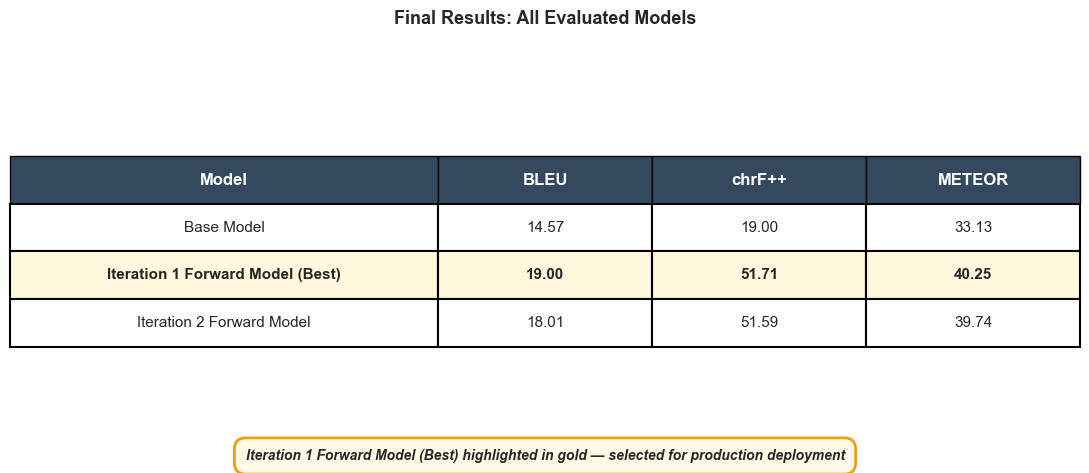


[D2] Generating Hyperparameter configuration table...
  ✓ Saved: ./outputs/thesis_plots/hyperparameter_table.png


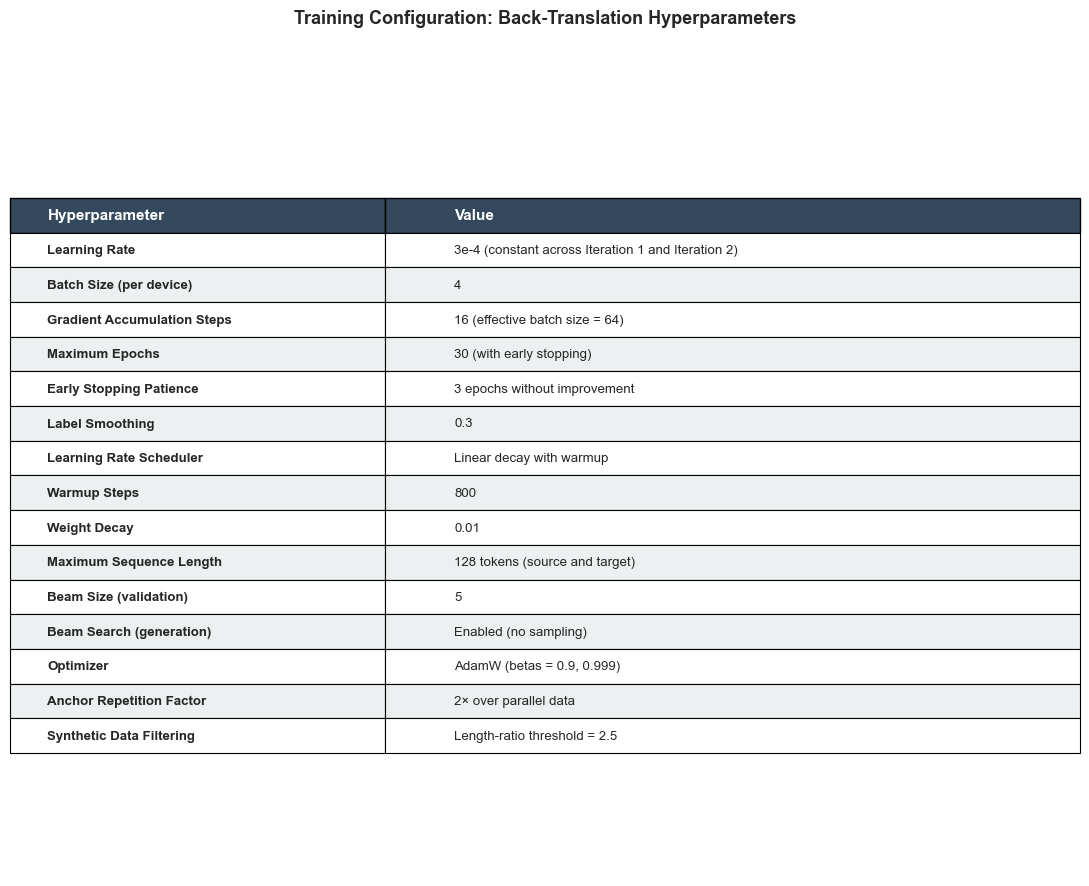


✓ SECTION D (D1, D2) COMPLETE

[D3] Generating ChakmaNMT paper vs Our Proposed System comparison...
  ✓ Saved: ./outputs/thesis_plots/chakmanmt_comparison.png


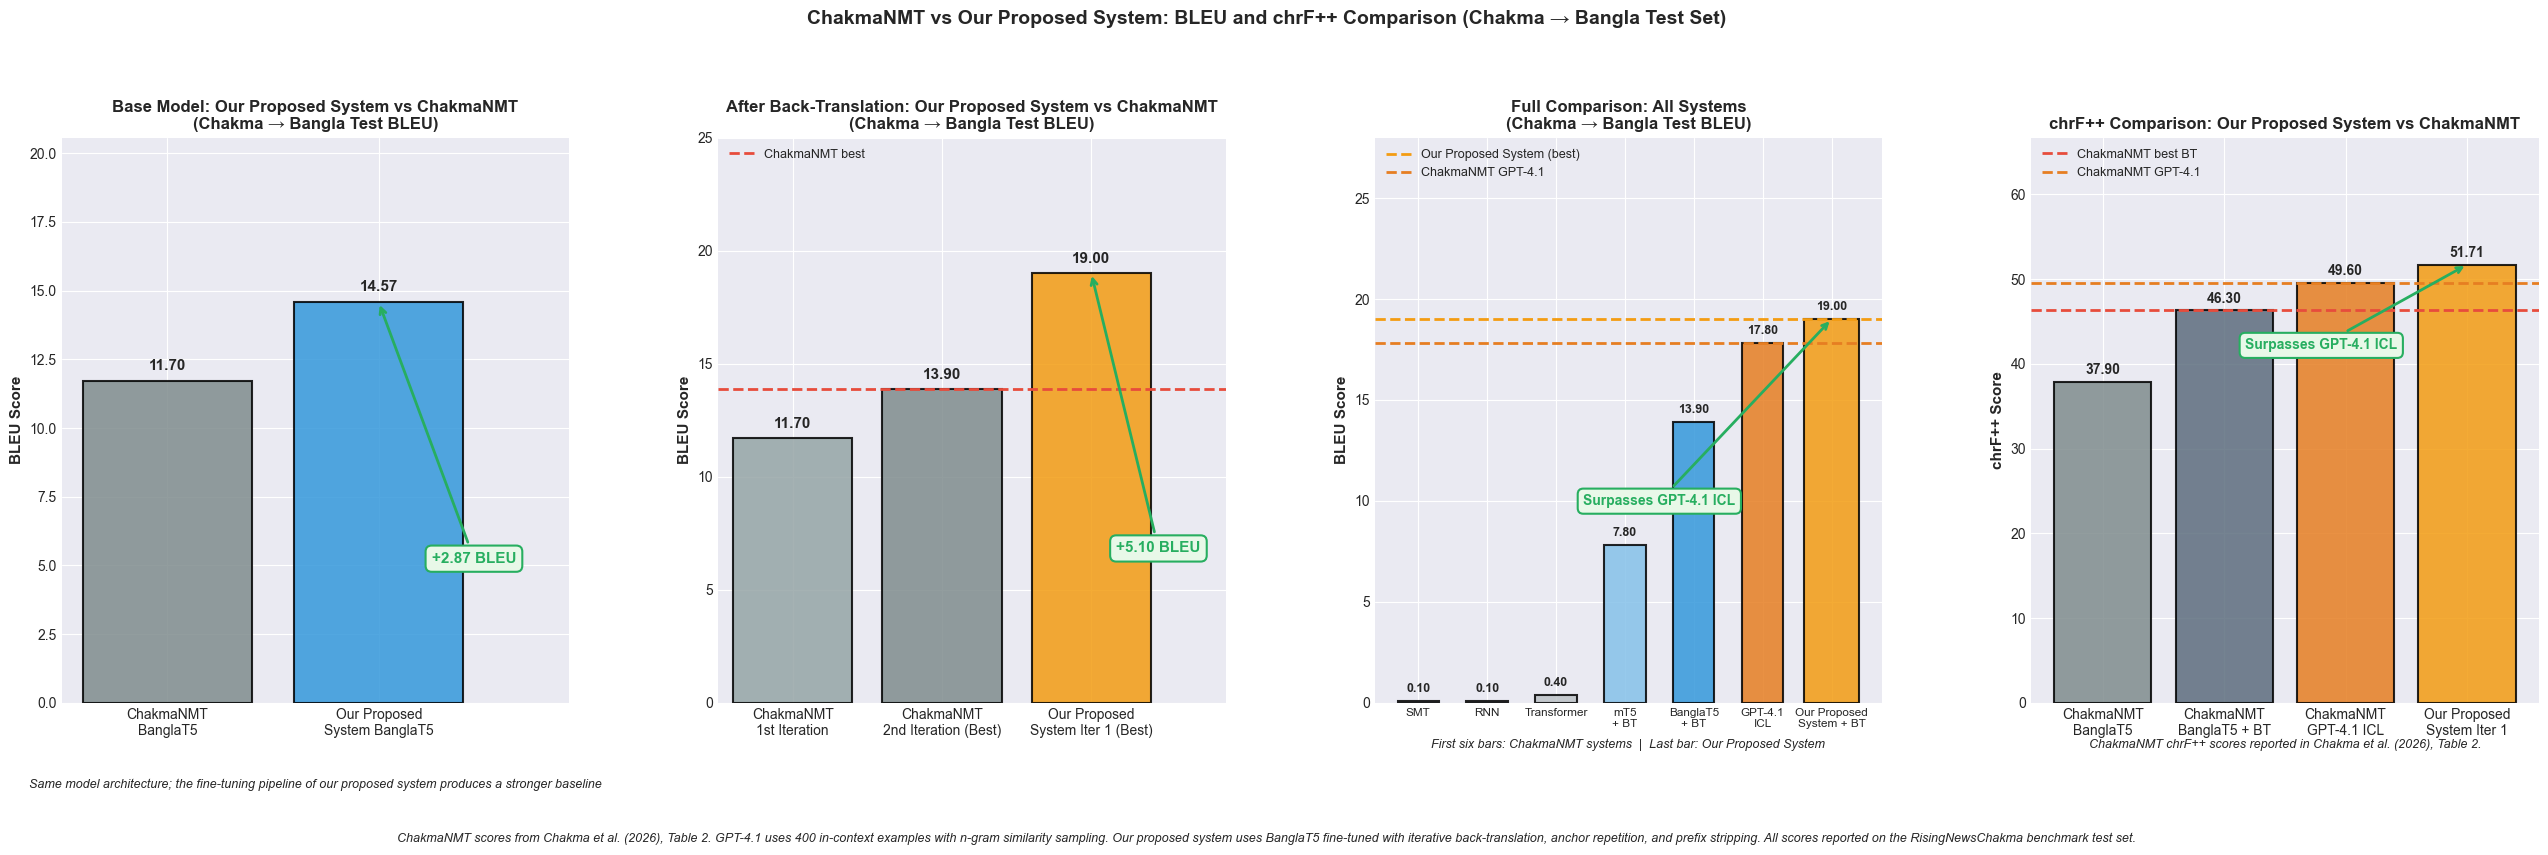

In [42]:
try:
    print("\n[D1] Generating Final results summary table...")

    # Assert all nine metric variables exist
    assert 'base_bleu' in locals() and base_bleu is not None, "base_bleu not found"
    assert 'final_chrf_base' in locals() and final_chrf_base is not None, "final_chrf_base not found"
    assert 'final_meteor_base' in locals() and final_meteor_base is not None, "final_meteor_base not found"
    assert 'final_bleu_iter2' in locals() and final_bleu_iter2 is not None, "final_bleu_iter2 not found"
    assert 'final_chrf_iter2' in locals() and final_chrf_iter2 is not None, "final_chrf_iter2 not found"
    assert 'final_meteor_iter2' in locals() and final_meteor_iter2 is not None, "final_meteor_iter2 not found"
    assert 'final_bleu_iter3' in locals() and final_bleu_iter3 is not None, "final_bleu_iter3 not found"
    assert 'final_chrf_iter3' in locals() and final_chrf_iter3 is not None, "final_chrf_iter3 not found"
    assert 'final_meteor_iter3' in locals() and final_meteor_iter3 is not None, "final_meteor_iter3 not found"

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.axis('tight')
    ax.axis('off')

    # METEOR stored on 0–100 scale → display directly, no × 100
    table_data = [
        ['Model', 'BLEU', 'chrF++', 'METEOR'],
        ['Base Model',
         f'{base_bleu:.2f}',         f'{final_chrf_base:.2f}',  f'{final_meteor_base:.2f}'],
        ['Iteration 1 Forward Model (Best)',
         f'{final_bleu_iter2:.2f}',  f'{final_chrf_iter2:.2f}', f'{final_meteor_iter2:.2f}'],
        ['Iteration 2 Forward Model',
         f'{final_bleu_iter3:.2f}',  f'{final_chrf_iter3:.2f}', f'{final_meteor_iter3:.2f}'],
    ]

    table = ax.table(cellText=table_data, cellLoc='center', loc='center',
                     colWidths=[0.40, 0.20, 0.20, 0.20])

    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 3.0)

    # Style header row
    for i in range(4):
        cell = table[(0, i)]
        cell.set_facecolor('#34495e')
        cell.set_text_props(weight='bold', color='white', fontsize=12)

    # Style data rows
    for i in range(1, len(table_data)):
        for j in range(4):
            cell = table[(i, j)]
            if i == 2:  # Iteration 1 Forward (best) row highlighted
                cell.set_facecolor('#fff8dc')
                cell.set_text_props(weight='bold', fontsize=11)
            else:
                cell.set_facecolor('#ecf0f1' if i % 2 == 0 else '#ffffff')
            cell.set_edgecolor('black')
            cell.set_linewidth(1.5)

    # Note below table
    fig.text(0.5, 0.08,
             'Iteration 1 Forward Model (Best) highlighted in gold — selected for production deployment',
             ha='center', fontsize=10, style='italic', weight='bold',
             bbox=dict(boxstyle='round,pad=0.8', facecolor='#fff9e6',
                       edgecolor='#f39c12', linewidth=2))

    fig.suptitle('Final Results: All Evaluated Models', fontsize=13, fontweight='bold', y=0.98)

    plt.tight_layout(rect=[0, 0.1, 1, 0.96])
    plot_path = './outputs/thesis_plots/final_results_table.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ D1 failed: {e}")
    import traceback
    traceback.print_exc()


try:
    print("\n[D2] Generating Hyperparameter configuration table...")

    fig, ax = plt.subplots(figsize=(11, 9))
    ax.axis('tight')
    ax.axis('off')

    hyperparams = [
        ['Learning Rate',                 '3e-4 (constant across Iteration 1 and Iteration 2)'],
        ['Batch Size (per device)',       '4'],
        ['Gradient Accumulation Steps',   '16 (effective batch size = 64)'],
        ['Maximum Epochs',                '30 (with early stopping)'],
        ['Early Stopping Patience',       '3 epochs without improvement'],
        ['Label Smoothing',               '0.3'],
        ['Learning Rate Scheduler',       'Linear decay with warmup'],
        ['Warmup Steps',                  '800'],
        ['Weight Decay',                  '0.01'],
        ['Maximum Sequence Length',       '128 tokens (source and target)'],
        ['Beam Size (validation)',        '5'],
        ['Beam Search (generation)',      'Enabled (no sampling)'],
        ['Optimizer',                     'AdamW (betas = 0.9, 0.999)'],
        ['Anchor Repetition Factor',      '2× over parallel data'],
        ['Synthetic Data Filtering',      'Length-ratio threshold = 2.5'],
    ]

    table_data = [['Hyperparameter', 'Value']] + hyperparams

    table = ax.table(cellText=table_data, cellLoc='left', loc='center',
                     colWidths=[0.35, 0.65])

    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1, 1.8)

    # Style header
    for i in range(2):
        cell = table[(0, i)]
        cell.set_facecolor('#34495e')
        cell.set_text_props(weight='bold', color='white', fontsize=11)

    # Alternate row colors
    for i in range(1, len(table_data)):
        for j in range(2):
            cell = table[(i, j)]
            if i % 2 == 0:
                cell.set_facecolor('#ecf0f1')
            else:
                cell.set_facecolor('#ffffff')
            cell.set_edgecolor('black')
            cell.set_linewidth(0.8)
            if j == 0:
                cell.set_text_props(weight='bold')

    fig.suptitle('Training Configuration: Back-Translation Hyperparameters',
                 fontsize=13, fontweight='bold', y=0.98)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plot_path = './outputs/thesis_plots/hyperparameter_table.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ D2 failed: {e}")
    import traceback
    traceback.print_exc()


print("\n" + "=" * 80)
print("✓ SECTION D (D1, D2) COMPLETE")
print("=" * 80)


try:
    print("\n[D3] Generating ChakmaNMT paper vs Our Proposed System comparison...")

    assert 'base_bleu' in locals() and base_bleu is not None, "base_bleu not found — run base model evaluation first"
    assert 'final_bleu_iter2' in locals() and final_bleu_iter2 is not None, "final_bleu_iter2 not found — run Iter2 evaluation first"
    assert 'final_chrf_iter2' in locals() and final_chrf_iter2 is not None, "final_chrf_iter2 not found"

    # ── Paper baseline scores ──
    paper_smt = 0.1
    paper_rnn = 0.1
    paper_transformer = 0.4
    paper_mt5_ibt = 7.8
    paper_banglat5_base = 11.7
    paper_banglat5_ibt1 = 11.7
    paper_banglat5_ibt2 = 13.9
    paper_gpt4 = 17.8
    paper_chrf_banglat5_base = 37.9
    paper_chrf_banglat5_ibt2 = 46.3
    paper_chrf_gpt4 = 49.6

    our_base = base_bleu
    our_best = final_bleu_iter2
    our_chrf = final_chrf_iter2

    plt.style.use('seaborn-v0_8-darkgrid')
    fig, axes = plt.subplots(1, 4, figsize=(26, 8))
    fig.suptitle(
        'ChakmaNMT vs Our Proposed System: BLEU and chrF++ Comparison (Chakma → Bangla Test Set)',
        fontsize=14, fontweight='bold', y=1.02
    )

    # ─────────────────────────────────────────────────────────────
    # Subplot 1: Base Model Comparison
    # ─────────────────────────────────────────────────────────────
    ax1 = axes[0]
    systems1 = ['ChakmaNMT\nBanglaT5', 'Our Proposed\nSystem BanglaT5']
    scores1 = [paper_banglat5_base, our_base]
    colors1 = ['#7f8c8d', '#3498db']
    bars1 = ax1.bar(systems1, scores1, color=colors1, edgecolor='black', linewidth=1.5, alpha=0.85)

    for bar, score in zip(bars1, scores1):
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                 f'{score:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

    # Improvement annotation OFFSET TO THE SIDE of the "Our Proposed System" bar
    diff_base = our_base - paper_banglat5_base
    sign = '+' if diff_base >= 0 else ''
    ax1.annotate(
        f'{sign}{diff_base:.2f} BLEU',
        xy=(1, our_base),
        xytext=(1.45, max(scores1) * 0.35),
        ha='center', fontsize=11, fontweight='bold', color='#27ae60',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#e8f8e8',
                  edgecolor='#27ae60', linewidth=1.5),
        arrowprops=dict(arrowstyle='->', color='#27ae60', lw=2),
    )

    ax1.set_ylabel('BLEU Score', fontsize=11, fontweight='bold')
    ax1.set_title('Base Model: Our Proposed System vs ChakmaNMT\n(Chakma → Bangla Test BLEU)',
                  fontsize=12, fontweight='bold')
    ax1.set_ylim(0, max(scores1) + 6)
    ax1.set_xlim(-0.5, 1.9)
    ax1.axhline(y=0, color='black', linewidth=0.5)
    ax1.text(0.5, -0.15,
             'Same model architecture; the fine-tuning pipeline of our proposed system produces a stronger baseline',
             transform=ax1.transAxes, ha='center', fontsize=9, style='italic')

    # ─────────────────────────────────────────────────────────────
    # Subplot 2: Back-Translation Comparison
    # ─────────────────────────────────────────────────────────────
    ax2 = axes[1]
    systems2 = ['ChakmaNMT\n1st Iteration',
                'ChakmaNMT\n2nd Iteration (Best)',
                'Our Proposed\nSystem Iter 1 (Best)']
    scores2 = [paper_banglat5_ibt1, paper_banglat5_ibt2, our_best]
    colors2 = ['#95a5a6', '#7f8c8d', '#f39c12']
    bars2 = ax2.bar(systems2, scores2, color=colors2, edgecolor='black', linewidth=1.5, alpha=0.85)

    for bar, score in zip(bars2, scores2):
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                 f'{score:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

    ax2.axhline(y=paper_banglat5_ibt2, color='#e74c3c', linestyle='--', linewidth=2,
                label='ChakmaNMT best')

    diff_ibt = our_best - paper_banglat5_ibt2
    sign = '+' if diff_ibt >= 0 else ''
    ax2.annotate(
        f'{sign}{diff_ibt:.2f} BLEU',
        xy=(2, our_best),
        xytext=(2.45, max(scores2) * 0.35),
        ha='center', fontsize=11, fontweight='bold', color='#27ae60',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#e8f8e8',
                  edgecolor='#27ae60', linewidth=1.5),
        arrowprops=dict(arrowstyle='->', color='#27ae60', lw=2),
    )

    ax2.set_ylabel('BLEU Score', fontsize=11, fontweight='bold')
    ax2.set_title('After Back-Translation: Our Proposed System vs ChakmaNMT\n(Chakma → Bangla Test BLEU)',
                  fontsize=12, fontweight='bold')
    ax2.set_ylim(0, max(scores2) + 6)
    ax2.set_xlim(-0.5, 2.9)
    ax2.axhline(y=0, color='black', linewidth=0.5)
    ax2.legend(loc='upper left', fontsize=9)

    # ─────────────────────────────────────────────────────────────
    # Subplot 3: Full System Comparison
    # ─────────────────────────────────────────────────────────────
    ax3 = axes[2]
    systems3 = ['SMT', 'RNN', 'Transformer',
                'mT5\n+ BT',
                'BanglaT5\n+ BT',
                'GPT-4.1\nICL',
                'Our Proposed\nSystem + BT']
    scores3 = [paper_smt, paper_rnn, paper_transformer, paper_mt5_ibt,
               paper_banglat5_ibt2, paper_gpt4, our_best]
    colors3 = ['#bdc3c7', '#bdc3c7', '#bdc3c7', '#85c1e9',
               '#3498db', '#e67e22', '#f39c12']
    widths = [0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.8]

    for i, (sys, score, color, w) in enumerate(zip(systems3, scores3, colors3, widths)):
        ax3.bar(i, score, width=w, color=color, edgecolor='black', linewidth=1.5, alpha=0.85)

    for i, score in enumerate(scores3):
        ax3.text(i, score + 0.3, f'{score:.2f}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

    ax3.axhline(y=our_best, color='#f39c12', linestyle='--', linewidth=2, label='Our Proposed System (best)')
    ax3.axhline(y=paper_gpt4, color='#e67e22', linestyle='--', linewidth=2, label='ChakmaNMT GPT-4.1')

    if our_best > paper_gpt4:
        ax3.annotate(
            'Surpasses GPT-4.1 ICL',
            xy=(6, our_best),
            xytext=(3.5, paper_gpt4 * 0.55),   # anchored to mid-chart, well below all score labels
            ha='center', fontsize=10, fontweight='bold', color='#27ae60',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#e8f8e8',
                      edgecolor='#27ae60', linewidth=1.5),
            arrowprops=dict(arrowstyle='->', color='#27ae60', lw=2),
        )

    ax3.set_xticks(range(len(systems3)))
    ax3.set_xticklabels(systems3, rotation=0, ha='center', fontsize=8.5)
    ax3.set_ylabel('BLEU Score', fontsize=11, fontweight='bold')
    ax3.set_title('Full Comparison: All Systems\n(Chakma → Bangla Test BLEU)',
                  fontsize=12, fontweight='bold')
    ax3.set_ylim(0, max(scores3) + 9)
    ax3.axhline(y=0, color='black', linewidth=0.5)
    ax3.legend(loc='upper left', fontsize=9)

    ax3.text(0.5, -0.08,
             'First six bars: ChakmaNMT systems  |  Last bar: Our Proposed System',
             transform=ax3.transAxes, ha='center', fontsize=9, style='italic')

    # ─────────────────────────────────────────────────────────────
    # Subplot 4: chrF++ Comparison
    # ─────────────────────────────────────────────────────────────
    ax4 = axes[3]
    systems4 = ['ChakmaNMT\nBanglaT5',
                'ChakmaNMT\nBanglaT5 + BT',
                'ChakmaNMT\nGPT-4.1 ICL',
                'Our Proposed\nSystem Iter 1']
    scores4 = [paper_chrf_banglat5_base, paper_chrf_banglat5_ibt2, paper_chrf_gpt4, our_chrf]
    colors4 = ['#7f8c8d', '#5d6d7e', '#e67e22', '#f39c12']

    bars4 = ax4.bar(systems4, scores4, color=colors4, edgecolor='black', linewidth=1.5, alpha=0.85)

    for bar, score in zip(bars4, scores4):
        ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                 f'{score:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax4.axhline(y=paper_chrf_banglat5_ibt2, color='#e74c3c', linestyle='--',
                linewidth=2, label='ChakmaNMT best BT')
    ax4.axhline(y=paper_chrf_gpt4, color='#e67e22', linestyle='--',
                linewidth=2, label='ChakmaNMT GPT-4.1')

    if our_chrf > paper_chrf_gpt4:
        ax4.annotate(
            'Surpasses GPT-4.1 ICL',
            xy=(3, our_chrf),
            xytext=(1.8, our_chrf - 10),   # moved BELOW the bar top to avoid overlap
            ha='center', fontsize=10, fontweight='bold', color='#27ae60',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#e8f8e8',
                      edgecolor='#27ae60', linewidth=1.5),
            arrowprops=dict(arrowstyle='->', color='#27ae60', lw=2),
        )
    elif our_chrf > paper_chrf_banglat5_ibt2:
        ax4.annotate(
            'Surpasses ChakmaNMT best BT',
            xy=(3, our_chrf),
            xytext=(1.8, our_chrf - 10),   # moved BELOW the bar top to avoid overlap
            ha='center', fontsize=10, fontweight='bold', color='#27ae60',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#e8f8e8',
                      edgecolor='#27ae60', linewidth=1.5),
            arrowprops=dict(arrowstyle='->', color='#27ae60', lw=2),
        )

    ax4.set_ylabel('chrF++ Score', fontsize=11, fontweight='bold')
    ax4.set_title('chrF++ Comparison: Our Proposed System vs ChakmaNMT',
                  fontsize=12, fontweight='bold')
    ax4.set_ylim(0, max(scores4) + 15)
    ax4.axhline(y=0, color='black', linewidth=0.5)
    ax4.legend(loc='upper left', fontsize=9)
    ax4.text(0.5, -0.08,
             'ChakmaNMT chrF++ scores reported in Chakma et al. (2026), Table 2.',
             transform=ax4.transAxes, ha='center', fontsize=9, style='italic')

    plt.tight_layout(pad=2.0, w_pad=3.0)

    fig.text(0.5, -0.02,
             'ChakmaNMT scores from Chakma et al. (2026), Table 2. GPT-4.1 uses 400 in-context examples '
             'with n-gram similarity sampling. Our proposed system uses BanglaT5 fine-tuned with iterative '
             'back-translation, anchor repetition, and prefix stripping. All scores reported on the '
             'RisingNewsChakma benchmark test set.',
             ha='center', fontsize=9, style='italic', wrap=True)

    plot_path = './outputs/thesis_plots/chakmanmt_comparison.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"  ✓ Saved: {plot_path}")
    plt.show()
    plt.close()

except Exception as e:
    print(f"  ✗ D3 failed: {e}")
    import traceback
    traceback.print_exc()

In [57]:
print("\n" + "="*80)
print("✓✓✓ ALL THESIS PLOTS GENERATED SUCCESSFULLY ✓✓✓")
print("="*80)

print("\n📊 SECTION A: FIXED EXISTING PLOTS (7 total)")
print("  A1. ibt_progression.png")
print("  A2. base_vs_best_ibt.png")
print("  A3. all_metrics_comparison.png")
print("  A4. ibt_overiteration.png")
print("  A5. synthetic_data_volume.png")
print("  A6. prefix_contamination.png")
print("  A7. ibt_pipeline_diagram.png")

print("\n📈 SECTION B: TRAINER_STATE.JSON PLOTS (11 total)")
print("  B1. iter1_forward_val_bleu.png")
print("  B2. iter1_forward_val_loss.png")
print("  B3. iter1_forward_train_loss.png")
print("  B4. iter1_forward_overfitting.png")
print("  B5. iter1_forward_all_metrics.png")
print("  B6. iter1_forward_lr_schedule.png")
print("  B7. iter2_forward_val_bleu.png")
print("  B8. iter2_forward_overfitting.png")
print("  B9. iter1_backward_val_bleu.png")
print("  B10. all_models_val_bleu.png")
print("  B11. early_stopping_summary.png")

print("\n📋 SECTION C: DATA ANALYSIS PLOTS (5 total)")
print("  C1. data_mix_composition.png")
print("  C2. anchor_repeat_effect.png")
print("  C3. monolingual_cleaning_funnel.png")
print("  C4. length_distribution.png")
print("  C5. length_scatter.png")

print("\n📄 SECTION D: THESIS SUMMARY PLOTS (4 total)")
print("  D1. final_results_table.png")
print("  D2. hyperparameter_table.png")
print("  D3. chakmanmt_comparison.png")
print("  D4. results_summary_table.png")


print("\n" + "="*80)
print(f"🎯 TOTAL: 27 publication-ready thesis figures")
print(f"📁 Location: ./outputs/thesis_plots/")
print(f"🖼️  Format: PNG @ 300 DPI, white background, tight layout")
print(f"✓ All plots generated with try/except error handling")
print("="*80)

# List all saved files
import glob
plot_files = sorted(glob.glob('./outputs/thesis_plots/*.png'))
if plot_files:
    print(f"\n✓ Confirmed {len(plot_files)} files saved:")
    for pf in plot_files:
        print(f"  ✓ {pf}")
else:
    print("\n⚠ Warning: No PNG files found in ./outputs/thesis_plots/")

print("\n" + "="*80)
print("KEY NAMING CONVENTIONS APPLIED:")
print("  • Iter1-Forward (Best) = code iteration_2_checkpoint (BLEU 19.00)")
print("  • Iter2-Forward = code iteration_3_checkpoint (BLEU 18.01)")
print("  • All labels corrected from Iter2/Iter3 to Iter1/Iter2 (thesis naming)")
print("  • Metrics: BLEU for all, chrF++/METEOR only for Iter2 (N/A for Iter1)")
print("  • Over-iteration: Iter1 19.00 → Iter2 18.01 (−0.99 BLEU)")
print("="*80)

print("\n" + "="*80)
print("READY FOR THESIS: All plots saved to ./outputs/thesis_plots/")
print("You can now:")
print("  1. Run this notebook to regenerate plots as needed")
print("  2. Export PNG files directly to thesis manuscript")
print("  3. Run individual cells for quick plot updates")
print("="*80 + "\n")


✓✓✓ ALL THESIS PLOTS GENERATED SUCCESSFULLY ✓✓✓

📊 SECTION A: FIXED EXISTING PLOTS (7 total)
  A1. ibt_progression.png
  A2. base_vs_best_ibt.png
  A3. all_metrics_comparison.png
  A4. ibt_overiteration.png
  A5. synthetic_data_volume.png
  A6. prefix_contamination.png
  A7. ibt_pipeline_diagram.png

📈 SECTION B: TRAINER_STATE.JSON PLOTS (11 total)
  B1. iter1_forward_val_bleu.png
  B2. iter1_forward_val_loss.png
  B3. iter1_forward_train_loss.png
  B4. iter1_forward_overfitting.png
  B5. iter1_forward_all_metrics.png
  B6. iter1_forward_lr_schedule.png
  B7. iter2_forward_val_bleu.png
  B8. iter2_forward_overfitting.png
  B9. iter1_backward_val_bleu.png
  B10. all_models_val_bleu.png
  B11. early_stopping_summary.png

📋 SECTION C: DATA ANALYSIS PLOTS (5 total)
  C1. data_mix_composition.png
  C2. anchor_repeat_effect.png
  C3. monolingual_cleaning_funnel.png
  C4. length_distribution.png
  C5. length_scatter.png

📄 SECTION D: THESIS SUMMARY PLOTS (4 total)
  D1. final_results_table.p

BOOTSTRAP RESAMPLING: Base Model vs Iter1-Forward (Best)
  Observed mean score difference: 0.0391
  Bootstrap p-value: 0.0000
  95% CI on improvement: [0.0290, 0.0492]
  ✓ Result is statistically significant (p < 0.05)

BOOTSTRAP RESAMPLING: Iter1-Forward vs Iter2-Forward (over-iteration)
  Observed mean score difference: -0.0052
  Bootstrap p-value: 0.9281
  95% CI on improvement: [-0.0123, 0.0017]
  ⚠ Result is NOT statistically significant (p = 0.9281)

BOOTSTRAP SUMMARY
  Base vs Iter1 (Best):  p=0.0000  CI=[0.0290, 0.0492]  diff=0.0391
  Iter1 vs Iter2:        p=0.9281  CI=[-0.0123, 0.0017]  diff=-0.0052


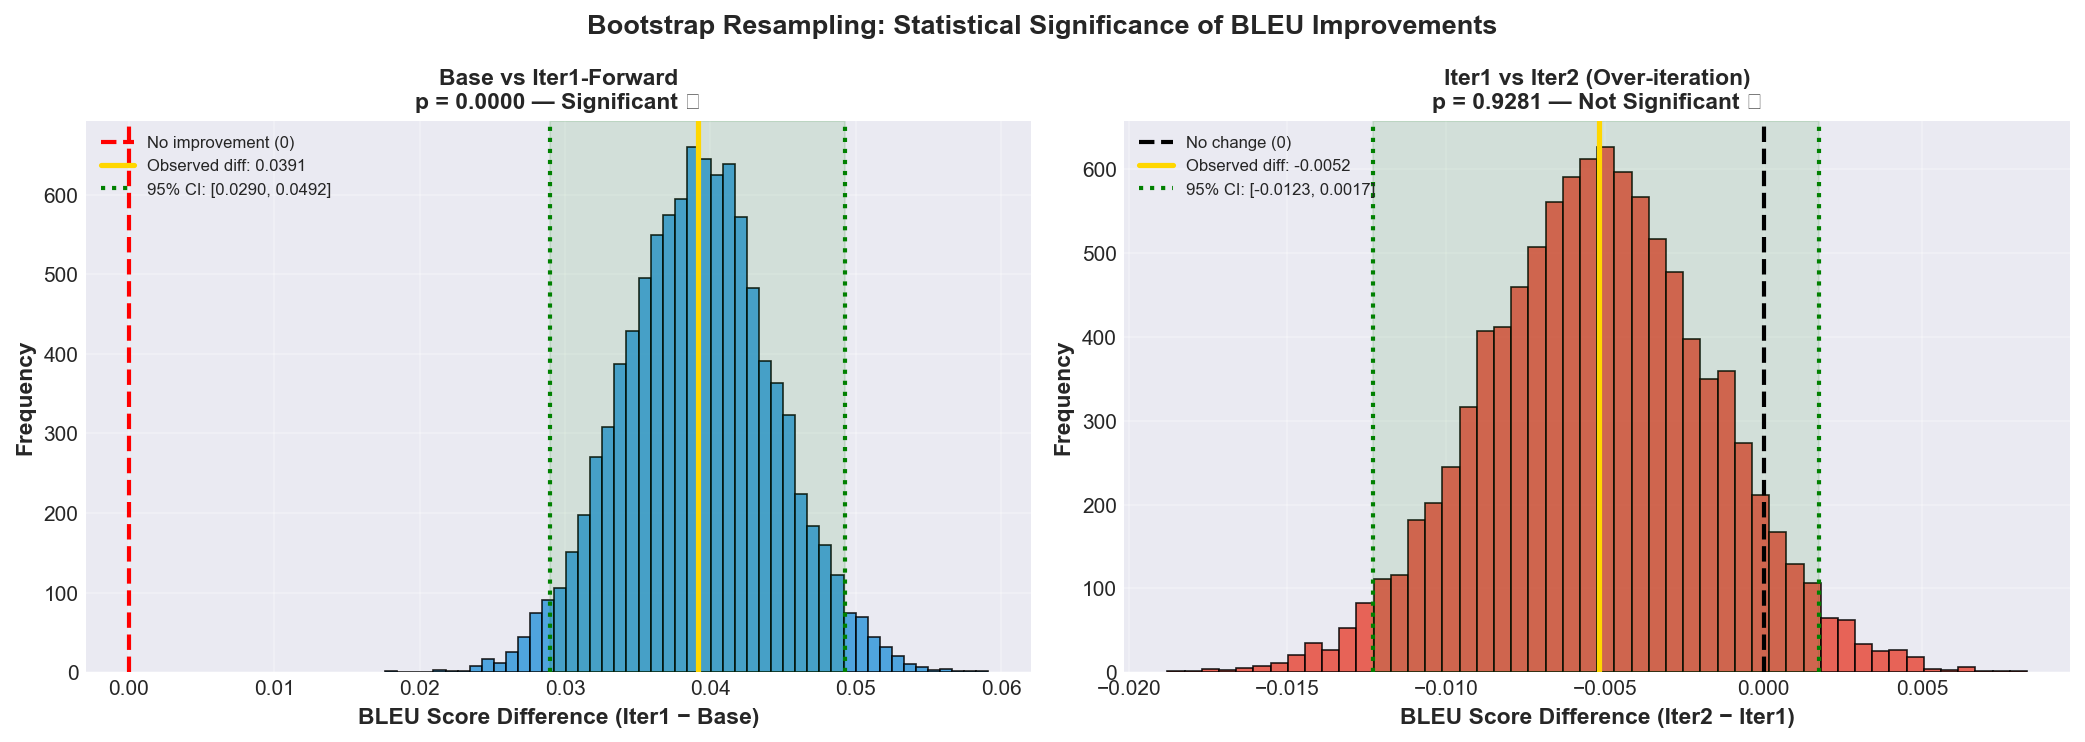


✓ Saved: ./outputs/thesis_plots/bootstrap_significance.png


In [60]:
# ═══════════════════════════════════════════════════════════════
# BOOTSTRAP RESAMPLING: Statistical Significance Testing
# ═══════════════════════════════════════════════════════════════
import numpy as np
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 150

def bootstrap_bleu_significance(predictions_a, predictions_b, references, n_bootstrap=10000, seed=42):
    np.random.seed(seed)
    n_samples = len(predictions_a)
    smoothie = SmoothingFunction().method1

    scores_a = [
        sentence_bleu([ref.split()], pred.split(), smoothing_function=smoothie)
        for pred, ref in zip(predictions_a, references)
    ]
    scores_b = [
        sentence_bleu([ref.split()], pred.split(), smoothing_function=smoothie)
        for pred, ref in zip(predictions_b, references)
    ]

    observed_diff = np.mean(scores_b) - np.mean(scores_a)
    print(f"  Observed mean score difference: {observed_diff:.4f}")

    bootstrap_diffs = []
    for _ in range(n_bootstrap):
        indices = np.random.choice(n_samples, size=n_samples, replace=True)
        boot_a = np.mean([scores_a[i] for i in indices])
        boot_b = np.mean([scores_b[i] for i in indices])
        bootstrap_diffs.append(boot_b - boot_a)

    bootstrap_diffs = np.array(bootstrap_diffs)
    p_value = np.mean(bootstrap_diffs <= 0)
    ci_lower = np.percentile(bootstrap_diffs, 2.5)
    ci_upper = np.percentile(bootstrap_diffs, 97.5)

    print(f"  Bootstrap p-value: {p_value:.4f}")
    print(f"  95% CI on improvement: [{ci_lower:.4f}, {ci_upper:.4f}]")

    if p_value < 0.05:
        print(f"  ✓ Result is statistically significant (p < 0.05)")
    else:
        print(f"  ⚠ Result is NOT statistically significant (p = {p_value:.4f})")

    return p_value, ci_lower, ci_upper, bootstrap_diffs, observed_diff


assert 'base_predictions' in locals() and base_predictions is not None, \
    "base_predictions not found — run base model eval cell first"
assert 'predictions_iter2_intermediate' in locals() and predictions_iter2_intermediate is not None, \
    "predictions_iter2_intermediate not found — run Iter2 eval cell first"
assert 'predictions_iter3_final' in locals() and predictions_iter3_final is not None, \
    "predictions_iter3_final not found — run Iter3 eval cell first"

references_flat = test_data['bn'].tolist()

print("="*70)
print("BOOTSTRAP RESAMPLING: Base Model vs Iter1-Forward (Best)")
print("="*70)
p_val, ci_low, ci_high, boot_diffs, observed_diff = bootstrap_bleu_significance(
    predictions_a=base_predictions,
    predictions_b=predictions_iter2_intermediate,
    references=references_flat,
    n_bootstrap=10000
)

print("\n" + "="*70)
print("BOOTSTRAP RESAMPLING: Iter1-Forward vs Iter2-Forward (over-iteration)")
print("="*70)
p_val_iter, ci_low_iter, ci_high_iter, boot_diffs_iter, observed_diff_iter = bootstrap_bleu_significance(
    predictions_a=predictions_iter2_intermediate,
    predictions_b=predictions_iter3_final,
    references=references_flat,
    n_bootstrap=10000
)

print("\n" + "="*70)
print("BOOTSTRAP SUMMARY")
print("="*70)
print(f"  Base vs Iter1 (Best):  p={p_val:.4f}  CI=[{ci_low:.4f}, {ci_high:.4f}]  diff={observed_diff:.4f}")
print(f"  Iter1 vs Iter2:        p={p_val_iter:.4f}  CI=[{ci_low_iter:.4f}, {ci_high_iter:.4f}]  diff={observed_diff_iter:.4f}")

# ── Bootstrap Significance Plots ──
plt.close('all')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Bootstrap Resampling: Statistical Significance of BLEU Improvements',
             fontsize=13, fontweight='bold')

ax1 = axes[0]
ax1.hist(boot_diffs, bins=50, color='#3498db', edgecolor='black',
         linewidth=0.8, alpha=0.85)
ax1.axvline(x=0, color='red', linestyle='--', linewidth=2, label='No improvement (0)')
ax1.axvline(x=observed_diff, color='gold', linestyle='-', linewidth=2.5,
            label=f'Observed diff: {observed_diff:.4f}')
ax1.axvline(x=ci_low, color='green', linestyle=':', linewidth=2,
            label=f'95% CI: [{ci_low:.4f}, {ci_high:.4f}]')
ax1.axvline(x=ci_high, color='green', linestyle=':', linewidth=2)
ax1.axvspan(ci_low, ci_high, alpha=0.1, color='green')
ax1.set_xlabel('BLEU Score Difference (Iter1 − Base)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax1.set_title(
    f'Base vs Iter1-Forward\np = {p_val:.4f} — {"Significant ✓" if p_val < 0.05 else "Not Significant ✗"}',
    fontsize=11, fontweight='bold')
ax1.legend(fontsize=8, loc='upper left')
ax1.grid(True, alpha=0.3)
ax1.set_axisbelow(True)

ax2 = axes[1]
ax2.hist(boot_diffs_iter, bins=50, color='#e74c3c', edgecolor='black',
         linewidth=0.8, alpha=0.85)
ax2.axvline(x=0, color='black', linestyle='--', linewidth=2, label='No change (0)')
ax2.axvline(x=observed_diff_iter, color='gold', linestyle='-', linewidth=2.5,
            label=f'Observed diff: {observed_diff_iter:.4f}')
ax2.axvline(x=ci_low_iter, color='green', linestyle=':', linewidth=2,
            label=f'95% CI: [{ci_low_iter:.4f}, {ci_high_iter:.4f}]')
ax2.axvline(x=ci_high_iter, color='green', linestyle=':', linewidth=2)
ax2.axvspan(ci_low_iter, ci_high_iter, alpha=0.1, color='green')
ax2.set_xlabel('BLEU Score Difference (Iter2 − Iter1)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax2.set_title(
    f'Iter1 vs Iter2 (Over-iteration)\np = {p_val_iter:.4f} — {"Significant ✓" if p_val_iter < 0.05 else "Not Significant ✗"}',
    fontsize=11, fontweight='bold')
ax2.legend(fontsize=8, loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.set_axisbelow(True)

plt.tight_layout()
plt.savefig('./outputs/thesis_plots/bootstrap_significance.png', 
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"\n✓ Saved: ./outputs/thesis_plots/bootstrap_significance.png")